In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.nn import functional as F
from torchvision import datasets, transforms

import matplotlib.pyplot as plt

# CSC_51054_EP: Lab 3

# Convolutional Neural Networks

In this lab we will learn how to build and use Convolutional Neural Networks in PyTorch to classify images.

For our first exercises, we will use the MNIST dataset (Modified National Institute of Standards and Technology dataset) is one of the most famous benchmark datasets in machine learning and computer vision.

It is mainly used for training and testing image processing systems, especially in the context of handwritten digit recognition. It contains 70,000 grayscale images of handwritten digits (0–9). Each image is 28 × 28 pixels (784 features if flattened into a vector). Pixel values range from 0 (white) to 255 (black).

Splits: 60,000 training images and 10,000 test images.

Each image is associated with a label (0 through 9), indicating the digit shown.

Let's start by loading the dataset:

In [2]:
input_size  = 28*28   # images are 28x28 pixels
output_size = 10      # there are 10 classes

transform=transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,))
        ])

dataset_tr = datasets.MNIST('./data', train=True, download=True, transform=transform) #Change download to False once you download the dataset the first time
dataset_te = datasets.MNIST('./data', train=False, transform=transform)

train_loader = torch.utils.data.DataLoader(dataset_tr,batch_size=64,shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset_te, batch_size=1000,shuffle=True)

#load training data
images, labels = next(iter(train_loader))

Let's take a look at the data:

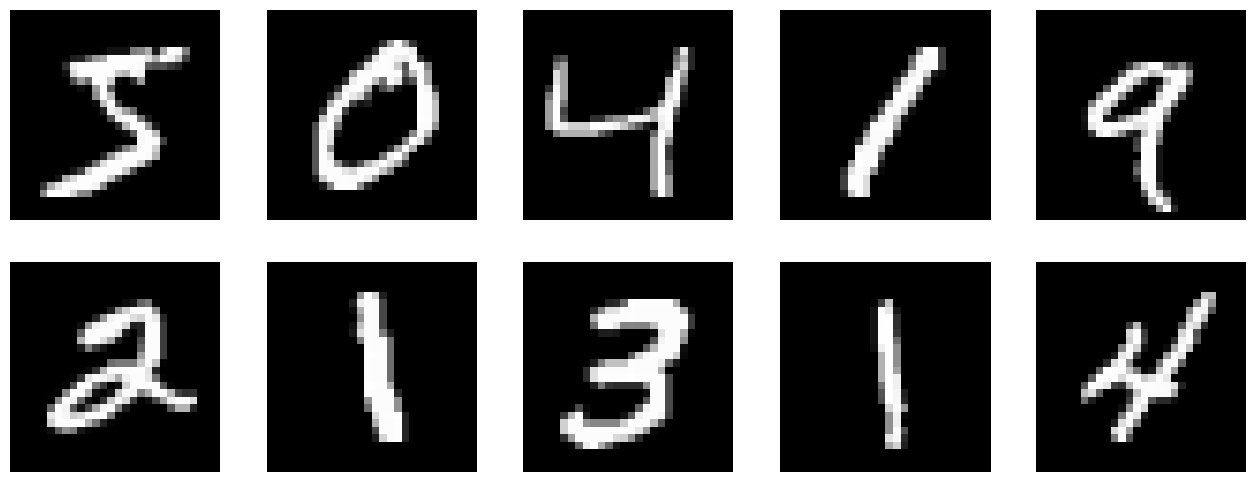

In [3]:
plt.figure(figsize=(16, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    image, _ = train_loader.dataset.__getitem__(i)
    plt.imshow(image.squeeze().numpy(), cmap='gray')
    plt.axis('off');

## A FCNN-based solution

> **Task 1**: implement using PyTorch a fully connected NN with 2 relu activation layers. Note that the image size is 28x28 but you will need to reshape it as a vector of 784 elements.

For the output layer, we will use log_softmax and for the loss, we will use the negative log-likelihood loss (nll_loss), both for numerical stability

In [4]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu") #if you have a GPU with CUDA installed, this may speed up computation

class FCNN(nn.Module):
    def __init__(self, input_size, n_hidden, output_size):
        super().__init__()
        #TODO: insert your code here
        self.input_size=input_size
        self.linear1=nn.Linear(input_size, n_hidden)
        self.linear2=nn.Linear(n_hidden, n_hidden)
        self.linear3=nn.Linear(n_hidden, output_size)

    def forward(self, x):
        #TODO: insert your code here
        #print("before view: ", x.size()) #[64, 1, 28, 28]
        x = x.view(-1, self.input_size)
        #print("after view: ", x.size()) #[64, 784]
        x = self.linear1(x)
        #print("after linear1: ", x.size())
        x = F.relu(x)
        x = self.linear2(x)
        x = F.relu(x)
        x = self.linear3(x)
        output = F.log_softmax(x, dim=1)
        
        return output

In [5]:

def train(model, device, train_loader, optimizer, epoch):
    log_interval=100
    model.train() #set model in train mode
    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        
        #TODO: introduce the loss here
        #loss = loss_function(output, target)
        loss = F.nll_loss(output, target)
        
        loss.backward()
        optimizer.step()
        if batch_idx % log_interval == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item()))

def test(model, device, test_loader):
    model.eval() #set model in test mode
    test_loss = 0
    correct = 0
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            test_loss += F.nll_loss(output, target, reduction='sum').item()  # sum up batch loss
            pred = output.argmax(dim=1, keepdim=True)  # get the index of the max log-probability
            correct += pred.eq(target.view_as(pred)).sum().item()

    test_loss /= len(test_loader.dataset)

    print('\nTest set: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
        test_loss, correct, len(test_loader.dataset),
        100. * correct / len(test_loader.dataset)))

Let's take a look at the loss and accuracy of our FCNN:

In [6]:
n_hidden = 16 # number of hidden units

model_fnn = FCNN(input_size, n_hidden, output_size)
model_fnn.to(device)
optimizer = torch.optim.SGD(model_fnn.parameters(), lr=0.01, momentum=0.5)

for epoch in range(0, 1):
    train(model_fnn, device, train_loader, optimizer, epoch)
    test(model_fnn, device, test_loader)

Train Epoch: 0 [0/60000 (0%)]	Loss: 2.344937
Train Epoch: 0 [6400/60000 (11%)]	Loss: 1.468719
Train Epoch: 0 [12800/60000 (21%)]	Loss: 0.929262
Train Epoch: 0 [19200/60000 (32%)]	Loss: 0.590957
Train Epoch: 0 [25600/60000 (43%)]	Loss: 0.381609
Train Epoch: 0 [32000/60000 (53%)]	Loss: 0.566143
Train Epoch: 0 [38400/60000 (64%)]	Loss: 0.306923
Train Epoch: 0 [44800/60000 (75%)]	Loss: 0.429002
Train Epoch: 0 [51200/60000 (85%)]	Loss: 0.490608
Train Epoch: 0 [57600/60000 (96%)]	Loss: 0.343130

Test set: Average loss: 0.3158, Accuracy: 9094/10000 (91%)



Let's see visualize how different units react to the input; in particular, the following code is useful to show the activations of each unit with respect to the input class. We are going to look in particular into the output of layer 3.

A note about how LayerActivations works: it is based on pytorch *hooks*. Hooks are used for inspecting / modifying the output and the gradients of a layer. Hooks can be registered on a Module or a Tensor.The hook can be a forward hook or a backward hook. The forward hook will be executed when a forward call is executed. The backward hook will be executed in the backward phase. In our case we use a forward hook to visualize the output of a layer.

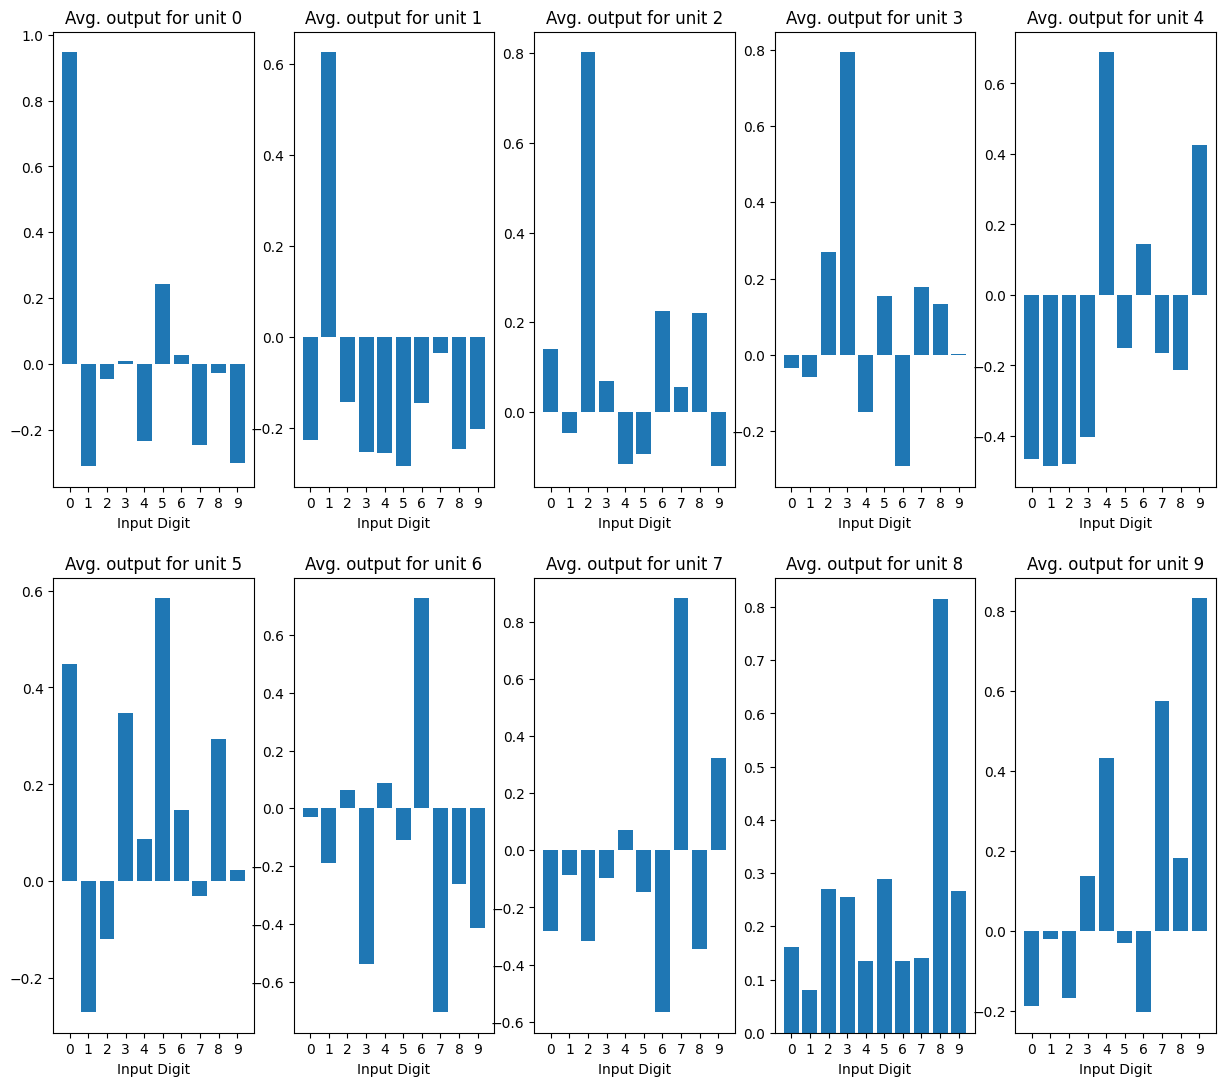

In [7]:
class LayerActivations():
    #to look into the layers and register the activation values
    features=None #the activation values
    
    def __init__ (self, model_layer: nn.Module):
        #model_layer: the layer to be monitored
        self.hook = model_layer.register_forward_hook(self.hook_fn)
    
    def hook_fn(self,module,input,output: torch.Tensor):
        self.features = output.cpu()
        
    def remove(self): #call this once you've read the values
        self.hook.remove()

def getActivations(model, model_layer, images):
    """Input:
      model: (nn.Module) the model from which we need to visualize layers
      model_layer: (nn.Module) the layer to be visualized
      images: tensor of size [n_images, channel, img_x, img_y]
    Output:
      activations
    """
    conv_out = LayerActivations(model_layer)
    o = model(images)
    act = conv_out.features
    conv_out.remove()
    return act

for images, targets in test_loader:
    n_units=10
    act=getActivations(model_fnn, model_fnn.linear3, images.to(device))
    
    M=torch.zeros([n_units, 10, 1000], dtype=torch.float32)
    for u in range(n_units):
        for i in range(1000):
            M[u][targets[i].data][i]=act[i][u].item()
    
    A=torch.mean(M, dim=2)
    
    plt.figure(figsize=(15,13))
    for i in range(n_units):
        plt.subplot(2, 5, i + 1)
        plt.bar(x=np.arange(10), height=A[i].numpy())
        plt.ylim=(-1.5, 1.5)
        plt.xticks(np.arange(10))
        plt.xlabel("Input Digit")
        plt.title("Avg. output for unit "+str(i))
    
    plt.show()
    break #no need to go further, we are testing so the activations won't change
    

## Convolutional Neural Networks

Let's see if we can do better: with images, convolutional layers are more efficient than Dense layers since they can capture local information in the images. See also <a href="https://stanford.edu/~shervine/teaching/cs-230/cheatsheet-convolutional-neural-networks">this page</a> for a more complete overview of CNNs.

>**Task 2:** implement a CNN with 2 <a href="https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html">convolutional layers</a> each followed by a <a href="https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html">max pooling</a> layer (kernel_size=2). Complete the network with 2 fully connected layers, where the final layer has 50 input units (and 10 outputs, one for each class). Kernel size for the convolutional layers will be 5.

If you use the default options for stride (1) and padding (0), the image width and height after each convolution will change as follows: $W'=W-(K-1)$, where $K$ stands for the kernel size.



In [8]:
class CNN(nn.Module):
    def __init__(self, input_size, n_feature, output_size):
        super().__init__()
        #insert your code here
        K=5
        self.n_feature=n_feature
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=n_feature, kernel_size=K)
        self.conv2 = nn.Conv2d(n_feature, n_feature, kernel_size=K)
        self.fc1 = nn.Linear(n_feature*16, 50)
        self.fc2 = nn.Linear(50, 10)
        
    def forward(self, x, verbose=False):
        #initial dimensions for x will be [64, 1, 28, 28]
        #insert your code here
        x = self.conv1(x) #[64, 6, 24, 24]
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2) #[64, 6, 12, 12]
        x = self.conv2(x) #[64,6, 8, 8]
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2) #[64, 6, 4, 4]
        x = x.view(-1, self.n_feature*16)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        output = F.log_softmax(x, dim=1)
        
        return output

In [9]:
# Training settings 
n_features = 6 # number of feature maps

model_cnn = CNN(input_size, n_features, output_size)
model_cnn.to(device)
optimizer = torch.optim.SGD(model_cnn.parameters(), lr=0.01, momentum=0.5)

for epoch in range(0, 1):
    train(model_cnn, device, train_loader, optimizer, epoch)
    test(model_cnn, device, test_loader)

Train Epoch: 0 [0/60000 (0%)]	Loss: 2.347473
Train Epoch: 0 [6400/60000 (11%)]	Loss: 2.150218
Train Epoch: 0 [12800/60000 (21%)]	Loss: 0.656226
Train Epoch: 0 [19200/60000 (32%)]	Loss: 0.561469
Train Epoch: 0 [25600/60000 (43%)]	Loss: 0.557941
Train Epoch: 0 [32000/60000 (53%)]	Loss: 0.162527
Train Epoch: 0 [38400/60000 (64%)]	Loss: 0.227395
Train Epoch: 0 [44800/60000 (75%)]	Loss: 0.166739
Train Epoch: 0 [51200/60000 (85%)]	Loss: 0.220224
Train Epoch: 0 [57600/60000 (96%)]	Loss: 0.182695

Test set: Average loss: 0.1663, Accuracy: 9484/10000 (95%)



Let's visualize the feature maps for the two convolution layers using the `getActivations` function that we introduced above:

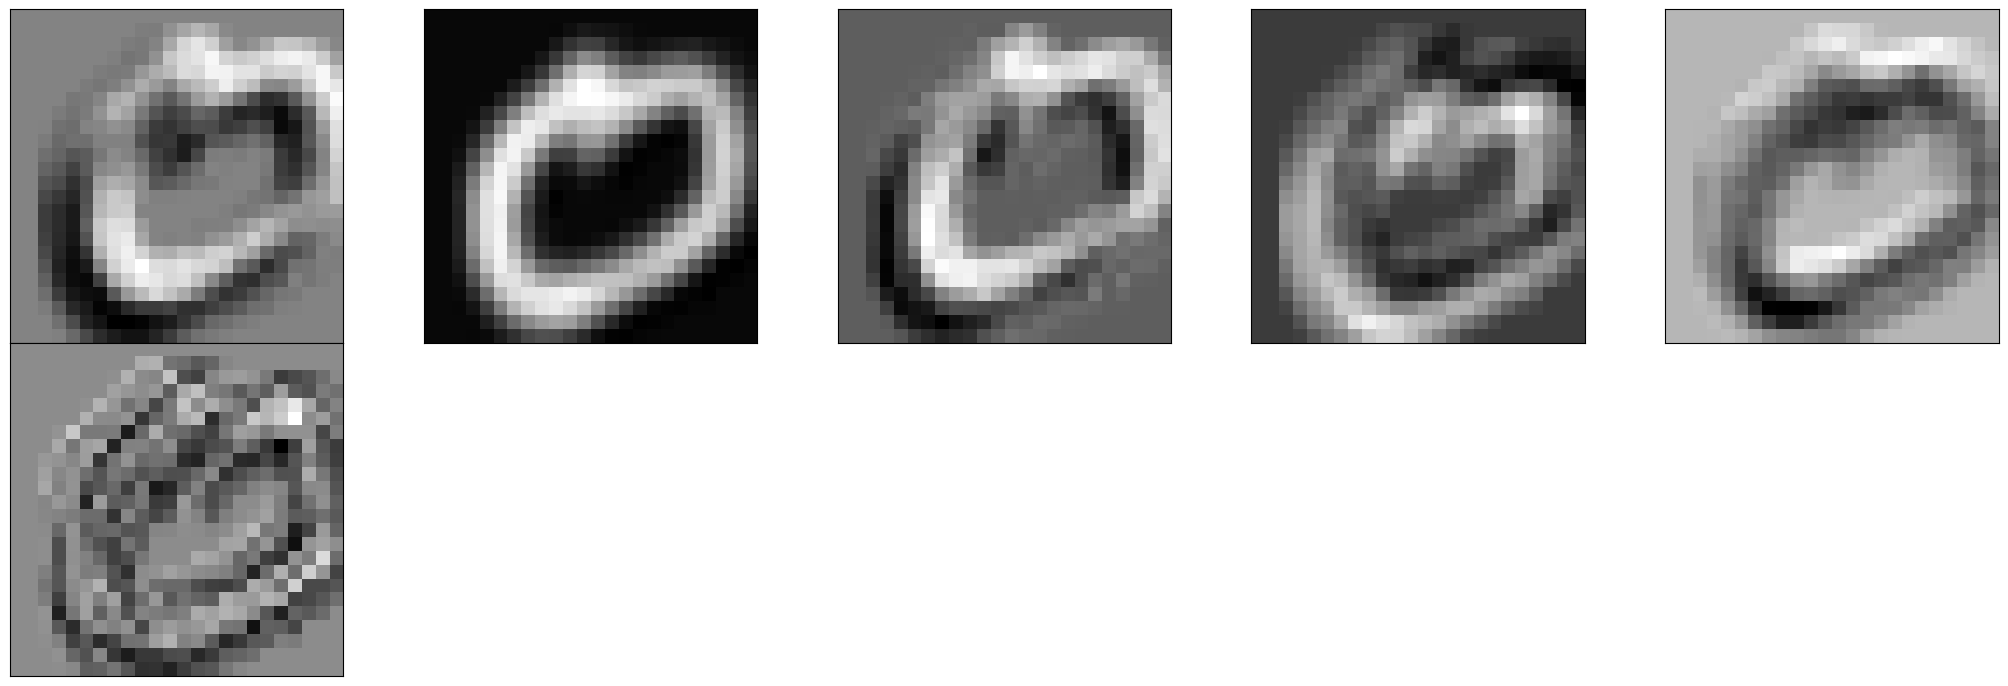

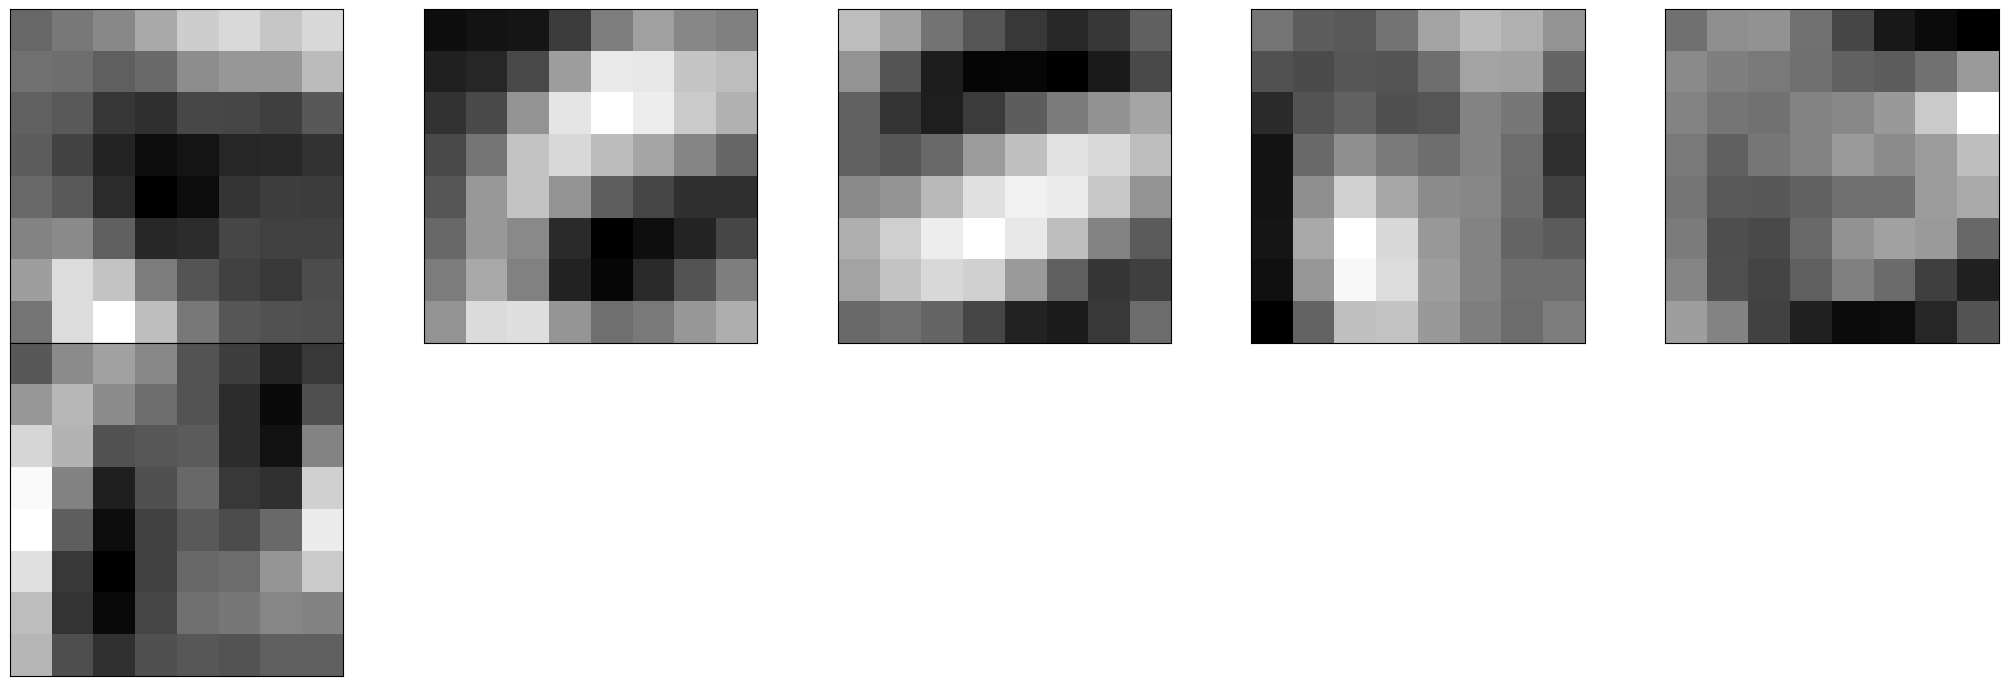

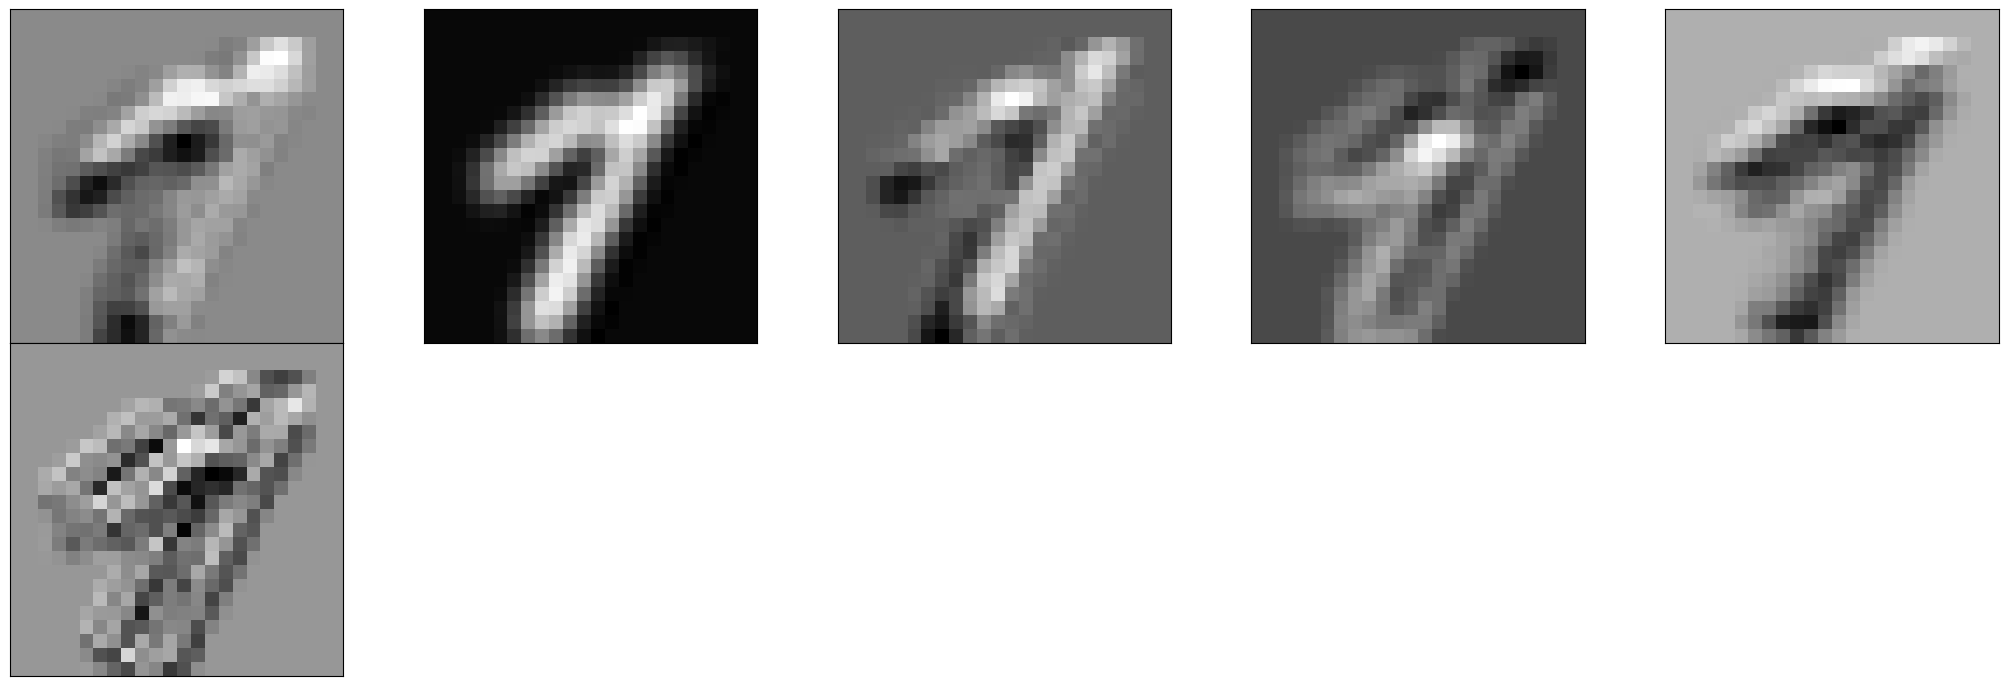

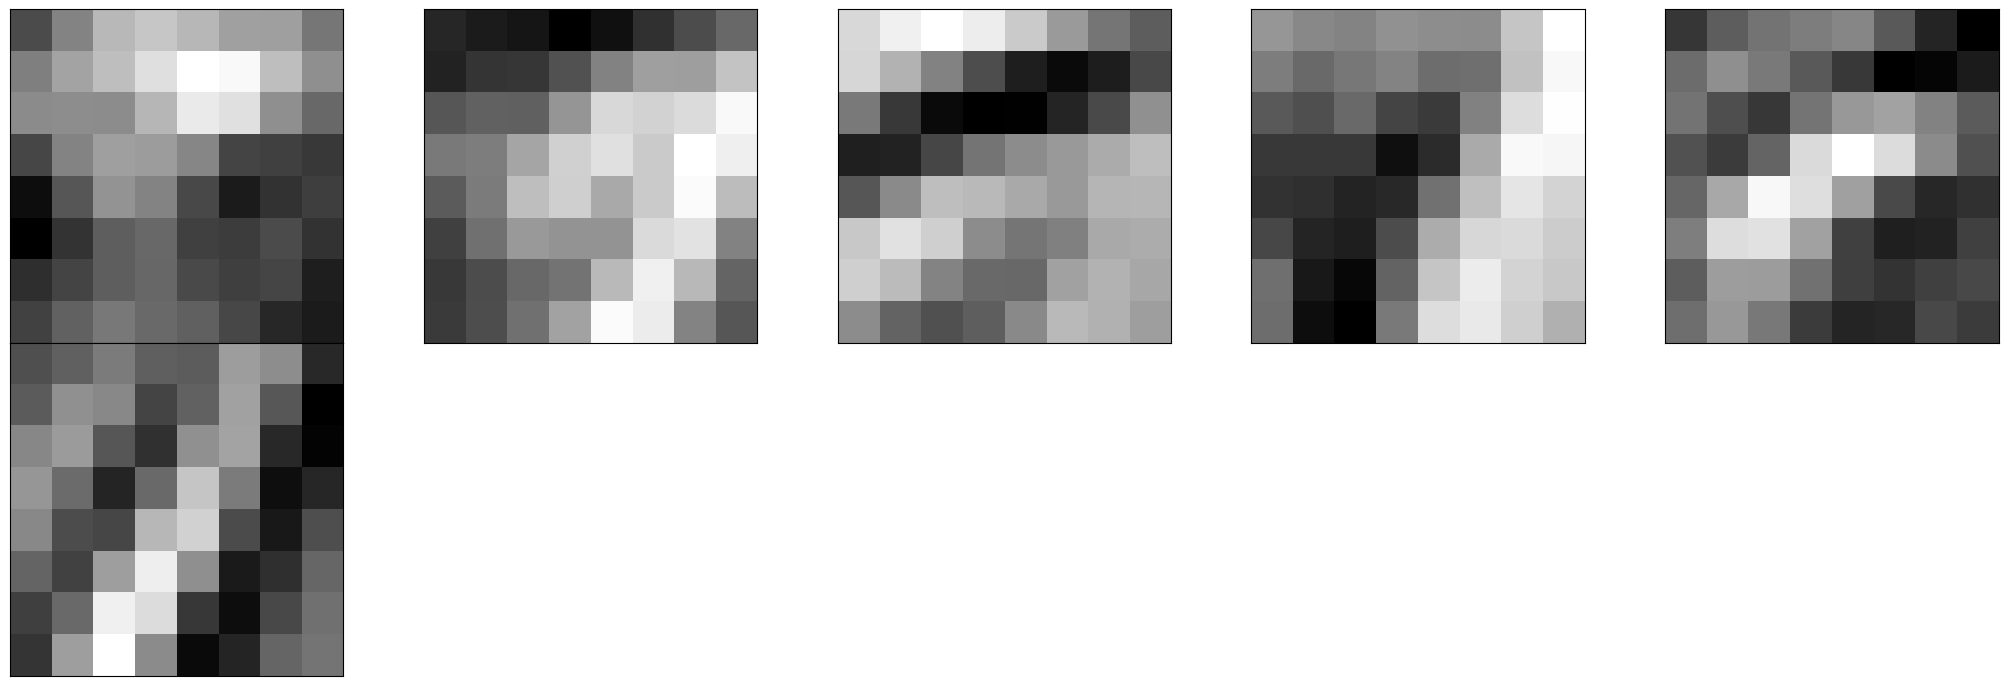

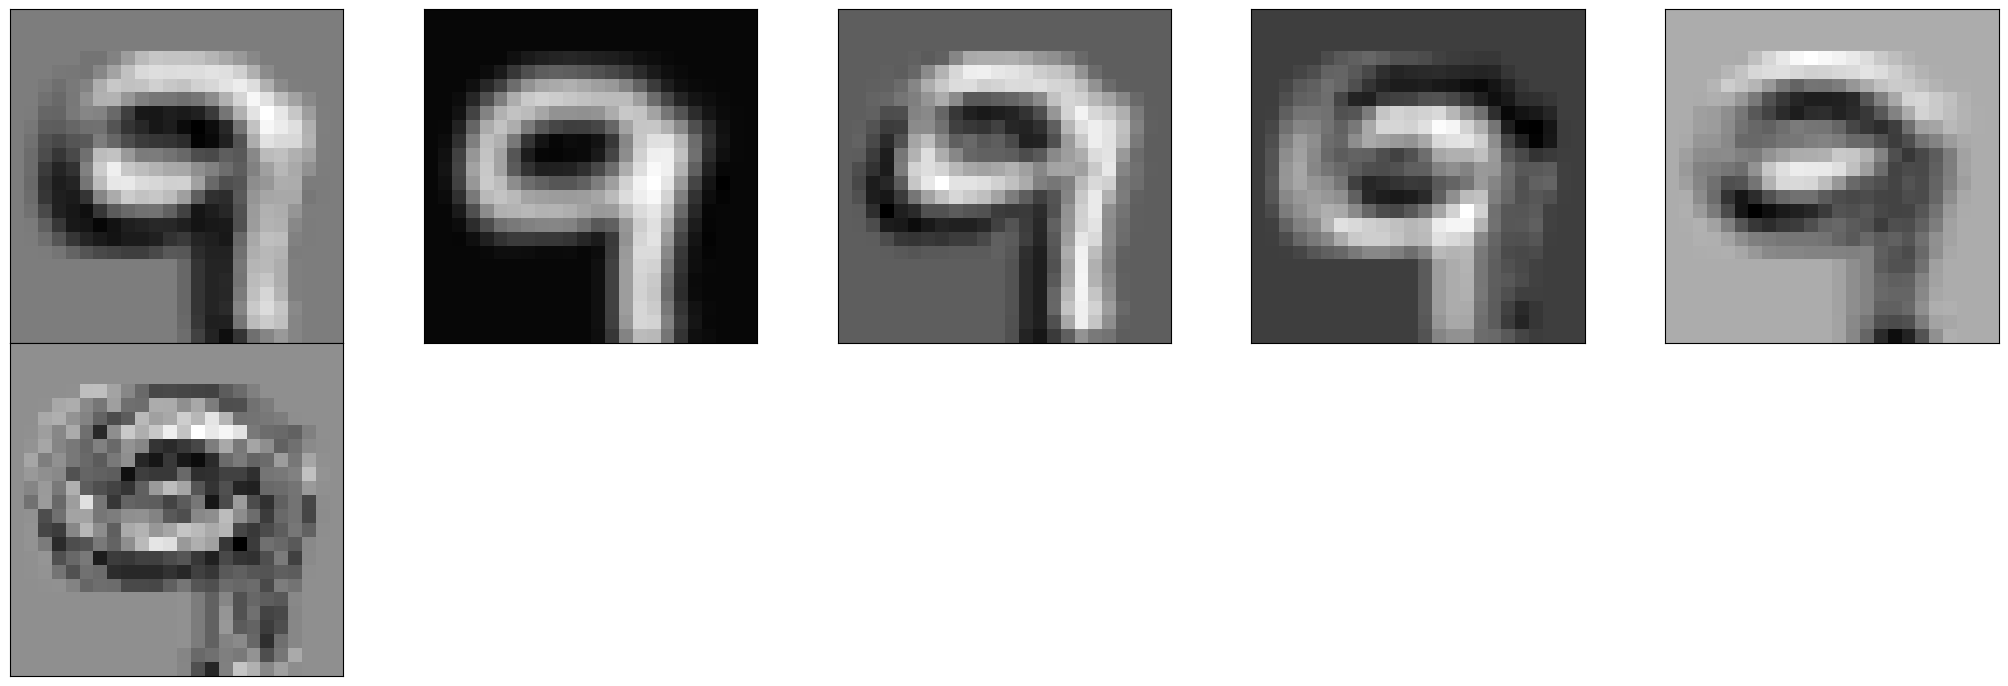

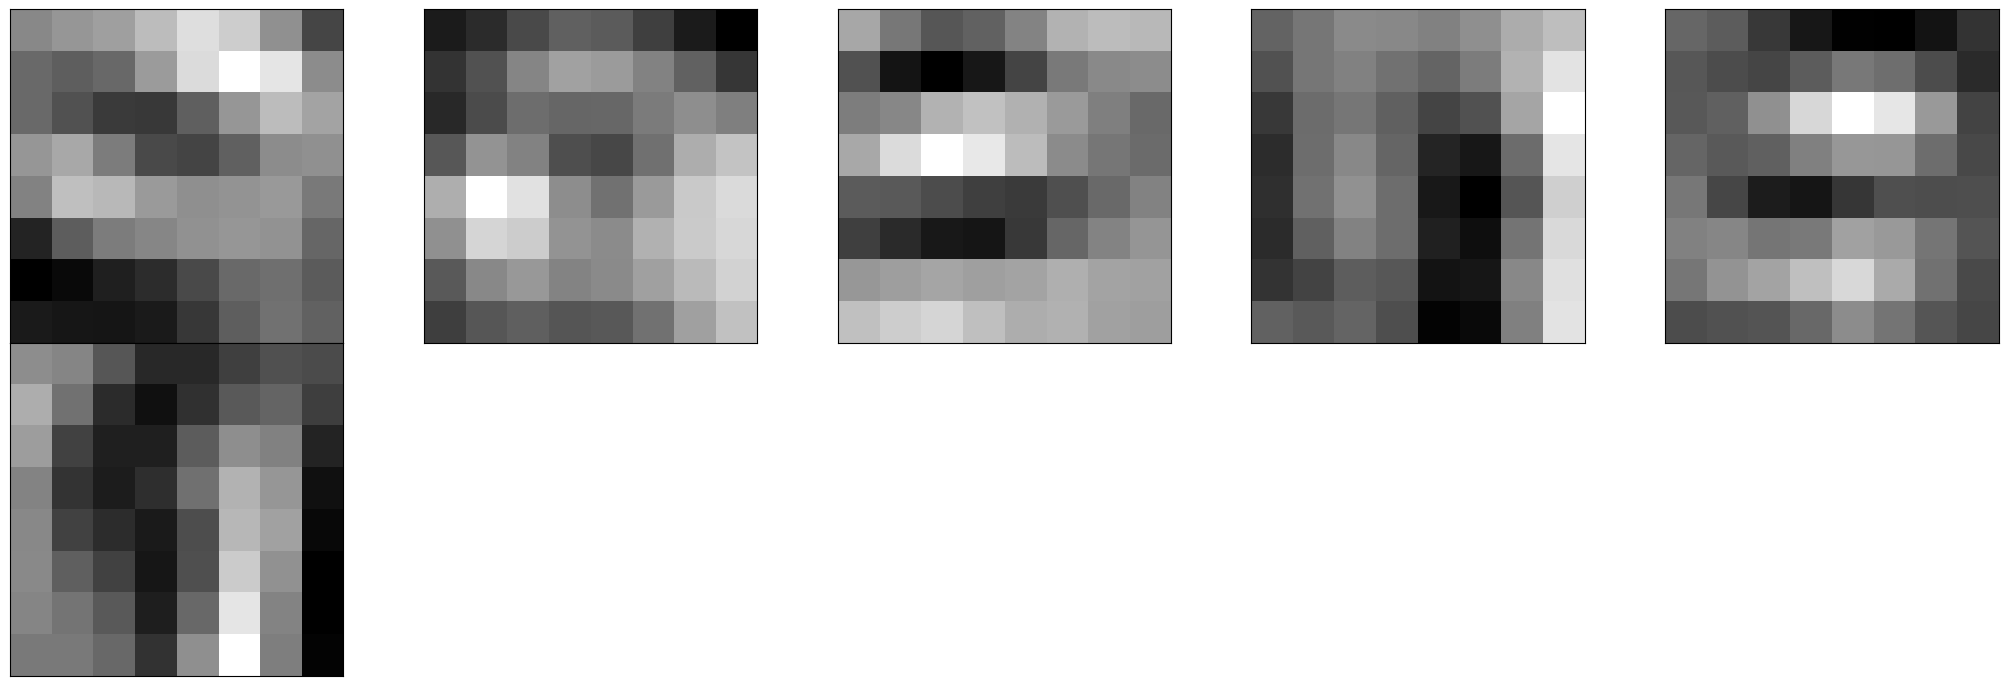

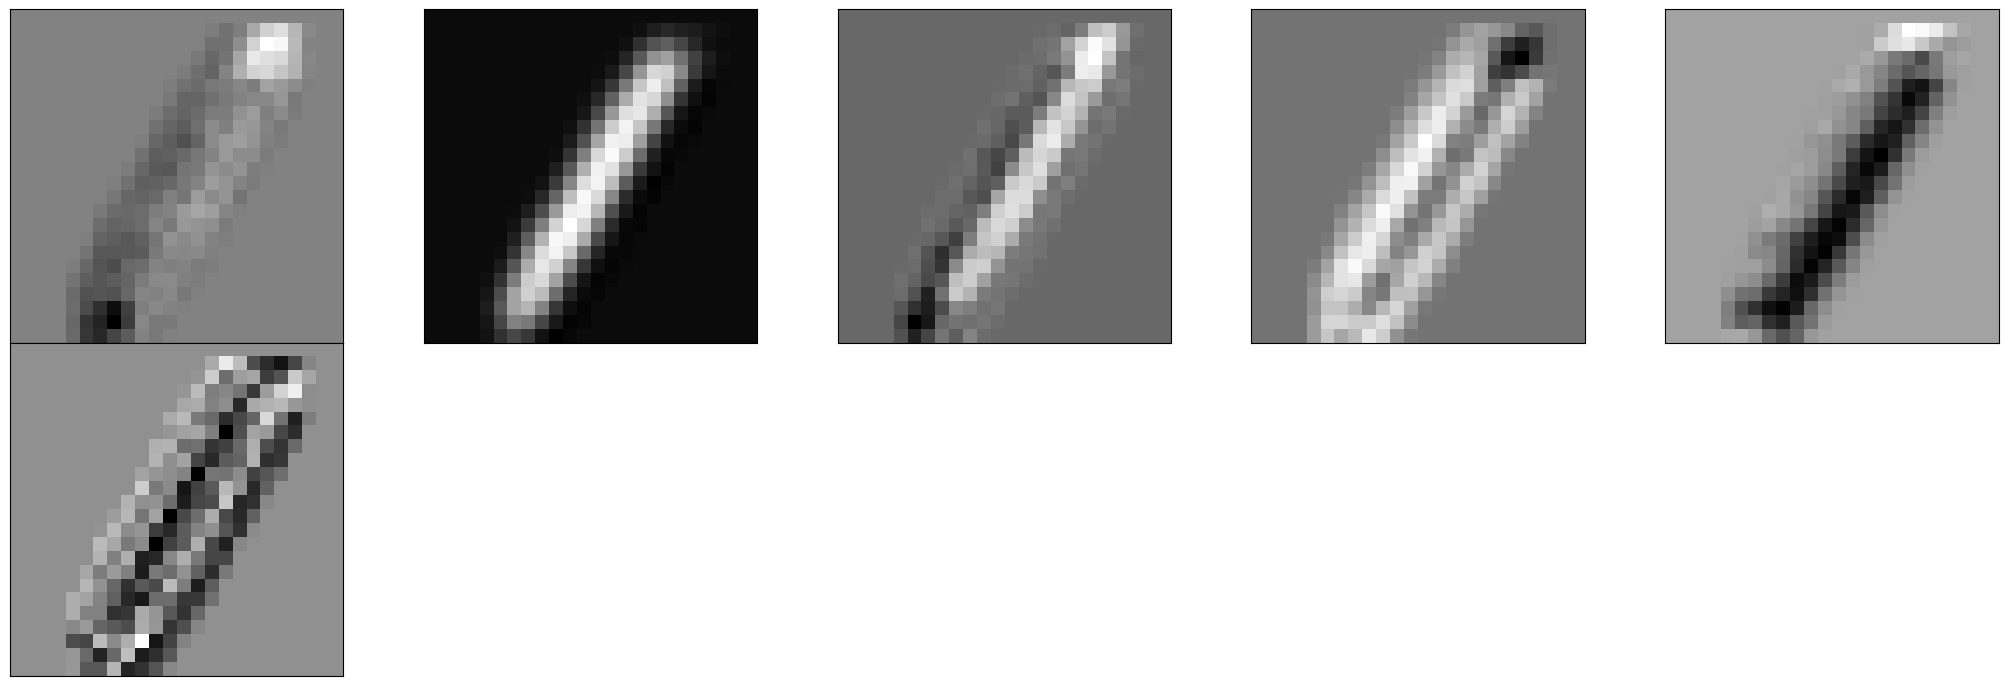

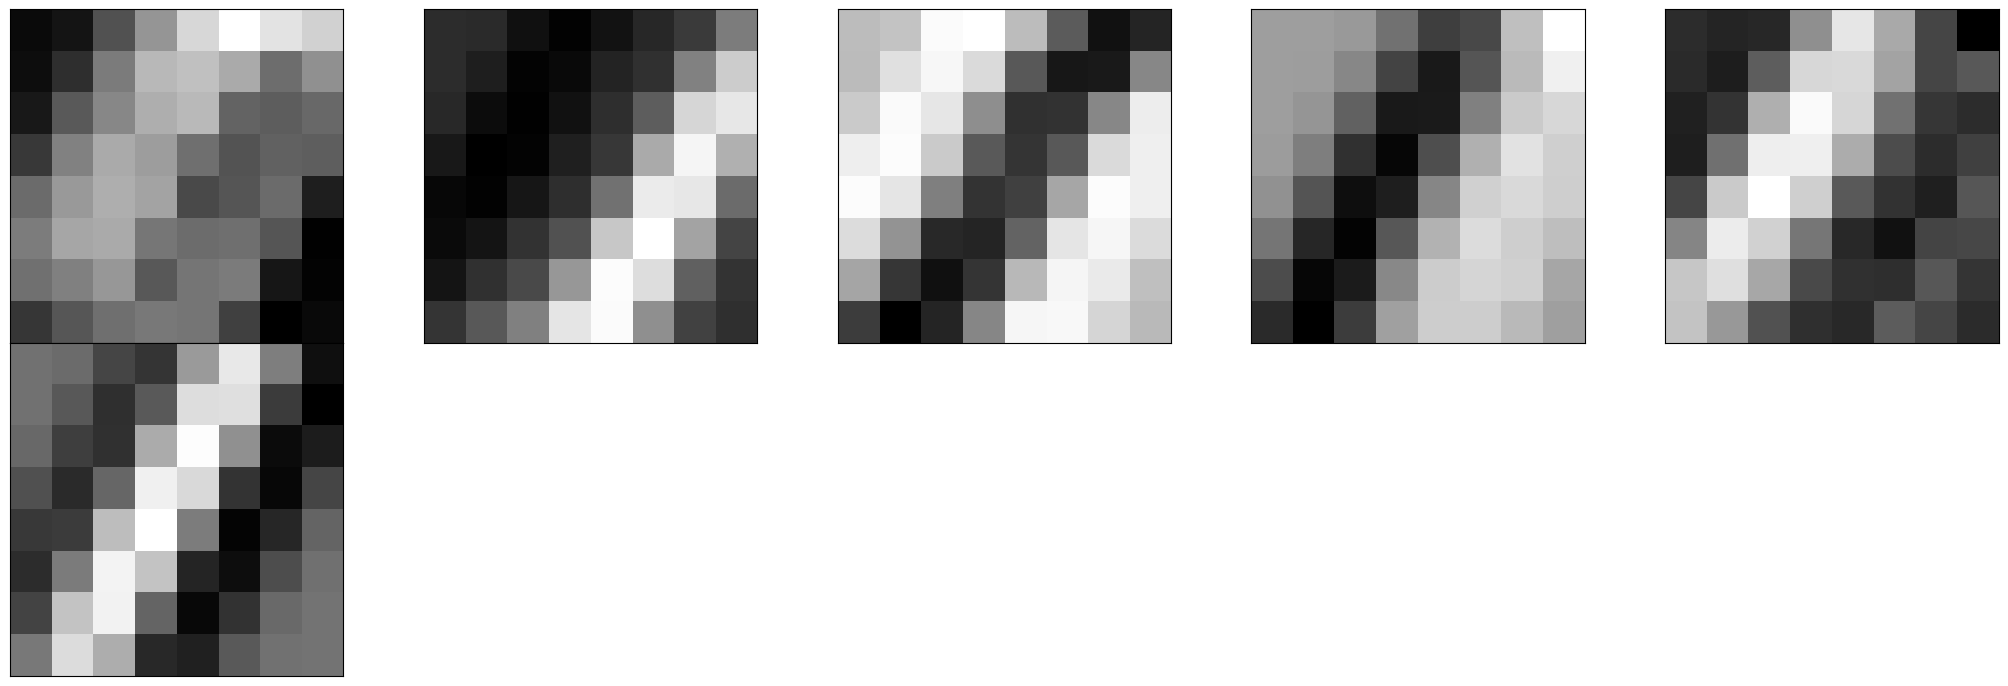

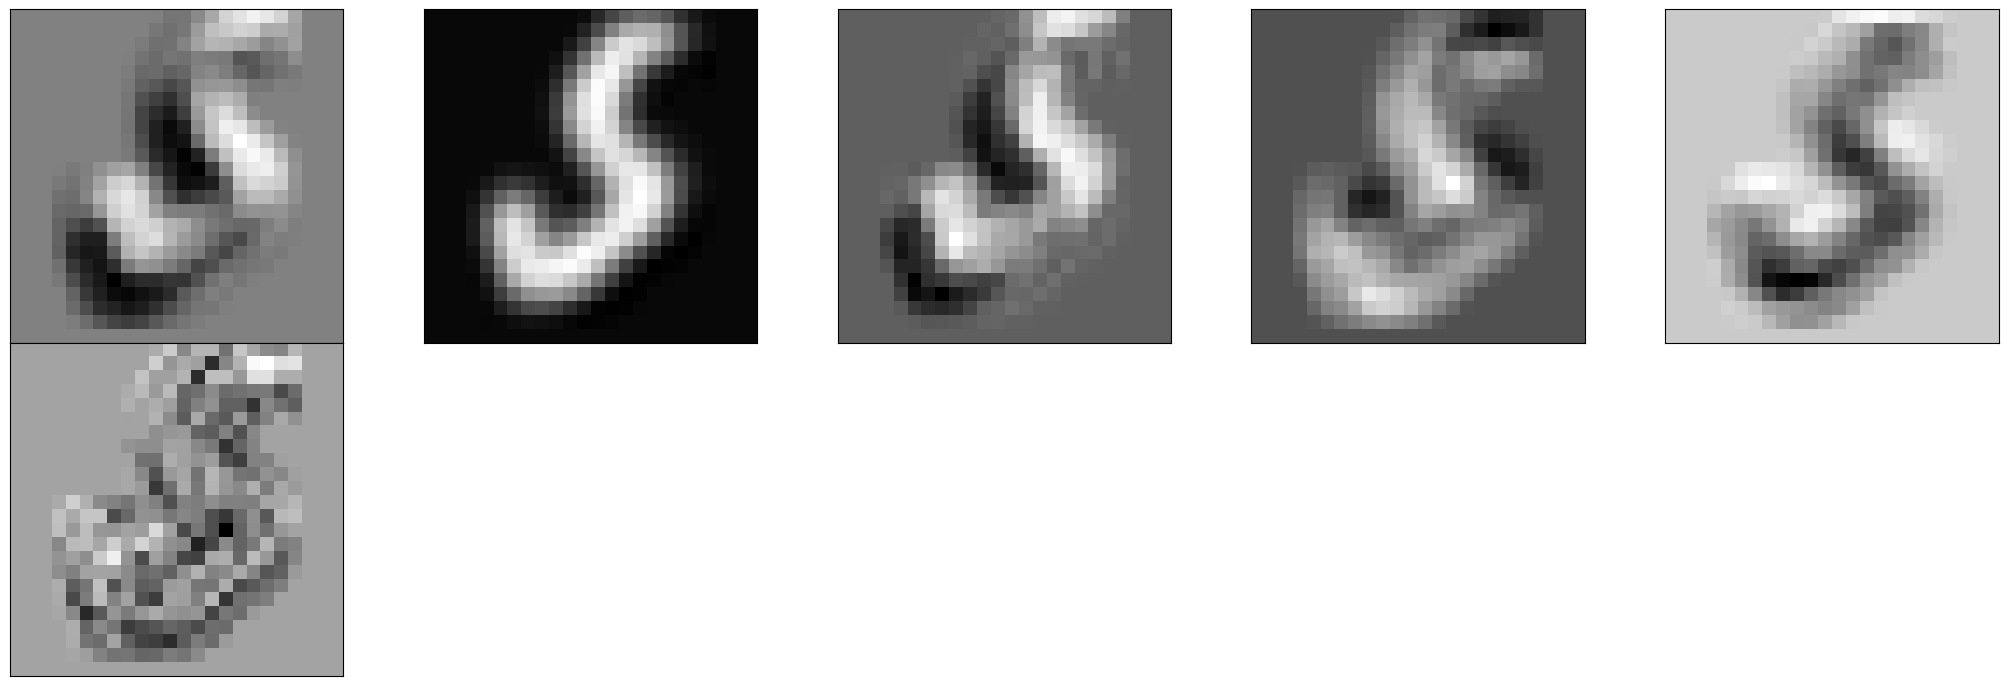

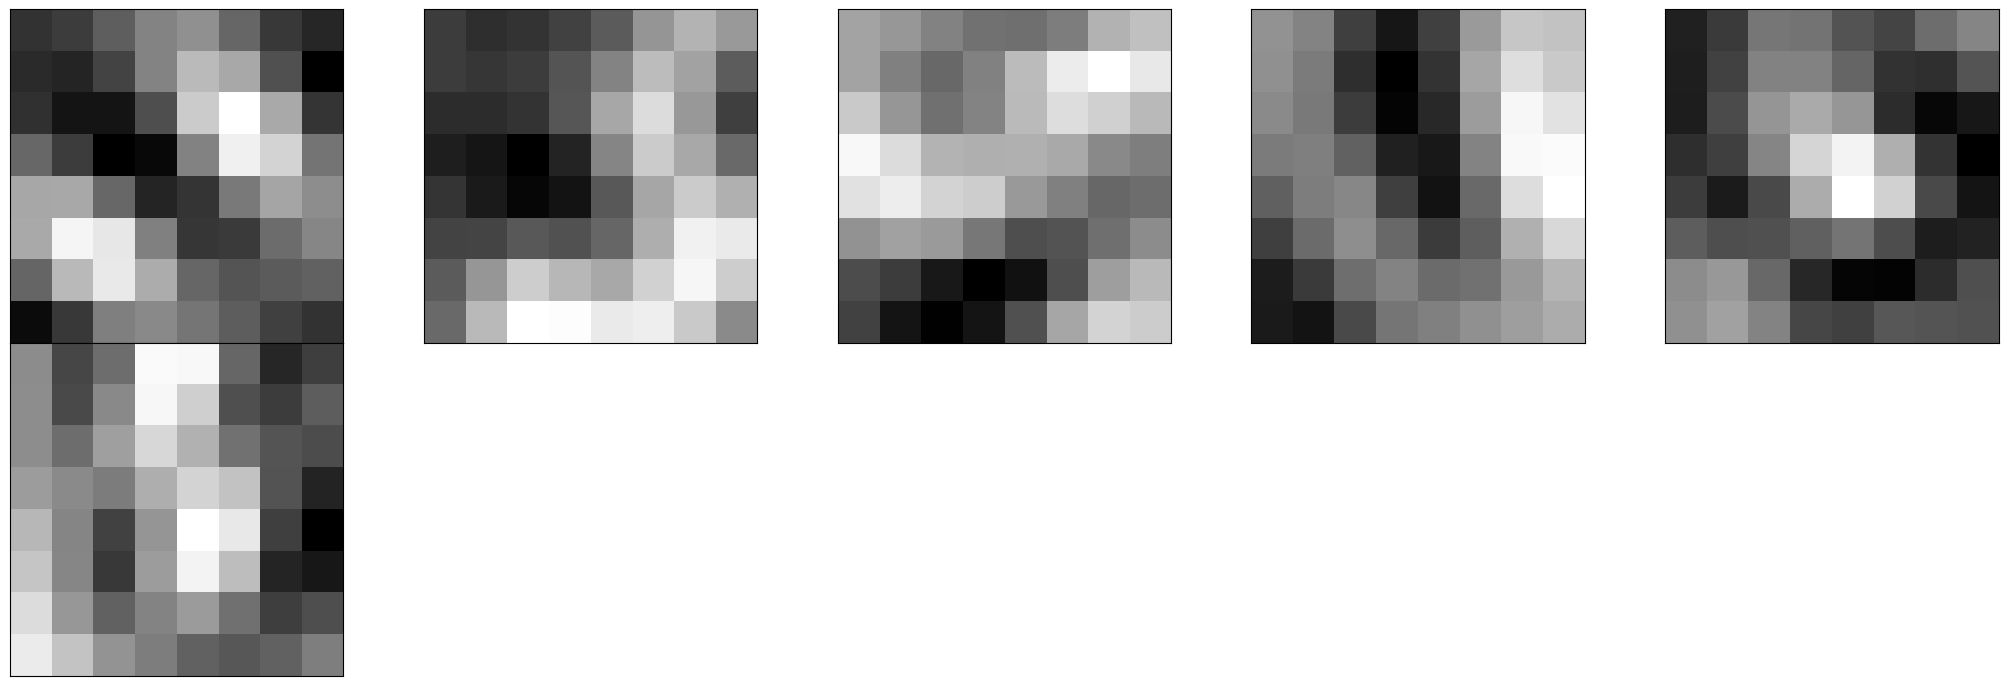

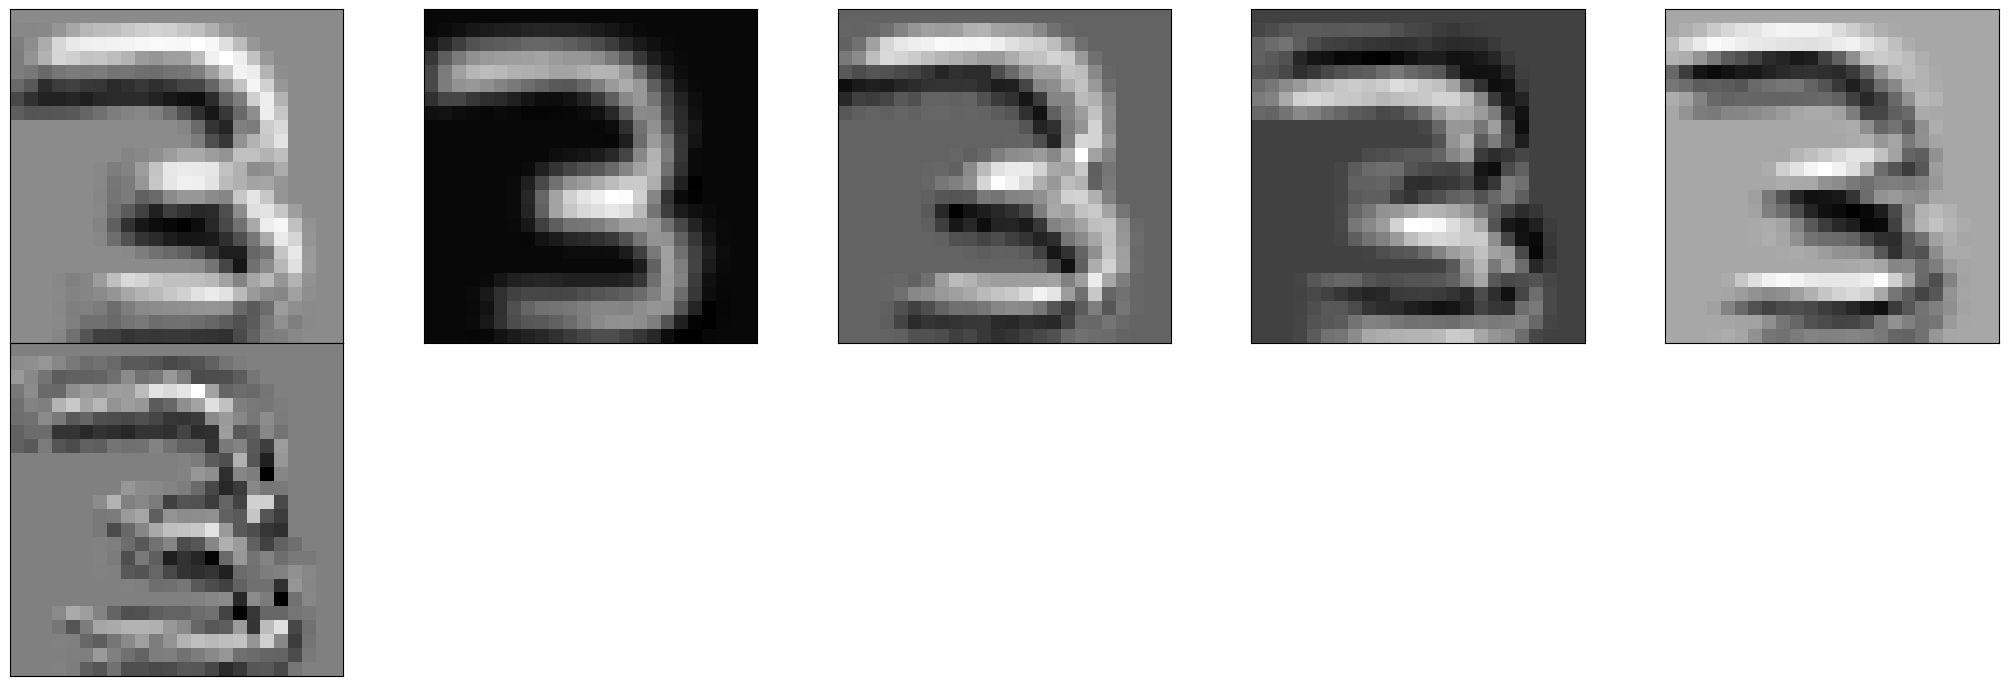

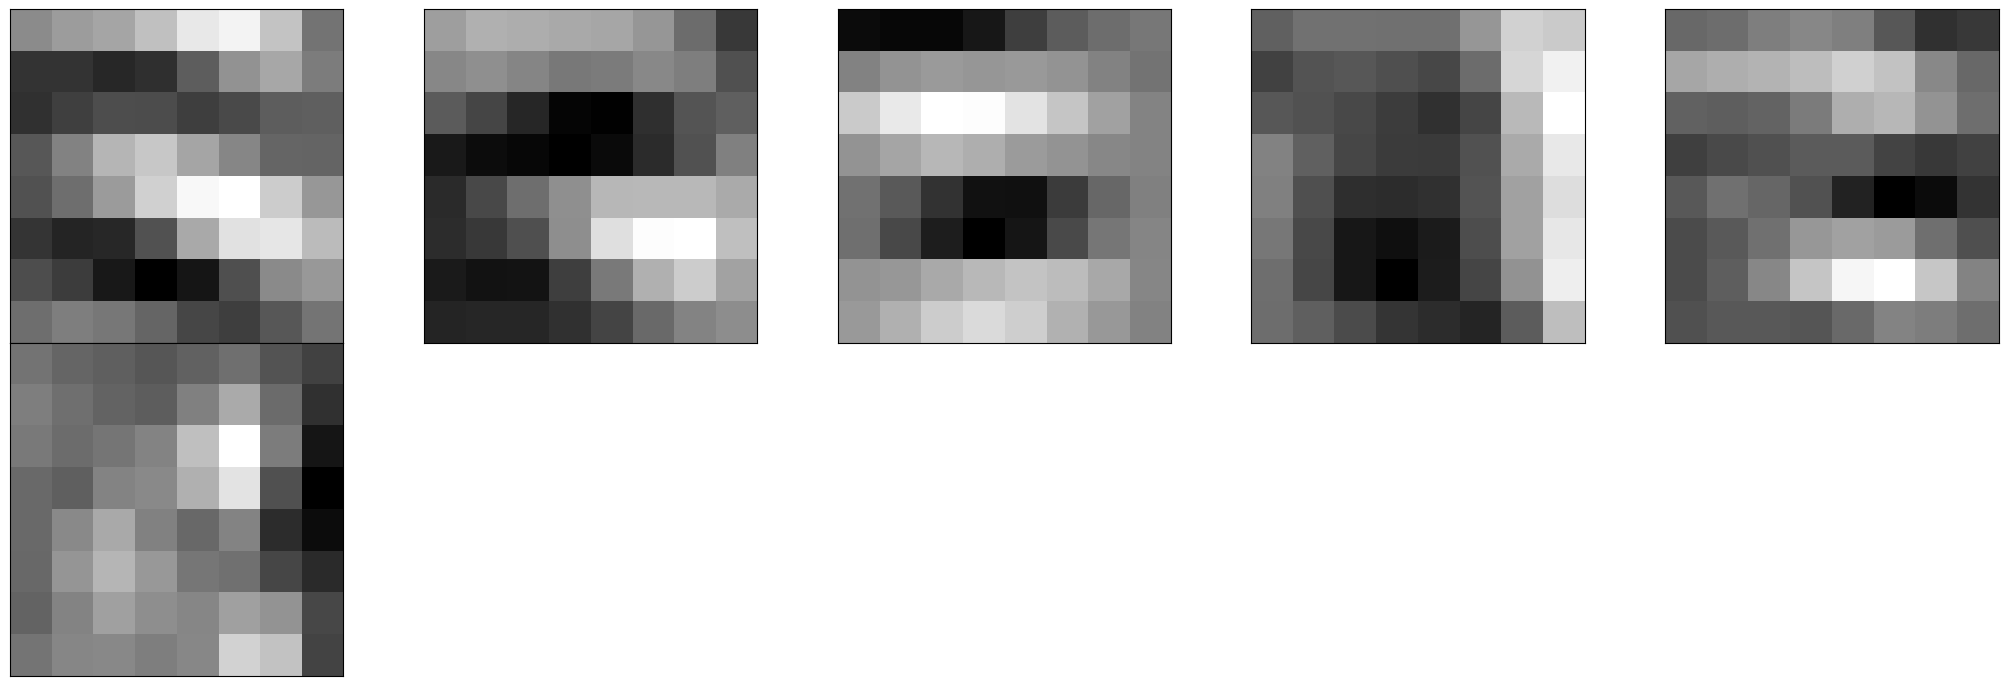

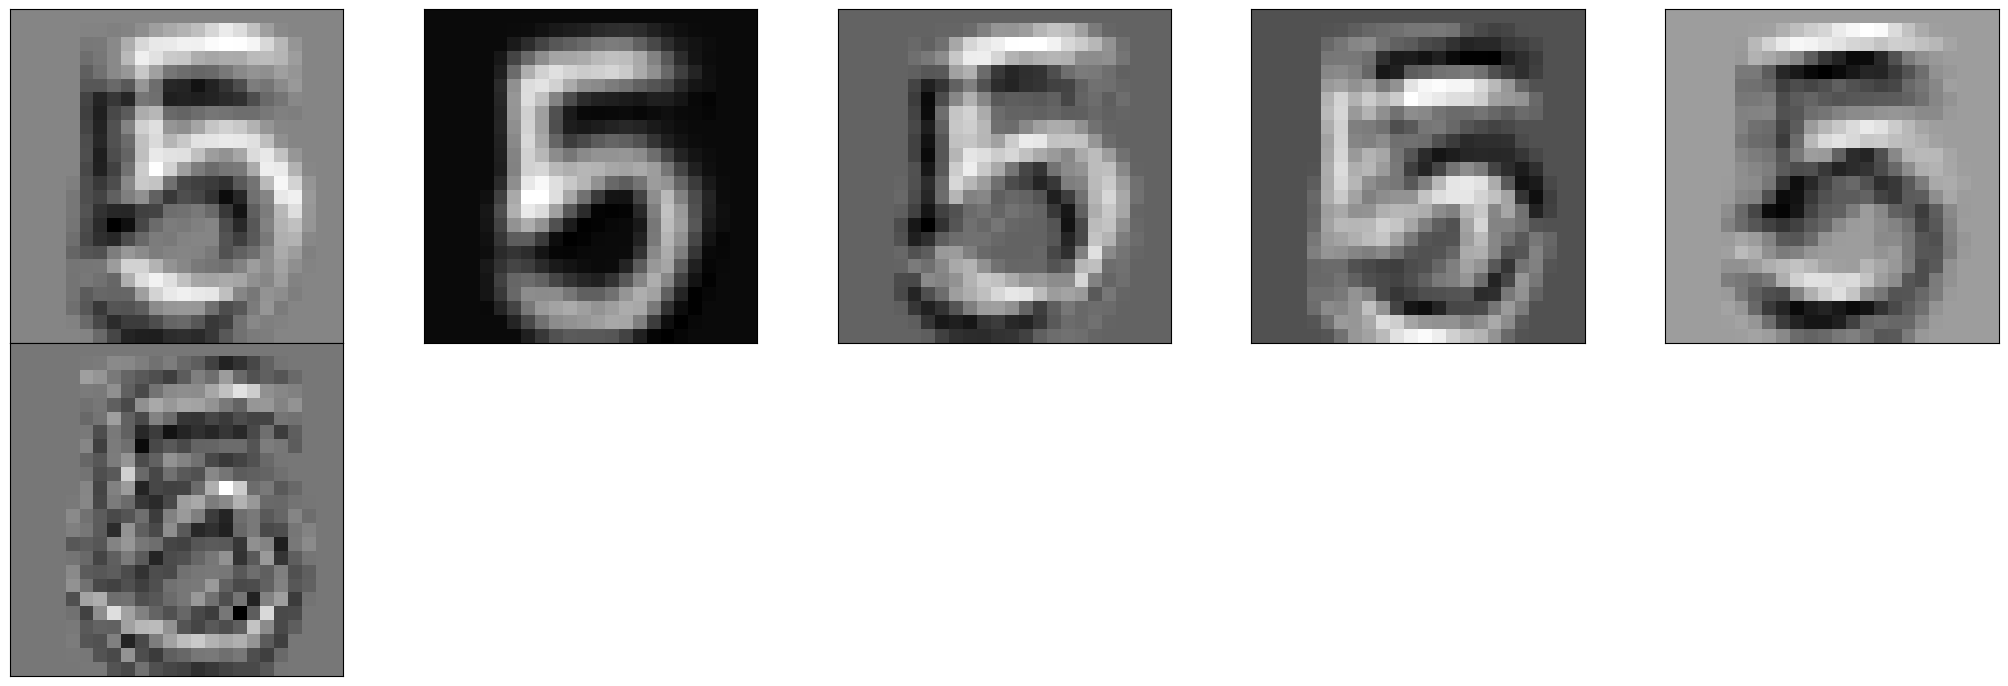

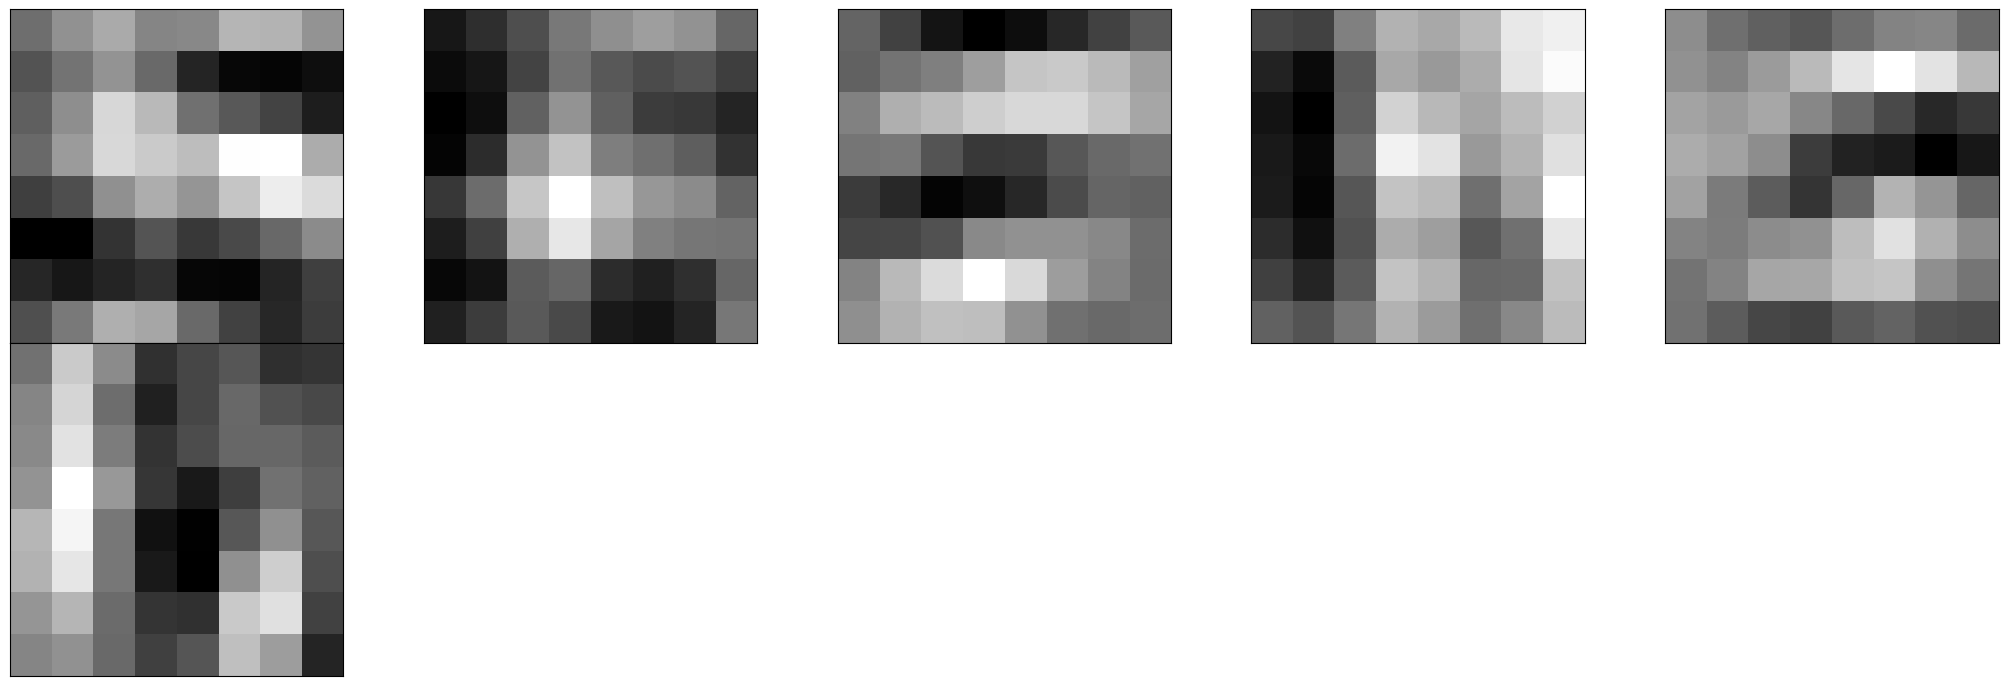

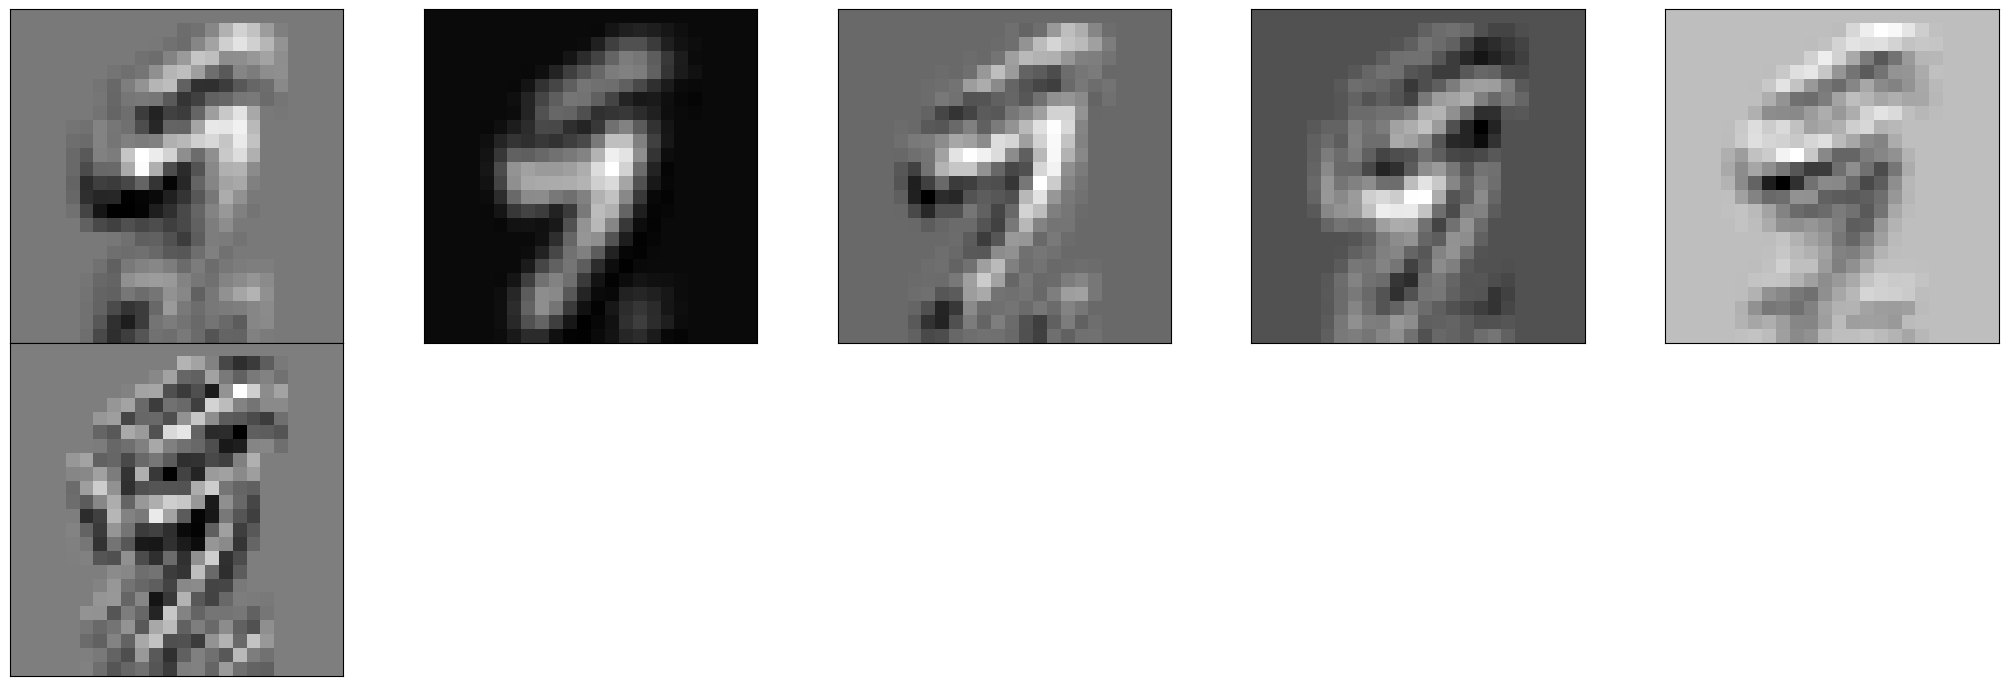

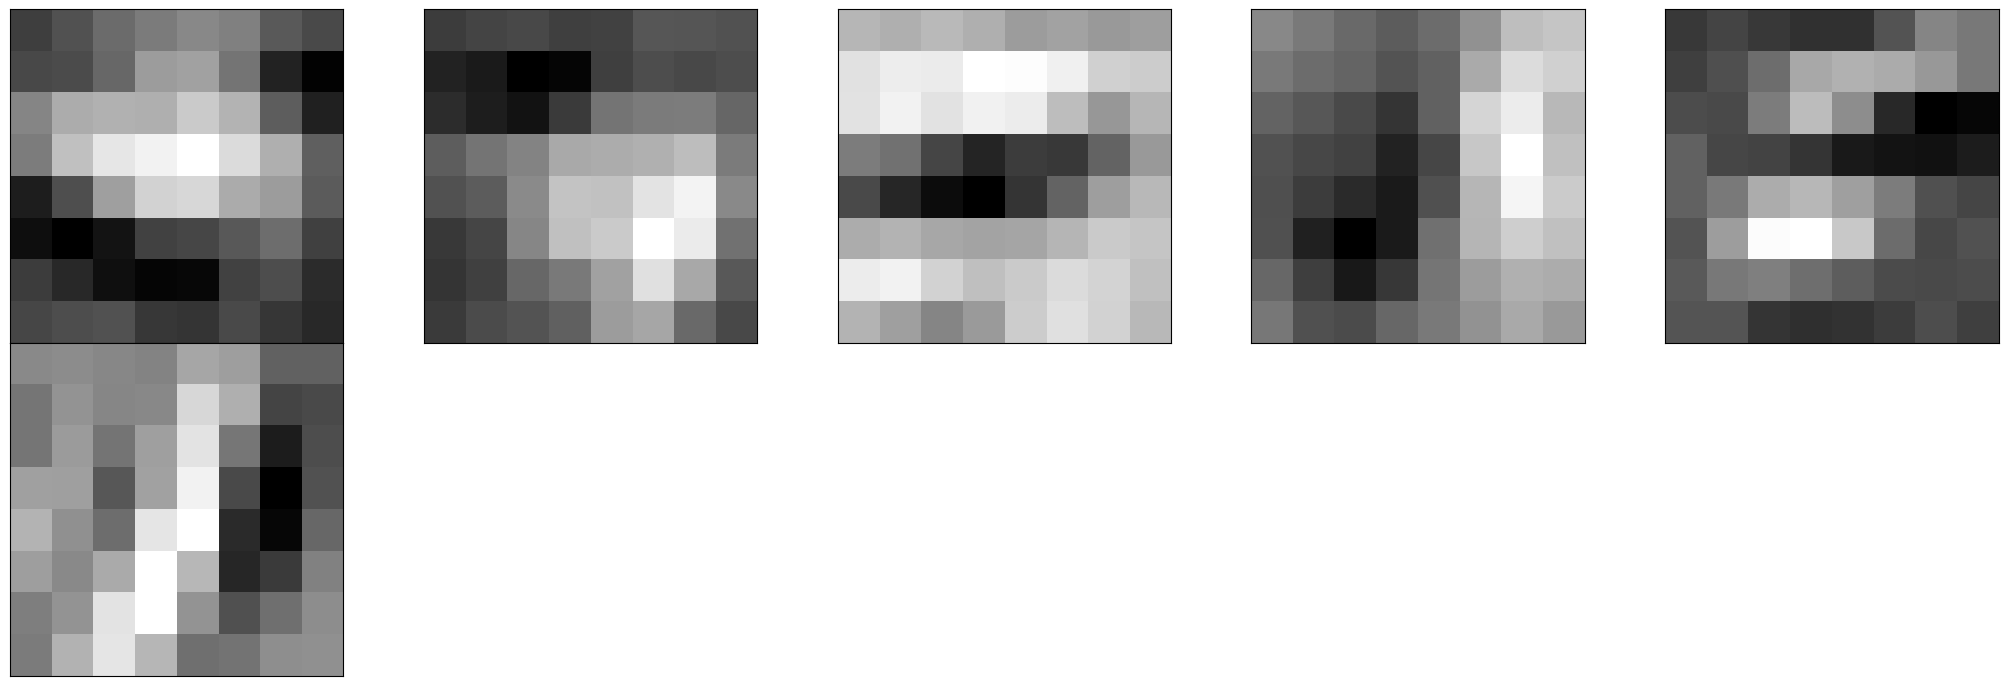

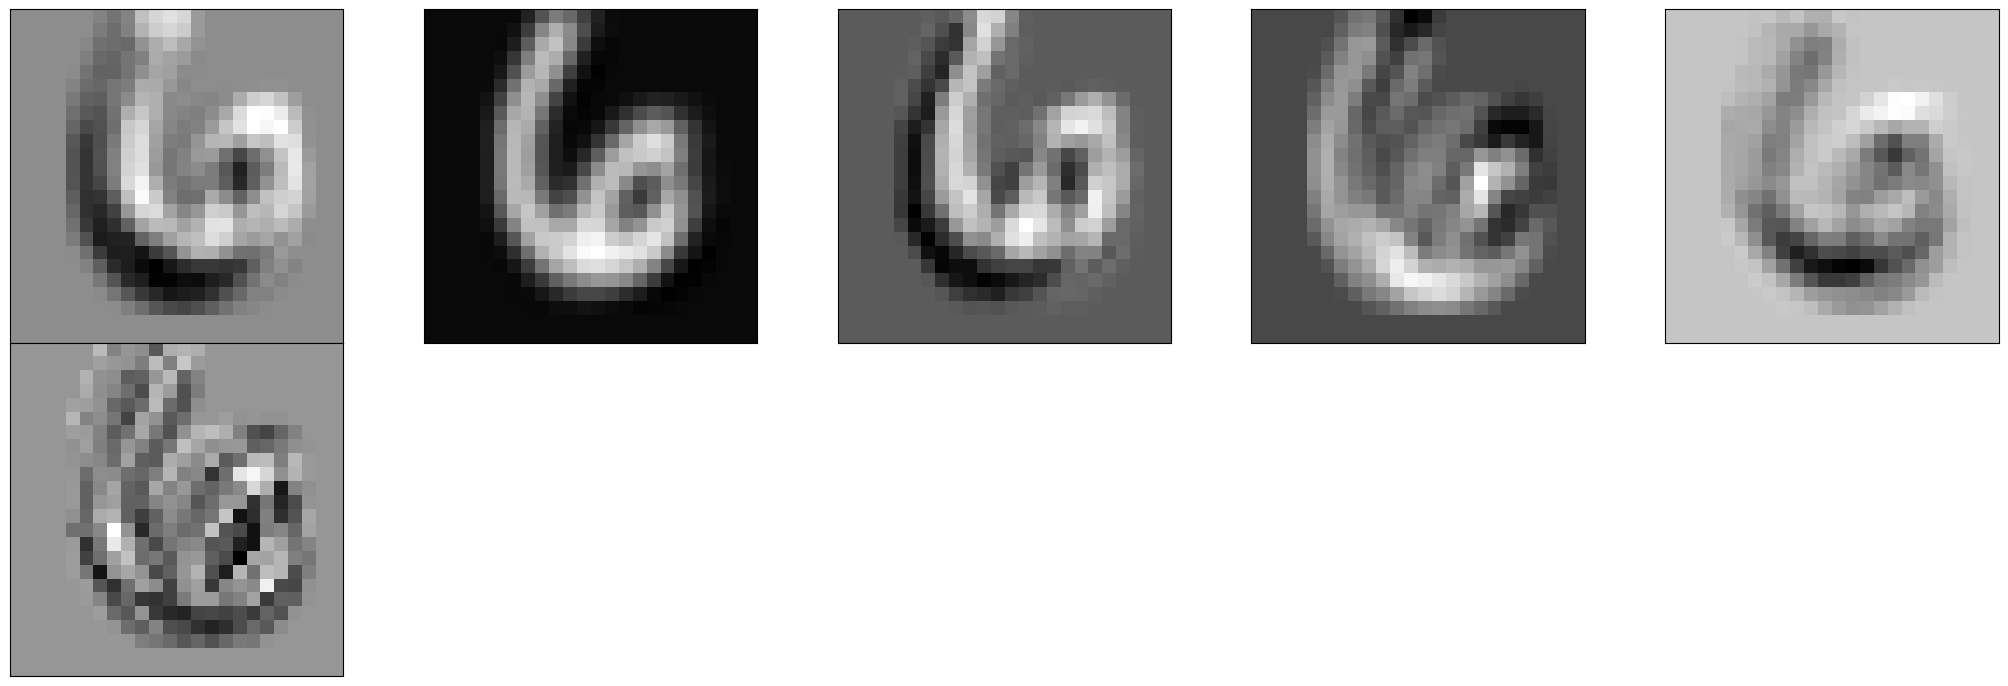

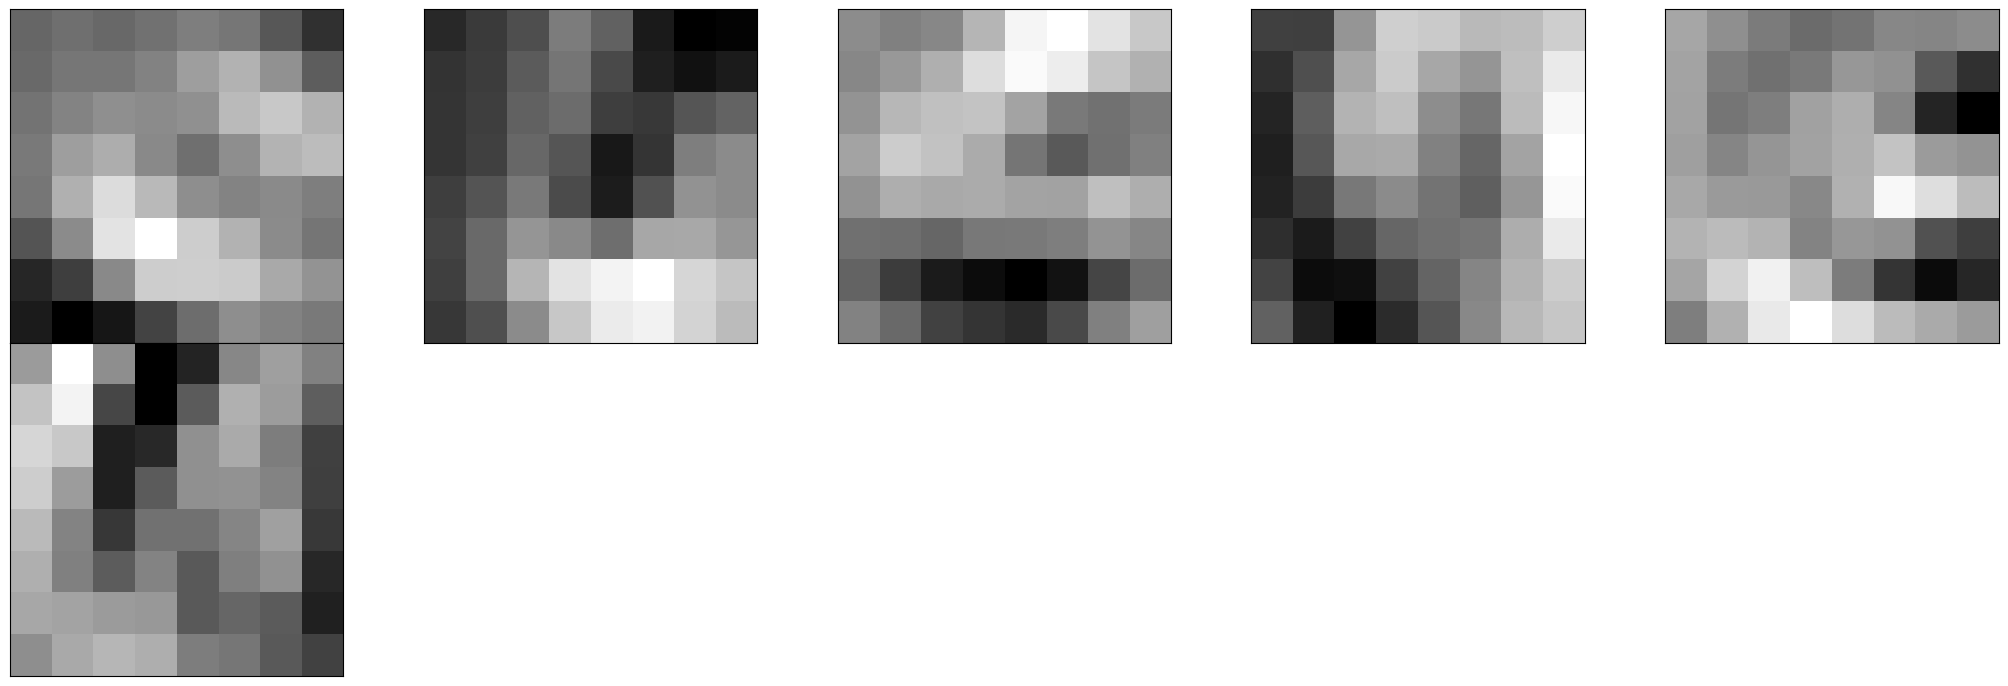

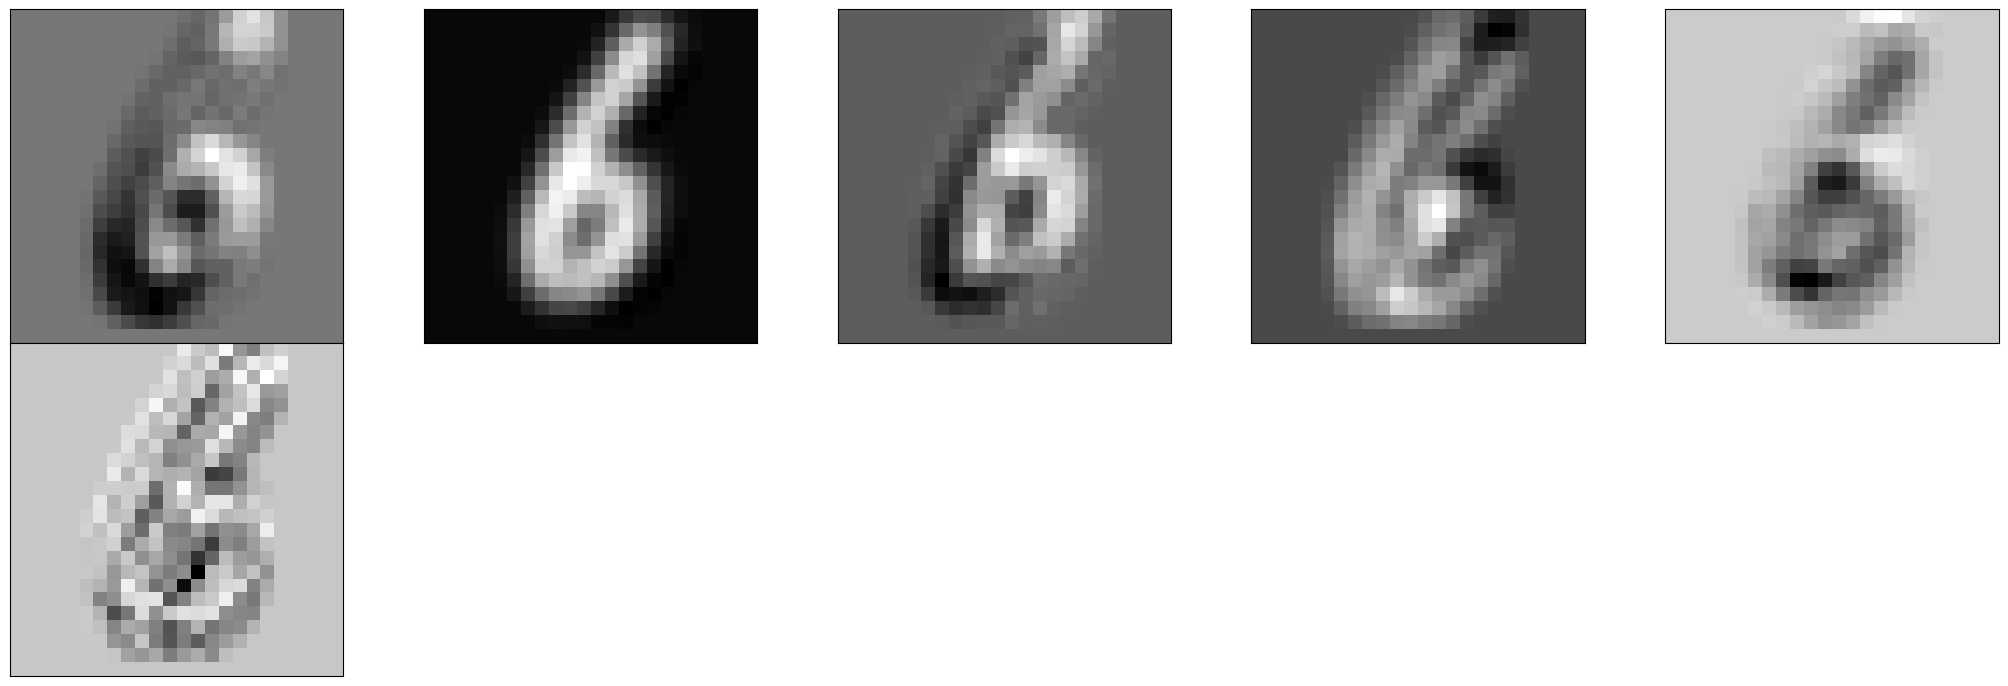

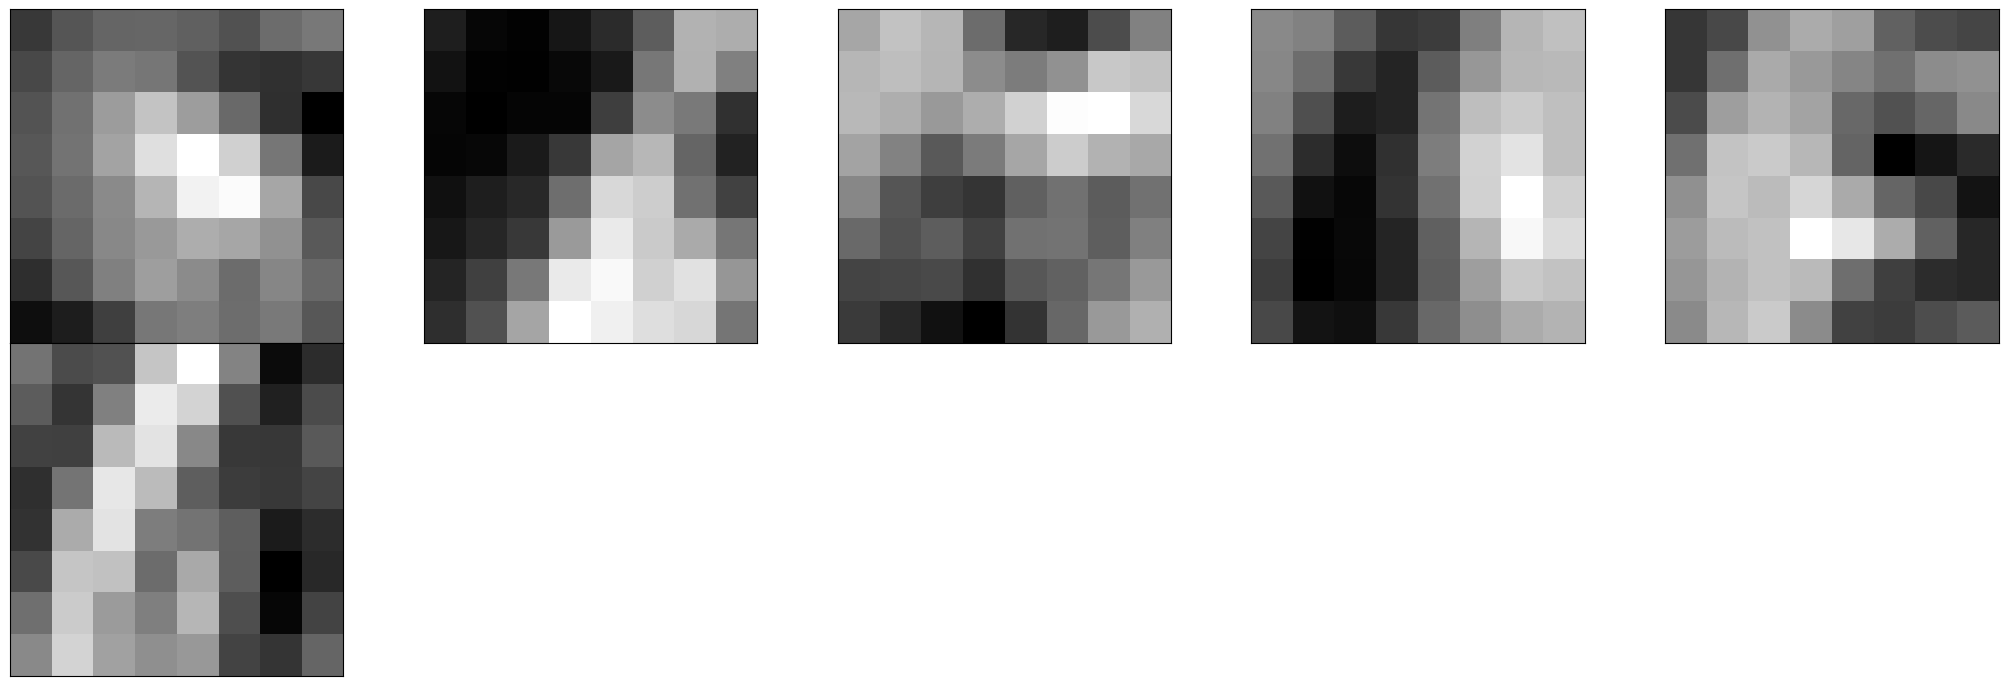

In [10]:
for images, targets in test_loader:
    act= getActivations(model_cnn, model_cnn.conv1, images.to(device))
    act2= getActivations(model_cnn, model_cnn.conv2, images.to(device))
    
    fig = plt.figure(figsize=(20,50))
    fig.subplots_adjust(left=0,right=1,bottom=0,top=0.8,hspace=0, wspace=0.2)
    for i in range(n_features):
        ax = fig.add_subplot(12,5,i+1,xticks=[],yticks=[])
        ax.imshow(act[0][i].cpu().detach().numpy(), cmap=plt.get_cmap('gray'))

    fig = plt.figure(figsize=(20,50))
    fig.subplots_adjust(left=0,right=1,bottom=0,top=0.8,hspace=0, wspace=0.2)
    for i in range(n_features):
        ax = fig.add_subplot(12,5,i+1,xticks=[],yticks=[])
        ax.imshow(act2[0][i].cpu().detach().numpy(), cmap=plt.get_cmap('gray'))

## A more challenging dataset

The MNIST dataset is relatively simple to solve as you can see from the score obtained above. Let's take a look to a more challenging task such as <a href="https://www.cs.toronto.edu/~kriz/cifar.html">CIFAR-10</a>. The CIFAR-10 dataset consists of 60000 32x32 colour images in 10 classes, with 6000 images per class. There are 50000 training images and 10000 test images. Batch size is 100 for the training set.


In [11]:
input_size  = 32*32   # images are 32x32 pixels
output_size = 10      # there are 10 classes

transform=transforms.Compose([ #normalization on 3 channels
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261))
        ])

dataset_tr = datasets.CIFAR10('./data', train=True, download=True, transform=transform)
dataset_te = datasets.CIFAR10('./data', train=False, transform=transform)

train_loader = torch.utils.data.DataLoader(dataset_tr,batch_size=100,shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset_te, batch_size=1000,shuffle=True)

#load training data
images, labels = next(iter(train_loader))

>**Task 3:** adapt the CNN developed for MNIST on the CIFAR-10 dataset and look at the results. Notice that the CIFAR images use 3 channels (RGB) instead of 1 channel (black and white). Train for 2 epochs.

In [68]:
class CNN(nn.Module):
    def __init__(self, input_size, n_feature, output_size):
        super().__init__()
        #insert your code here
        K=5
        self.n_feature=n_feature
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=n_feature, kernel_size=K)
        self.conv2 = nn.Conv2d(n_feature, n_feature, kernel_size=K)
        self.fc1 = nn.Linear(n_feature*25, 50)
        self.fc2 = nn.Linear(50, 10)
        
        
    def forward(self, x, verbose=False):
        #initial dimensions for x will be [100, 3, 32, 32]
        #insert your code here
        x = self.conv1(x) #[100, 6, 28, 28]
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2) #[100, 6, 14, 14]
        x = self.conv2(x) #[100, 6, 10, 10]
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2) #[100, 6, 5, 5]
        x = x.view(-1, self.n_feature*25)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        output = F.log_softmax(x, dim=1)
        
        return output

In [72]:
# Training settings 
n_features = 6 # number of feature maps

model_cnn = CNN(input_size, n_features, output_size)
model_cnn.to(device)
optimizer = torch.optim.SGD(model_cnn.parameters(), lr=0.01, momentum=0.5)

for epoch in range(0, 2):
    train(model_cnn, device, train_loader, optimizer, epoch)
    test(model_cnn, device, test_loader)

Train Epoch: 0 [0/50000 (0%)]	Loss: 2.307774
Train Epoch: 0 [10000/50000 (20%)]	Loss: 2.303049
Train Epoch: 0 [20000/50000 (40%)]	Loss: 2.302716
Train Epoch: 0 [30000/50000 (60%)]	Loss: 2.287934
Train Epoch: 0 [40000/50000 (80%)]	Loss: 2.265080

Test set: Average loss: 2.2207, Accuracy: 1861/10000 (19%)

Train Epoch: 1 [0/50000 (0%)]	Loss: 2.172822
Train Epoch: 1 [10000/50000 (20%)]	Loss: 2.204410
Train Epoch: 1 [20000/50000 (40%)]	Loss: 2.024628
Train Epoch: 1 [30000/50000 (60%)]	Loss: 1.912820
Train Epoch: 1 [40000/50000 (80%)]	Loss: 2.079041

Test set: Average loss: 1.8473, Accuracy: 3096/10000 (31%)



The accuracy is not very high in this case. The dataset is more difficult than MNIST, but we can improve the structure of our network to achieve better results.

First of all, let's take a look at what our feature maps look like for this dataset:

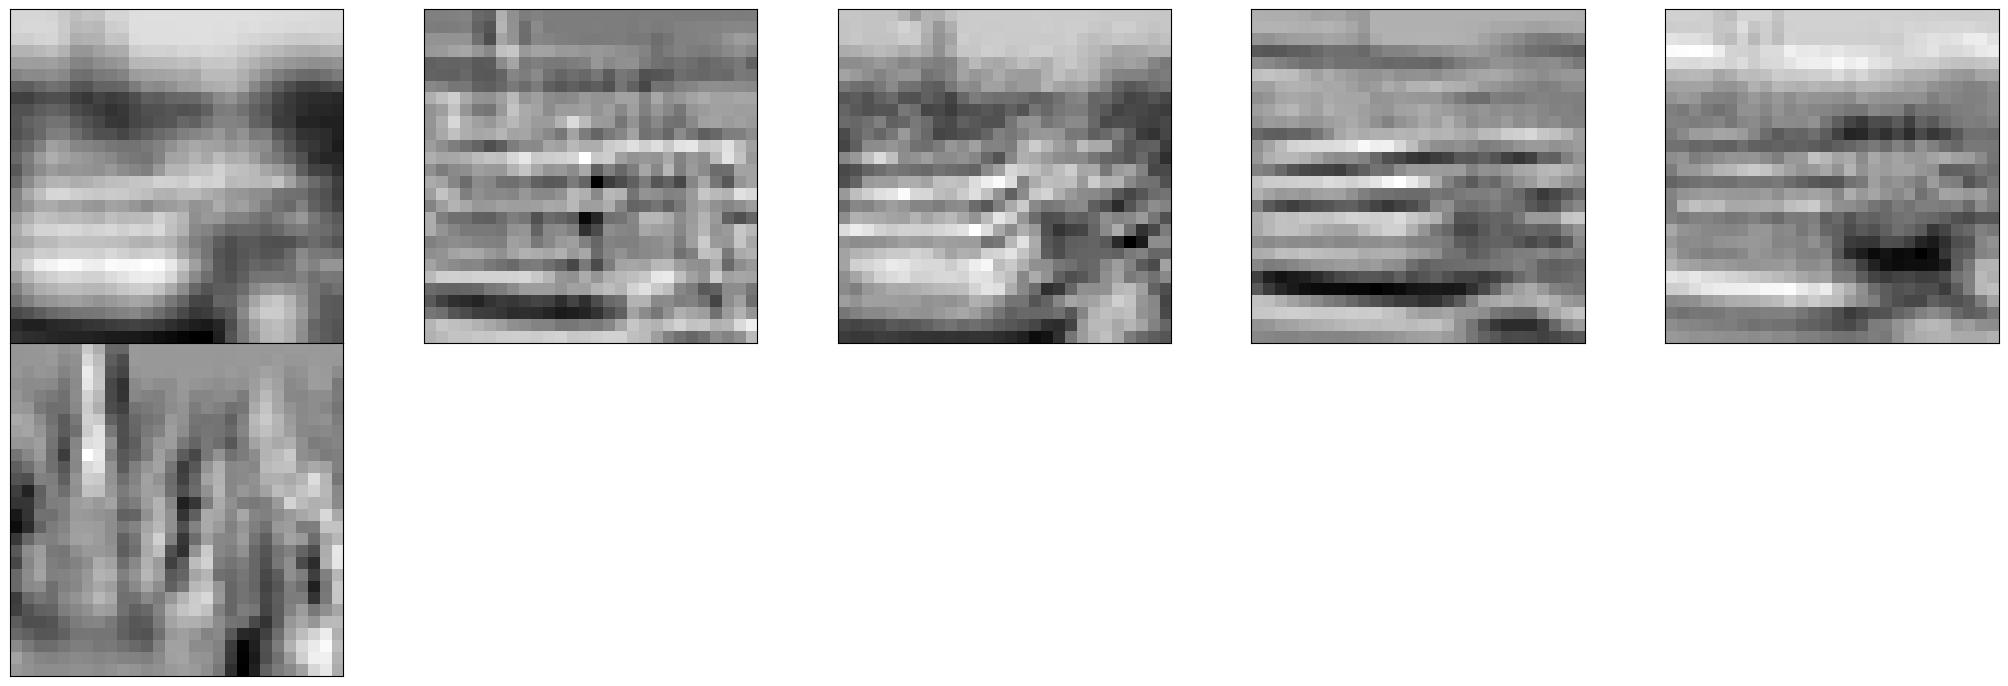

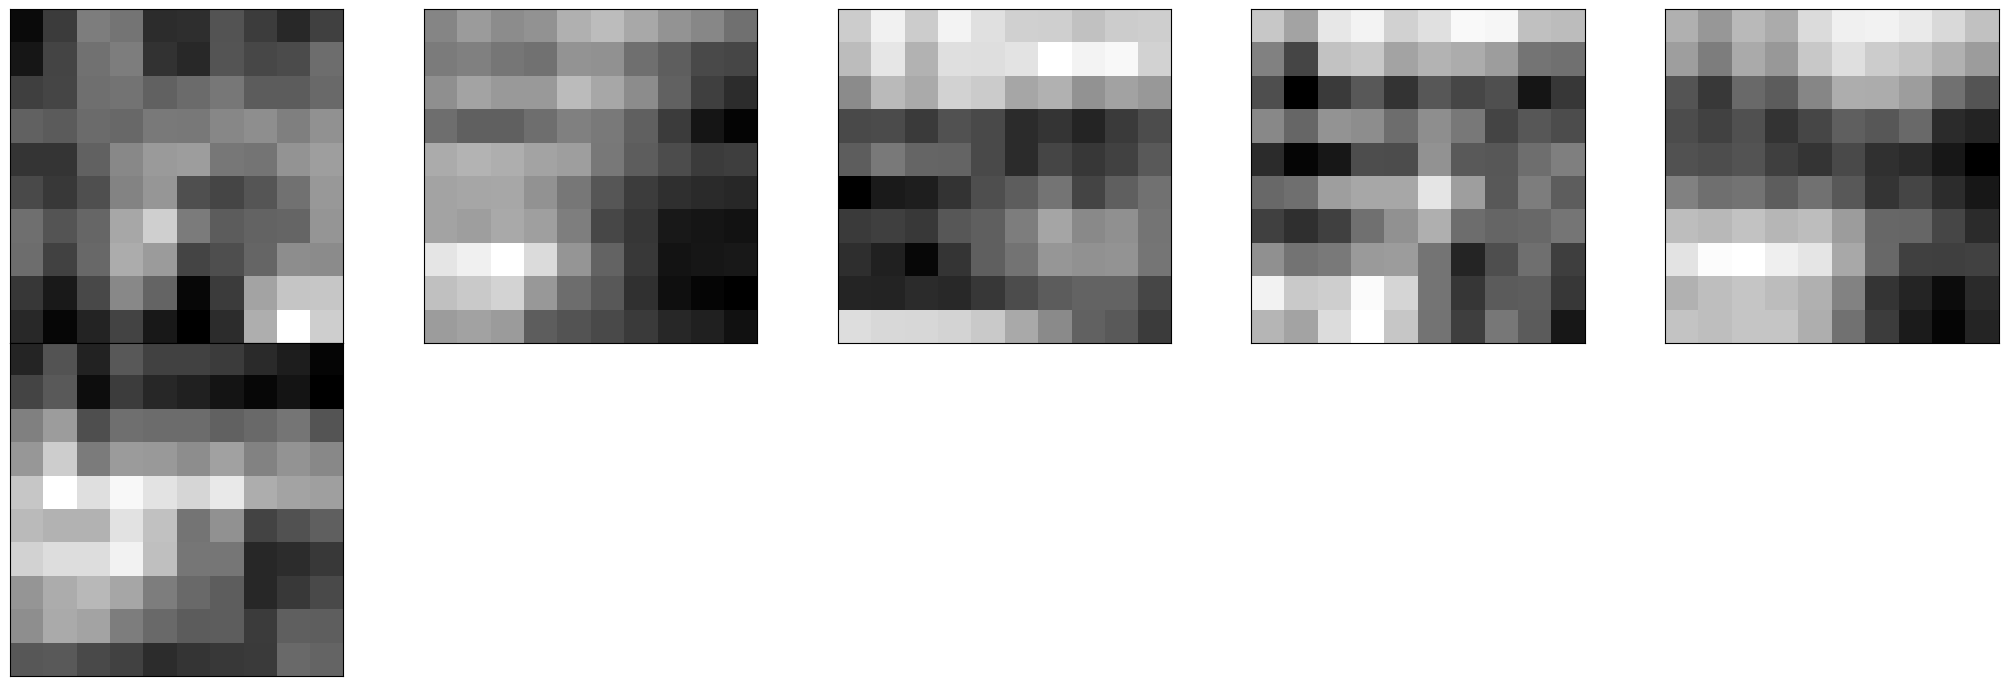

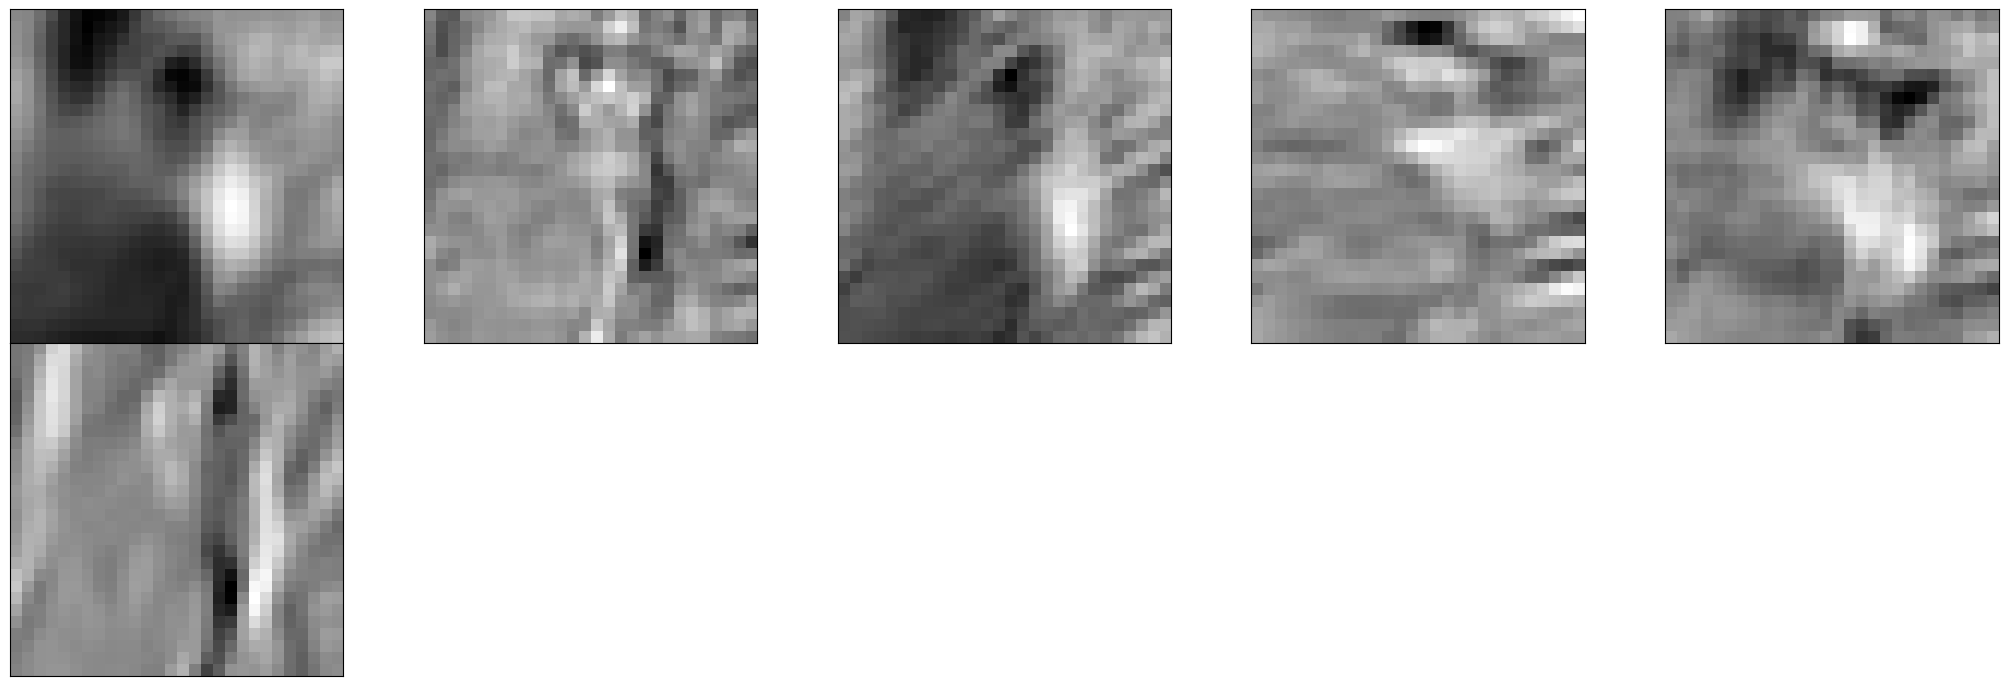

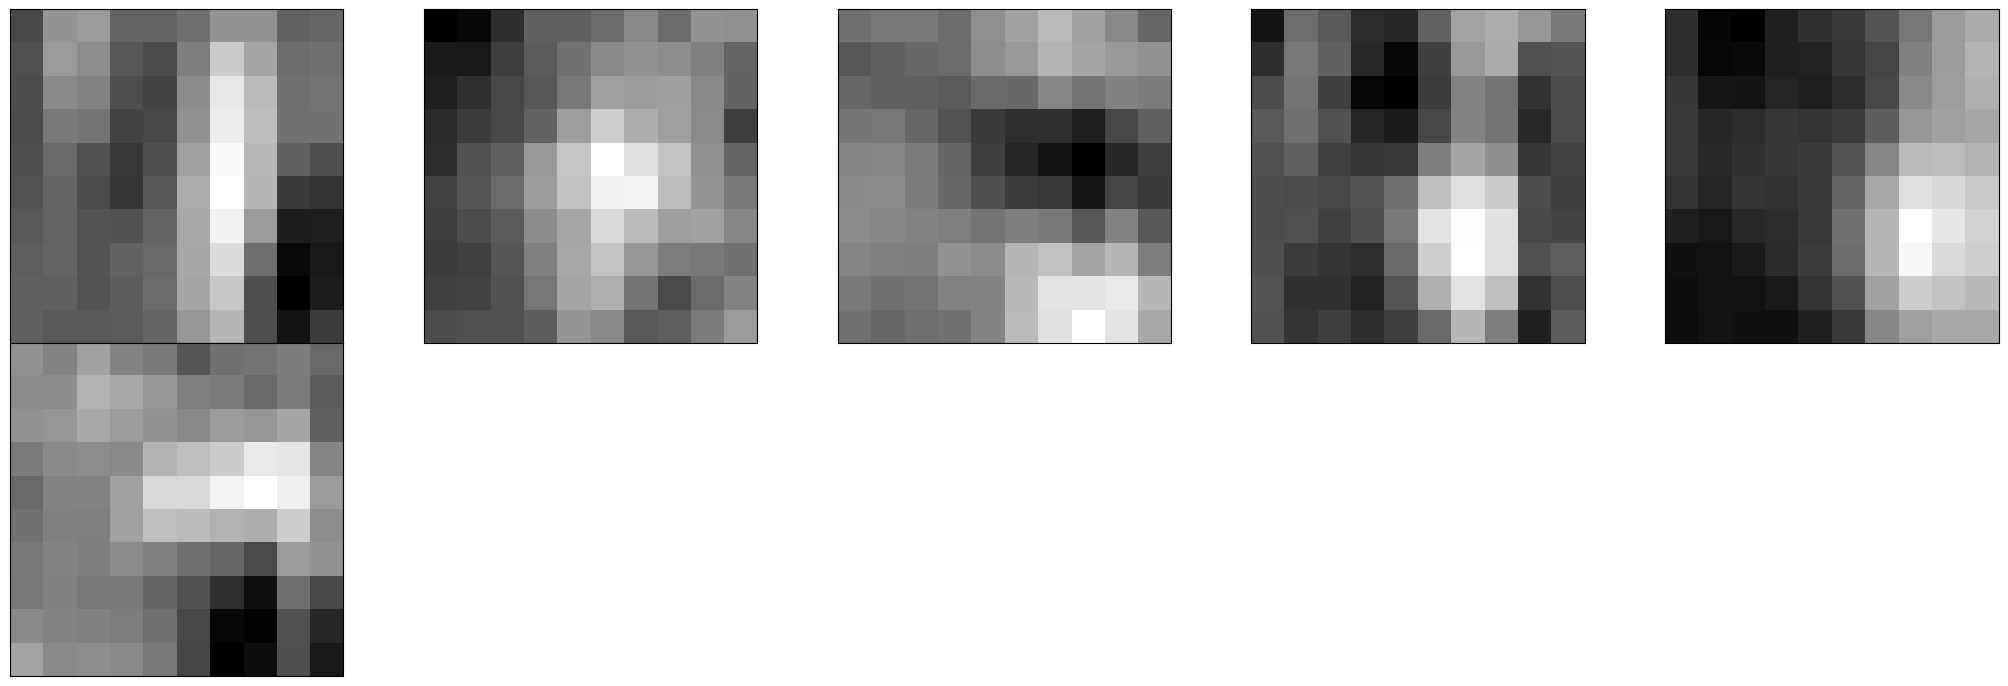

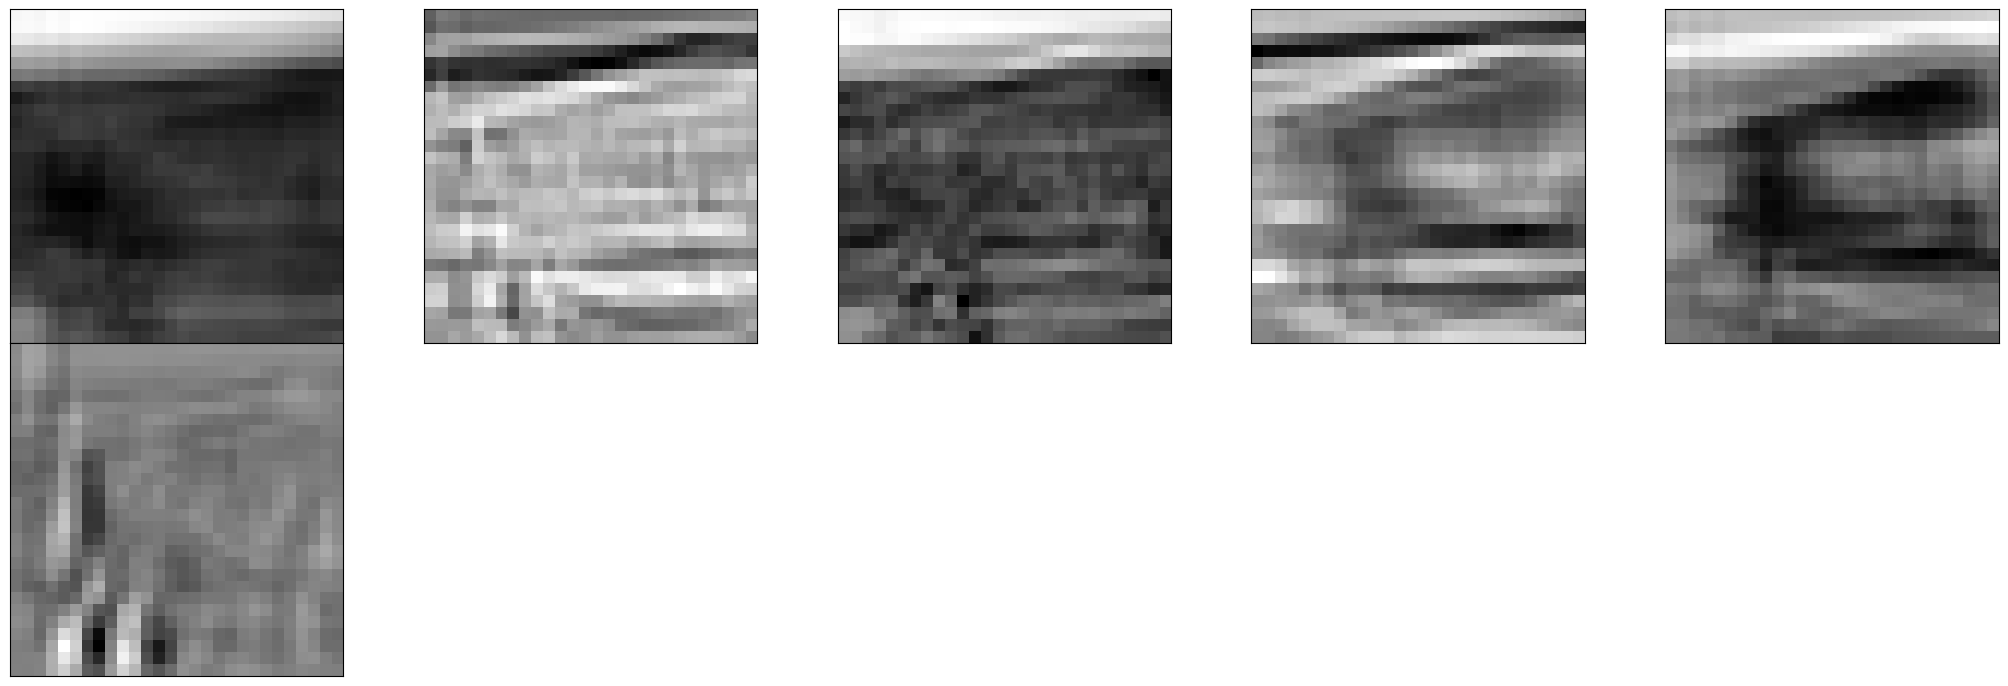

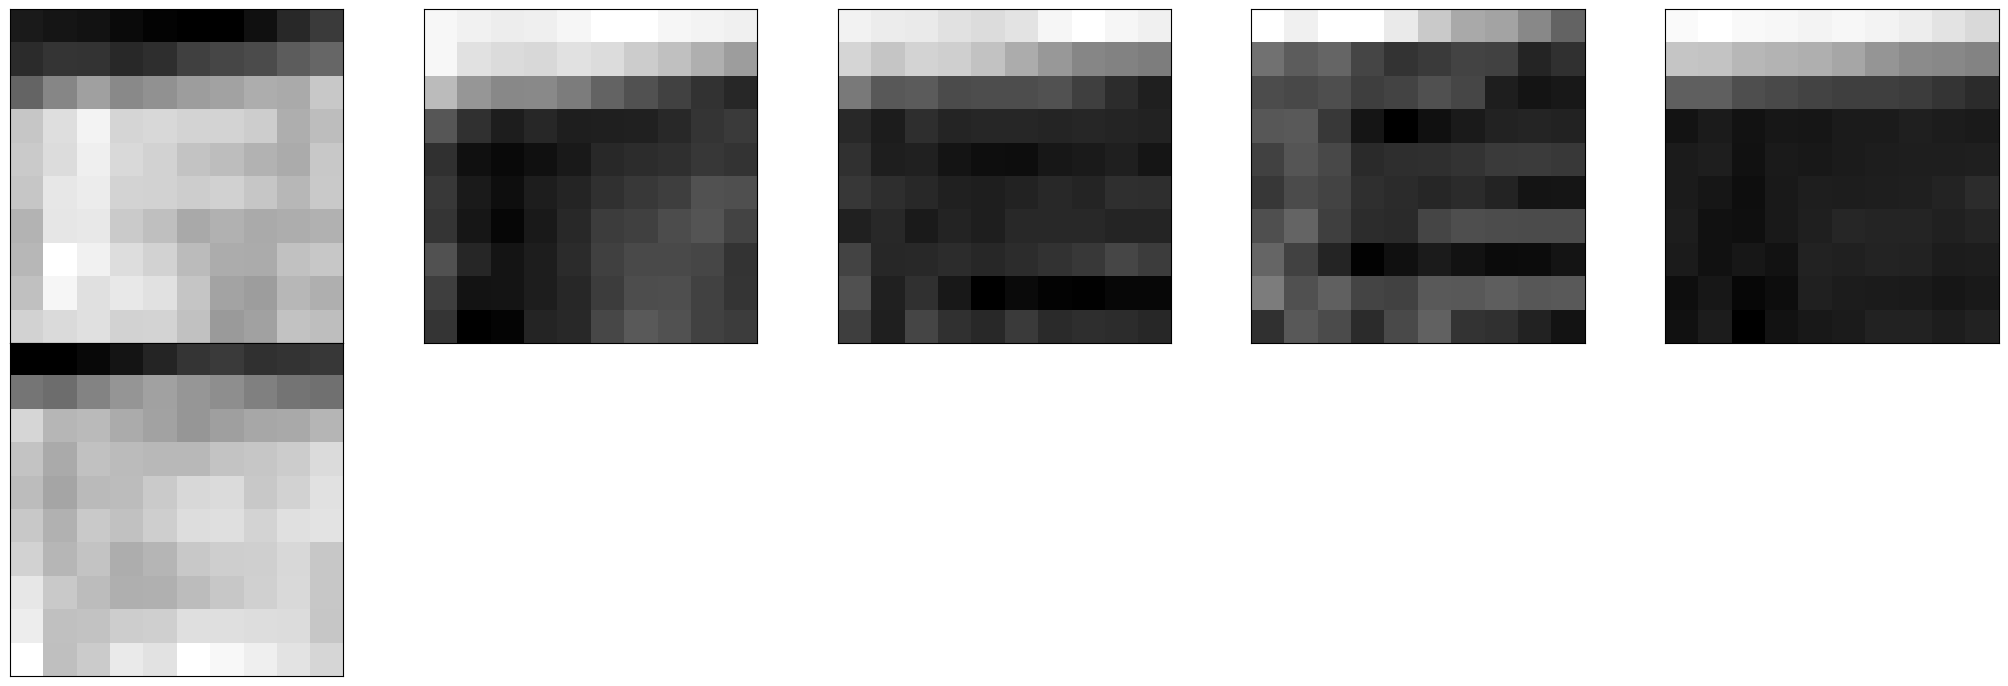

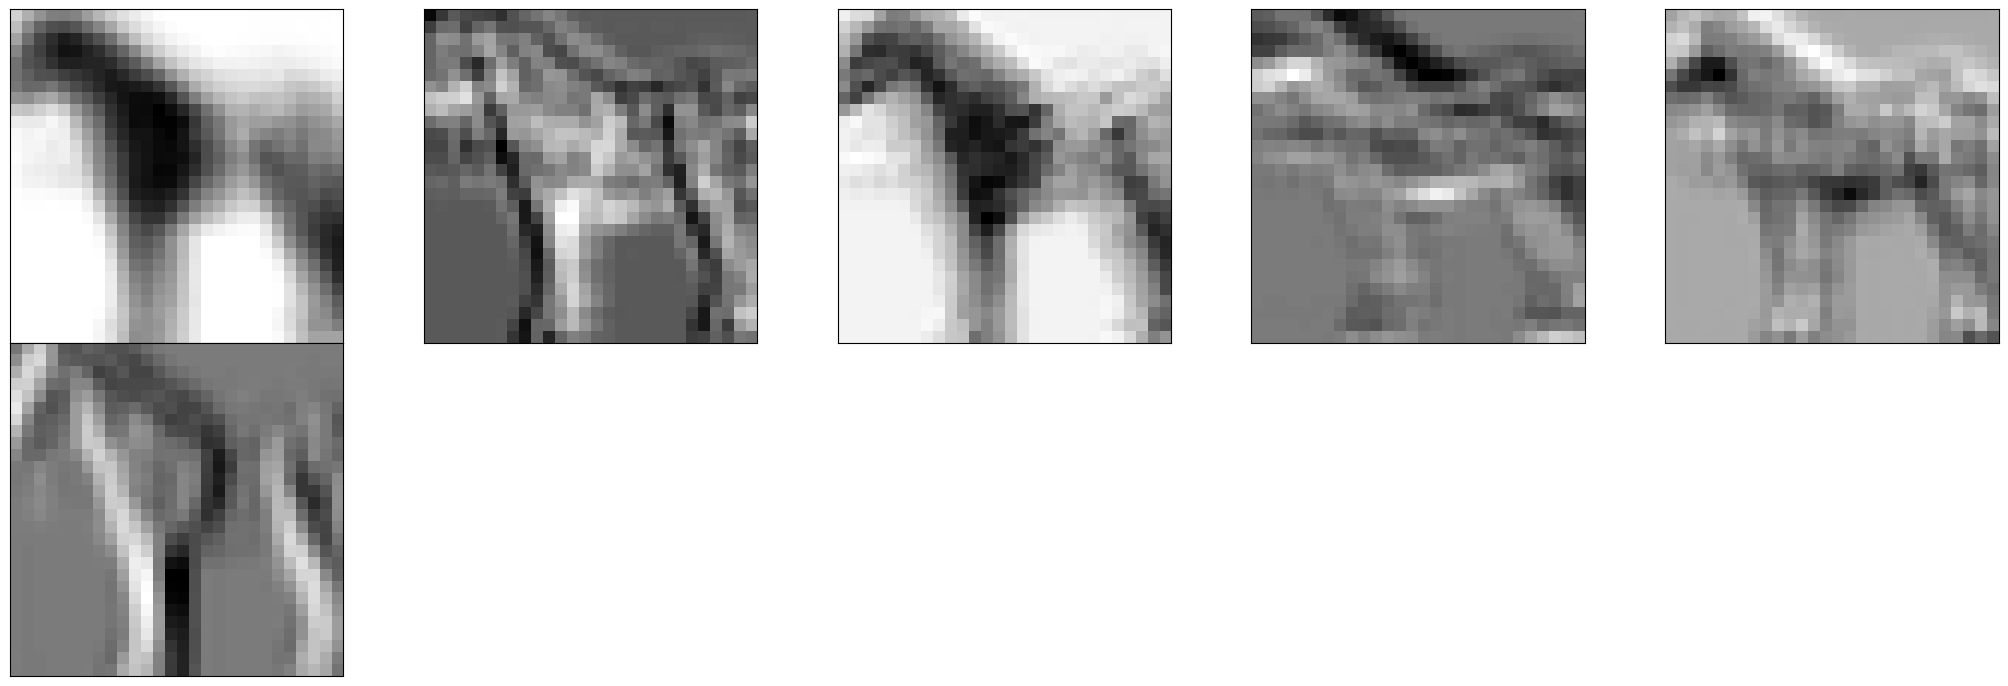

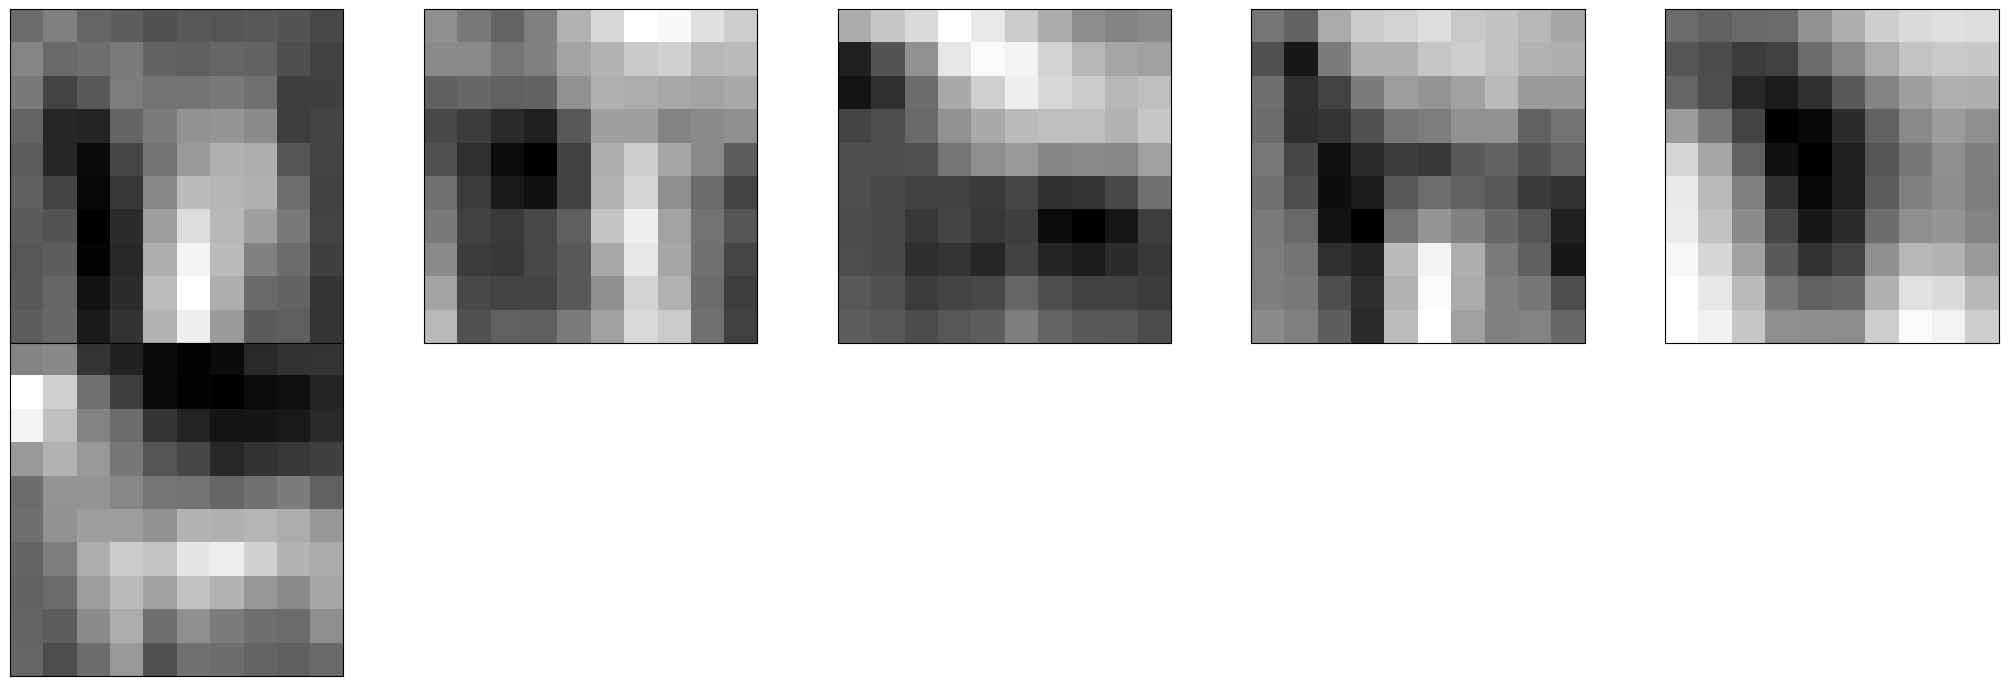

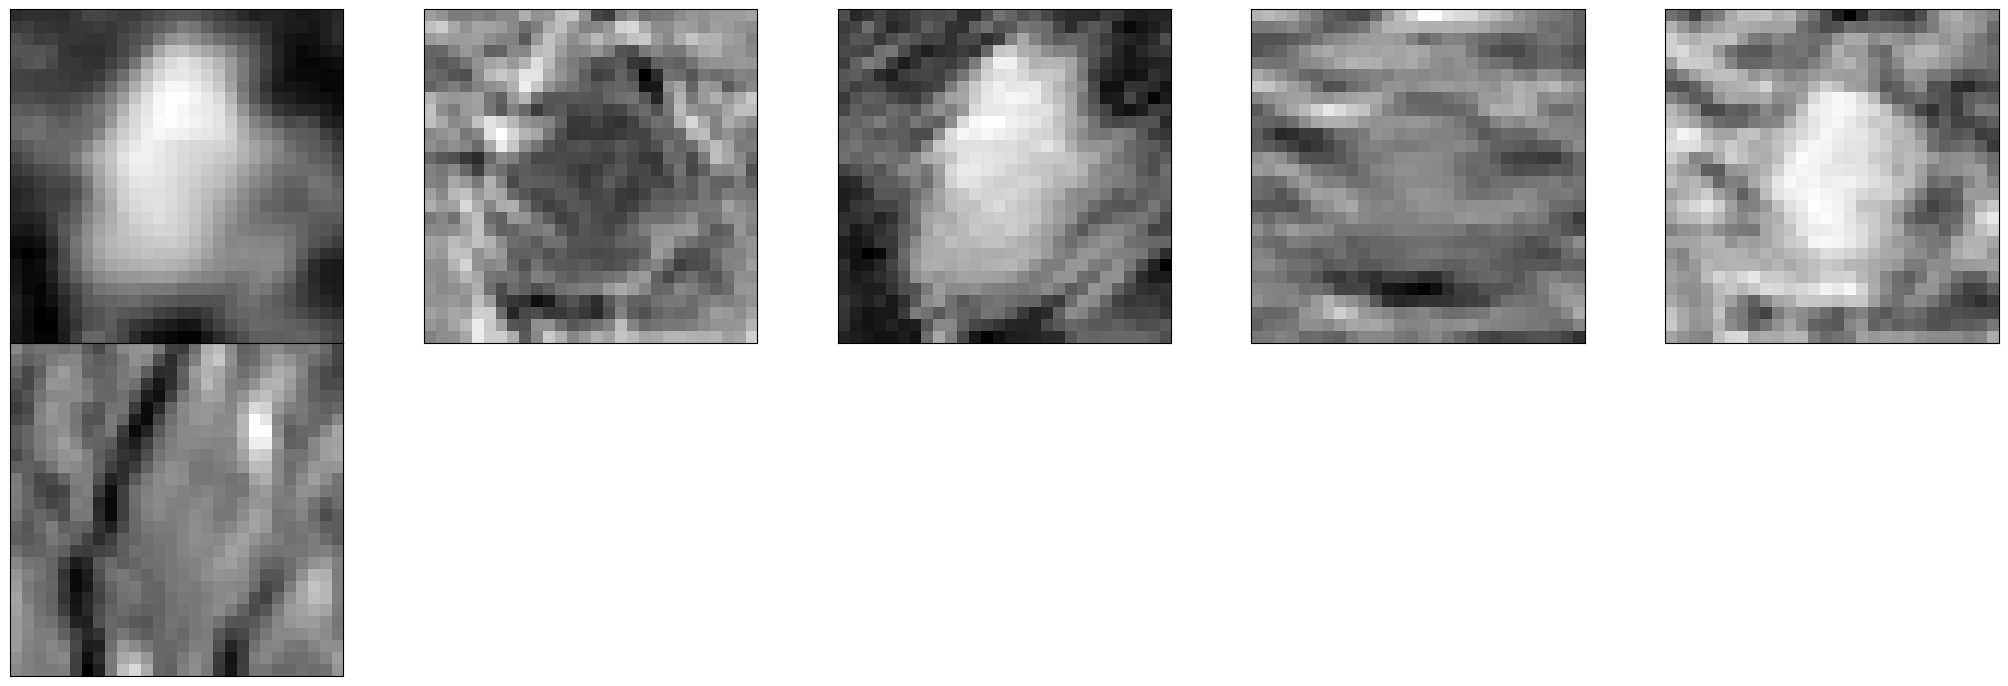

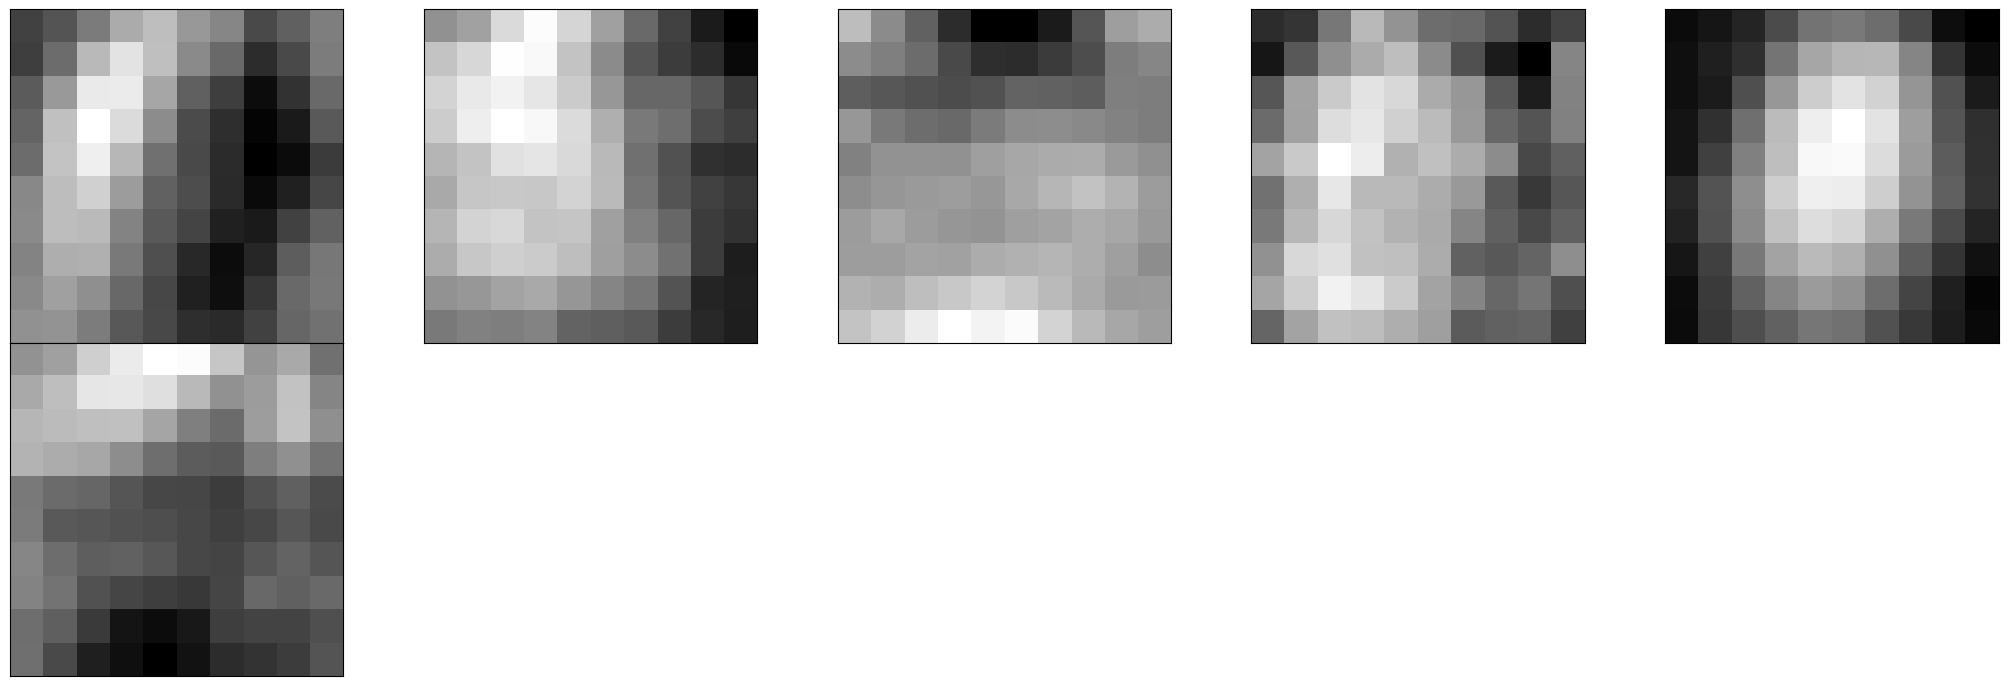

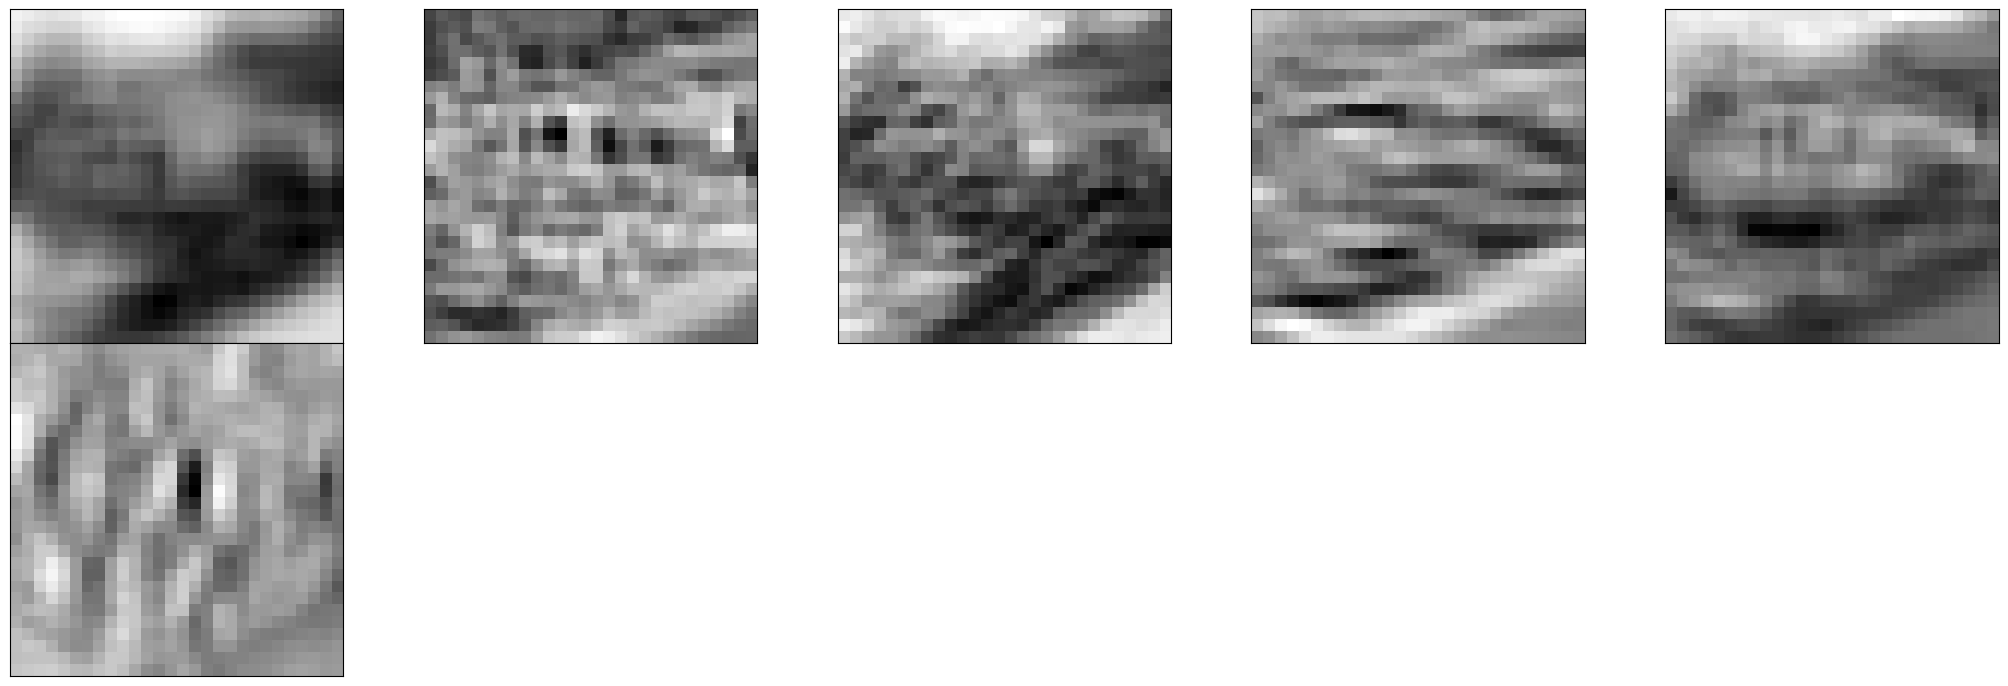

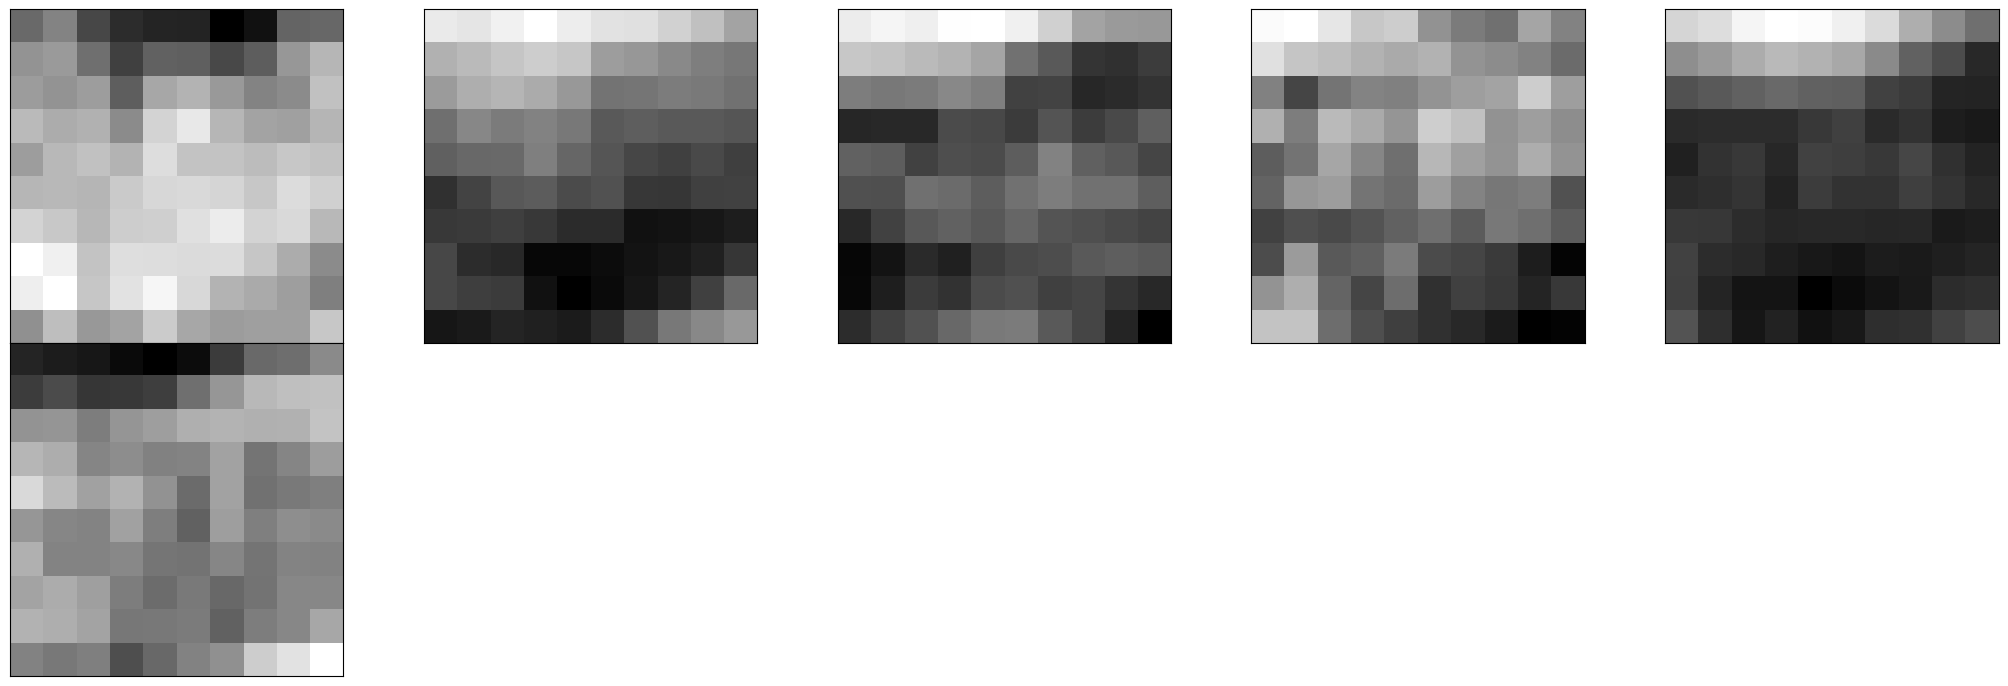

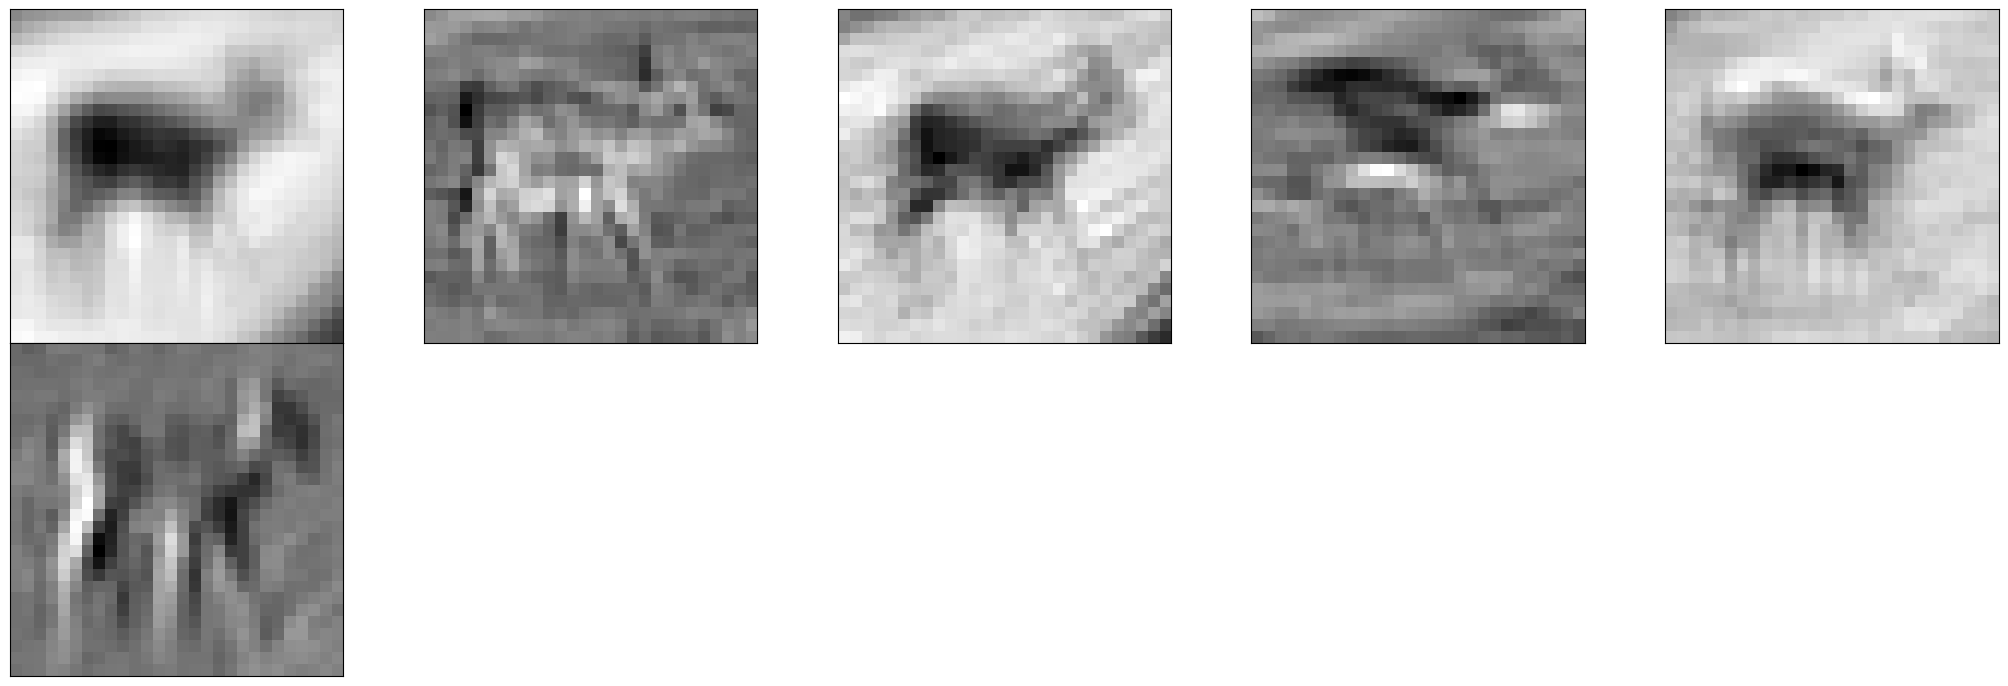

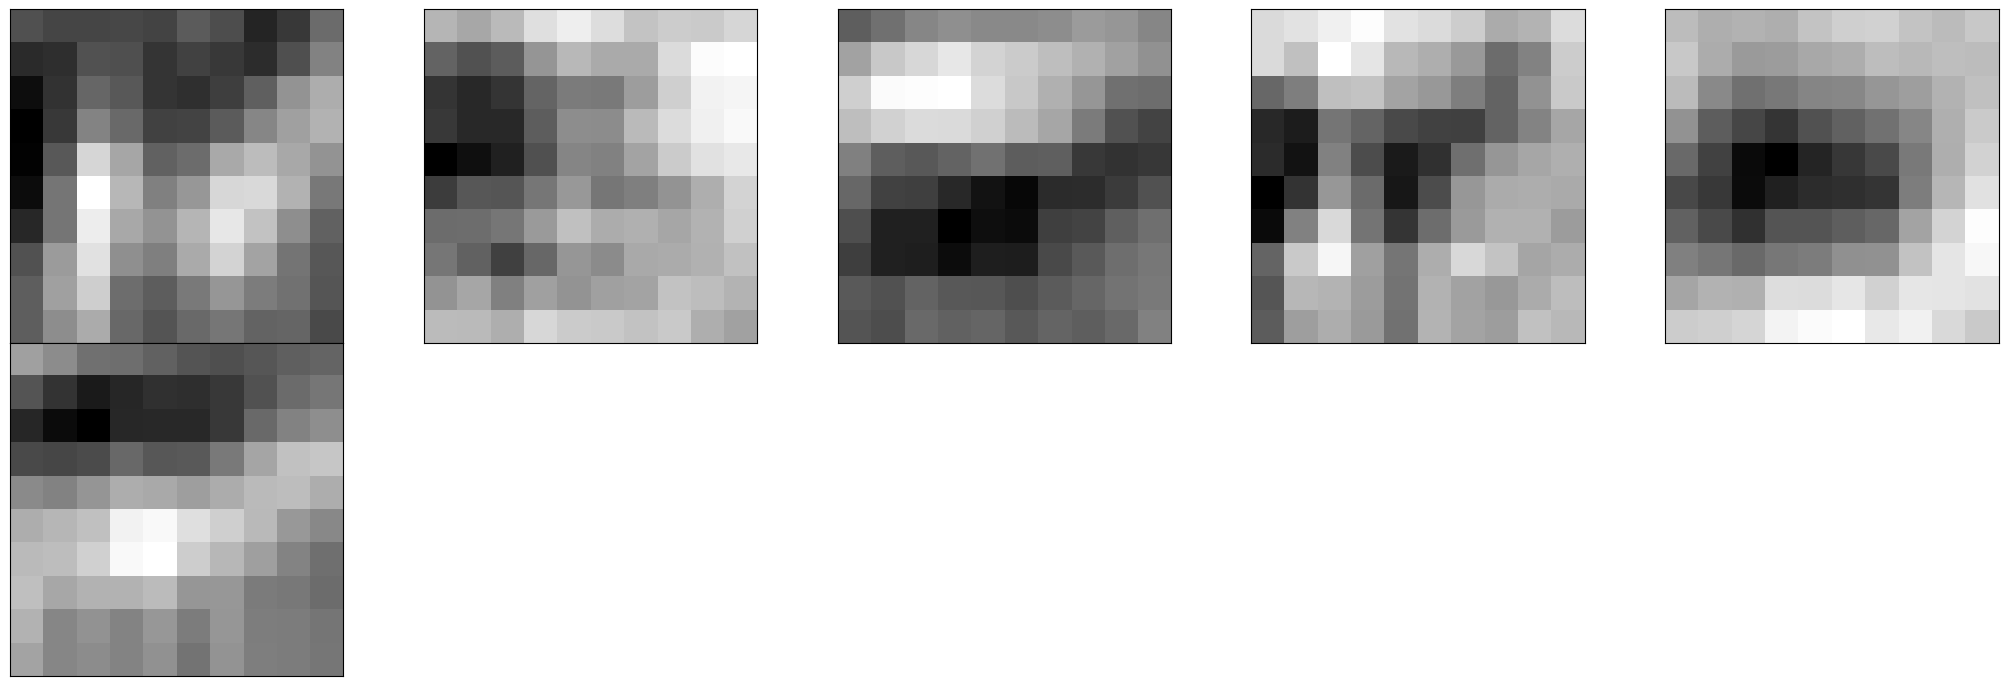

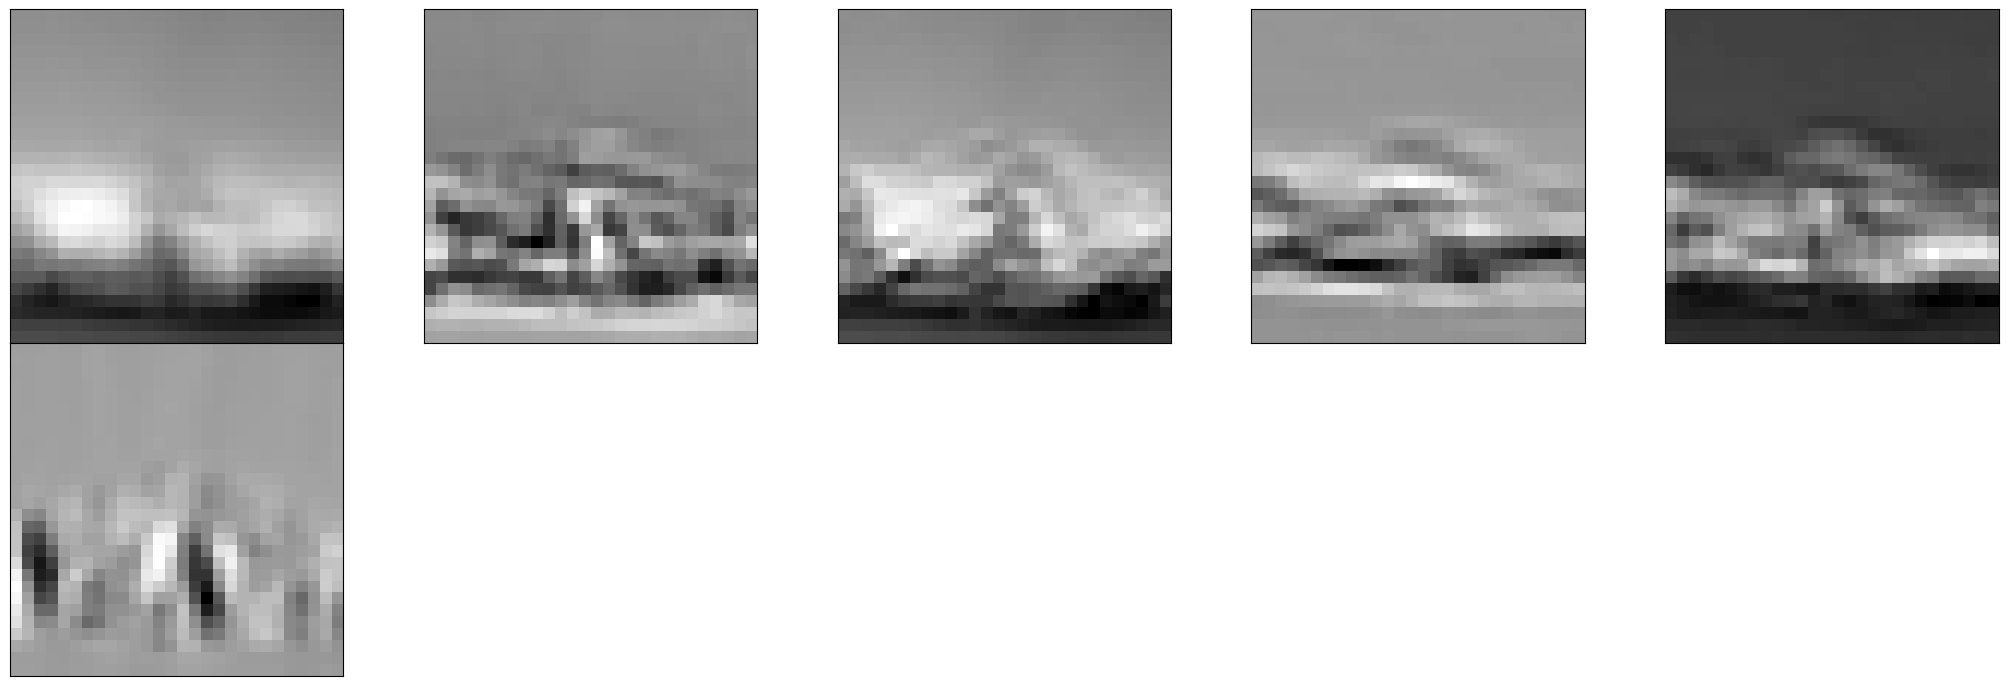

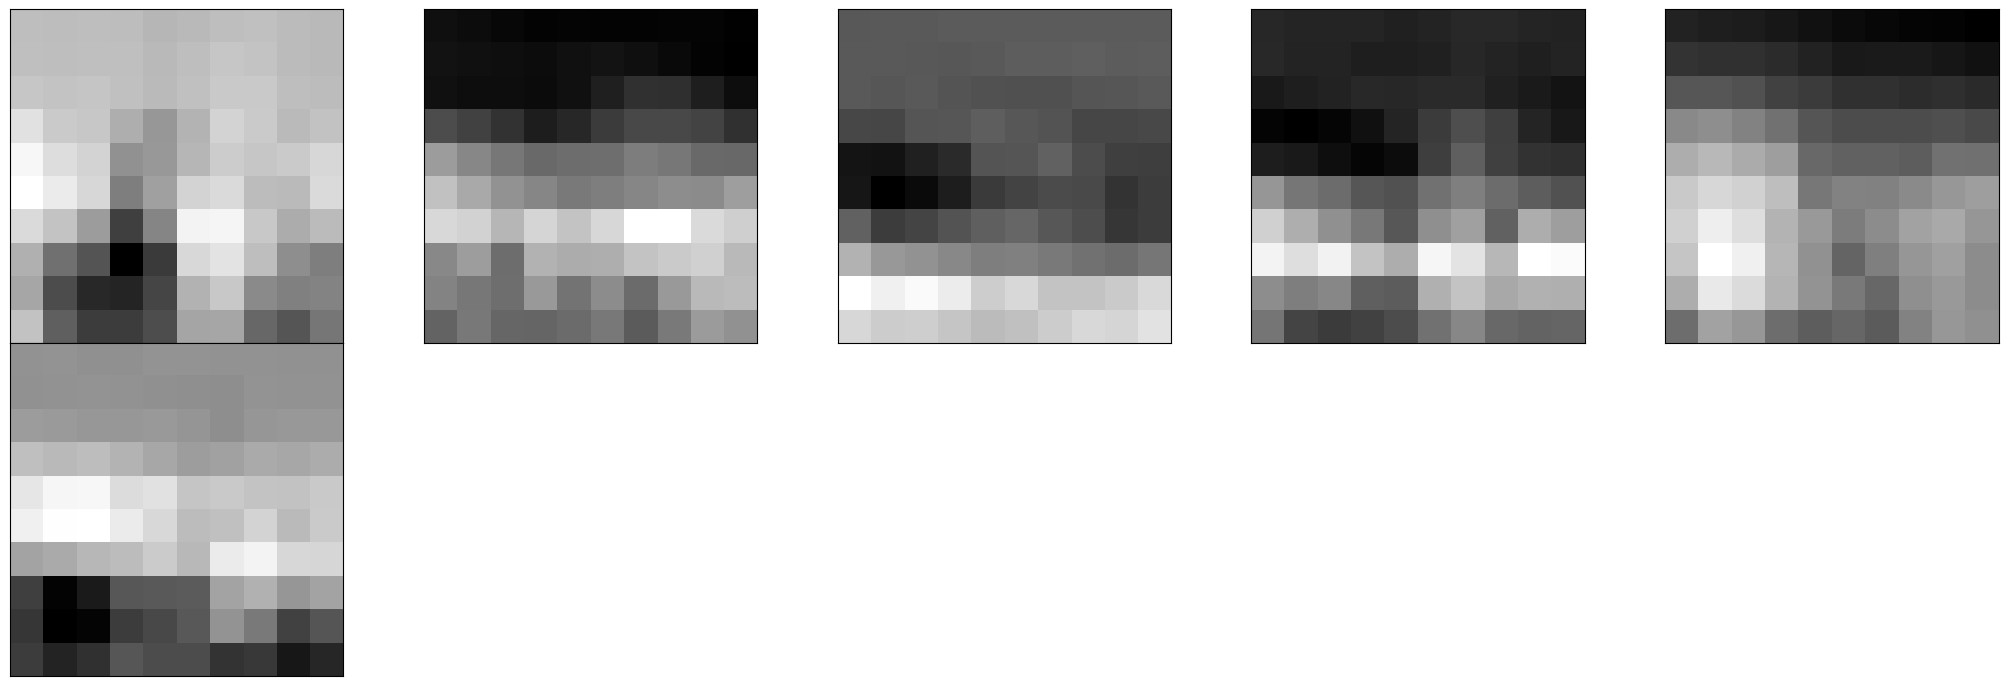

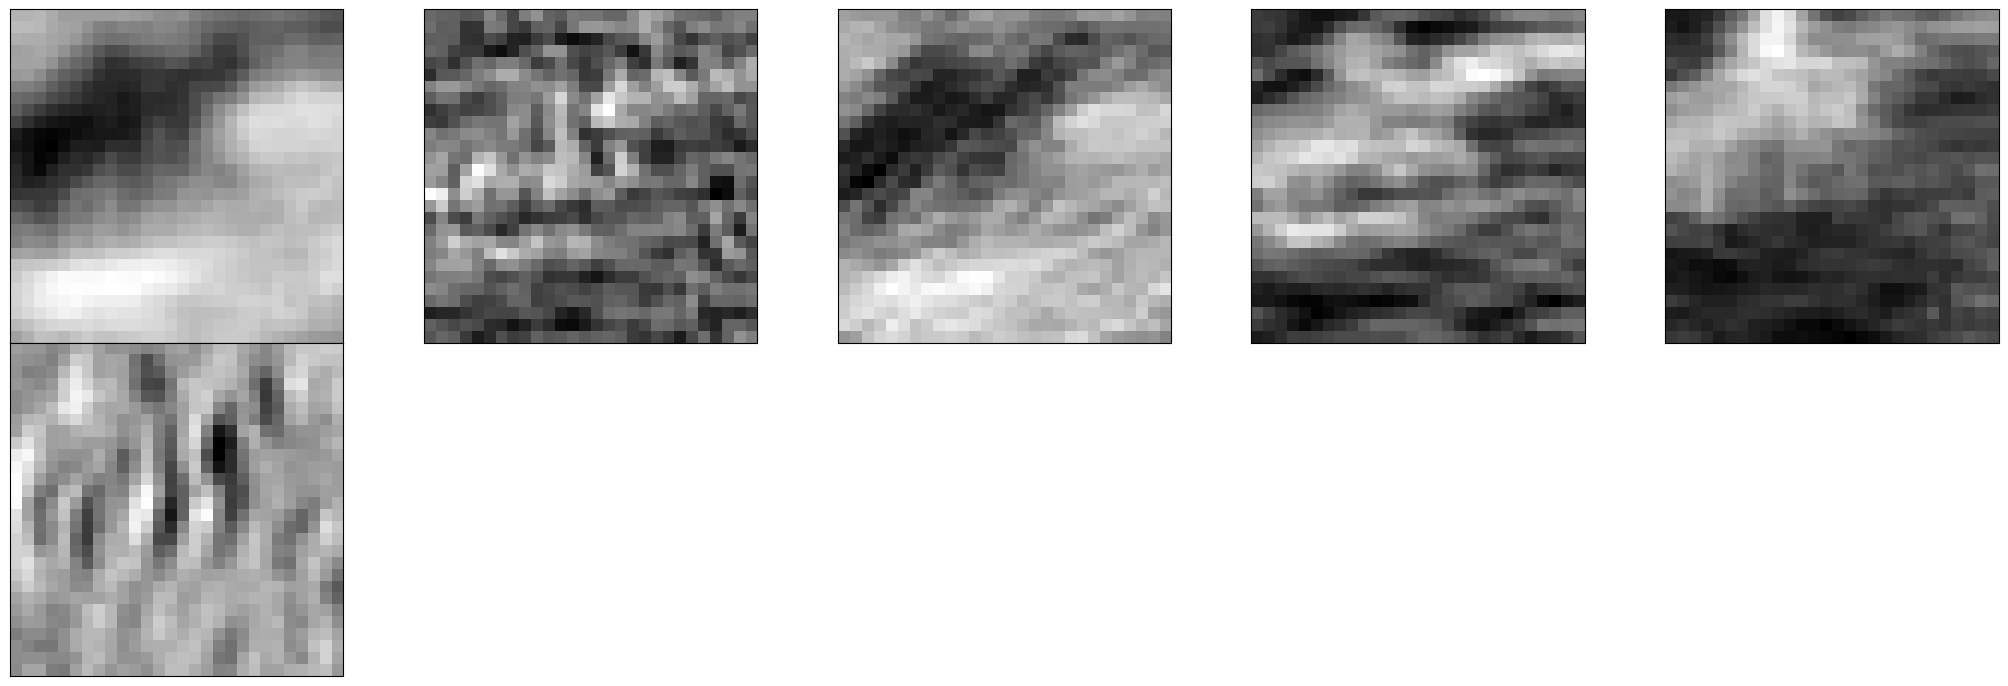

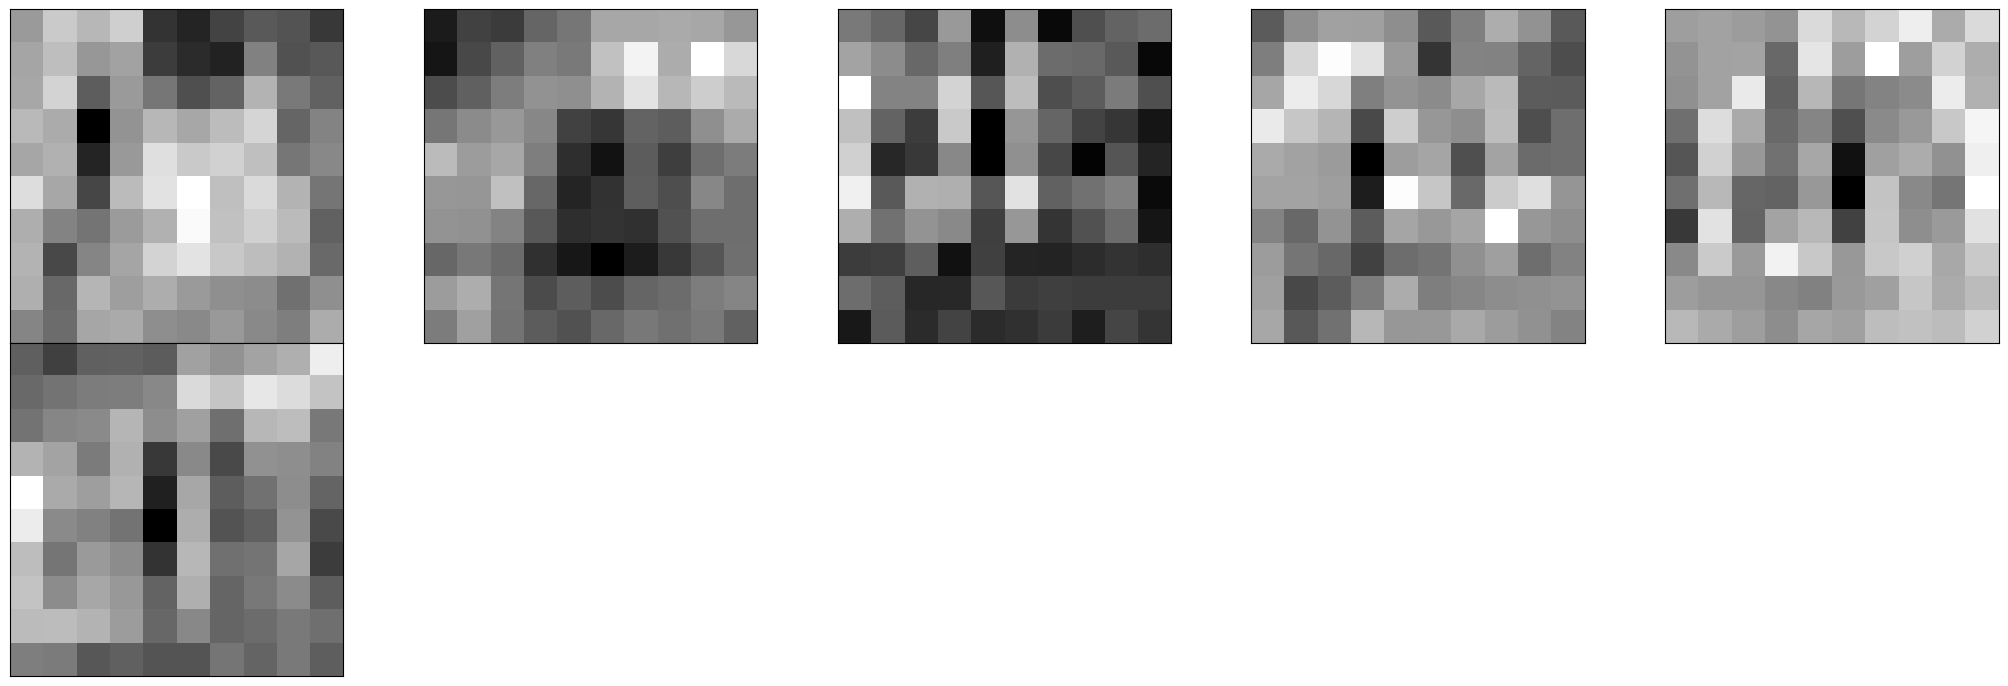

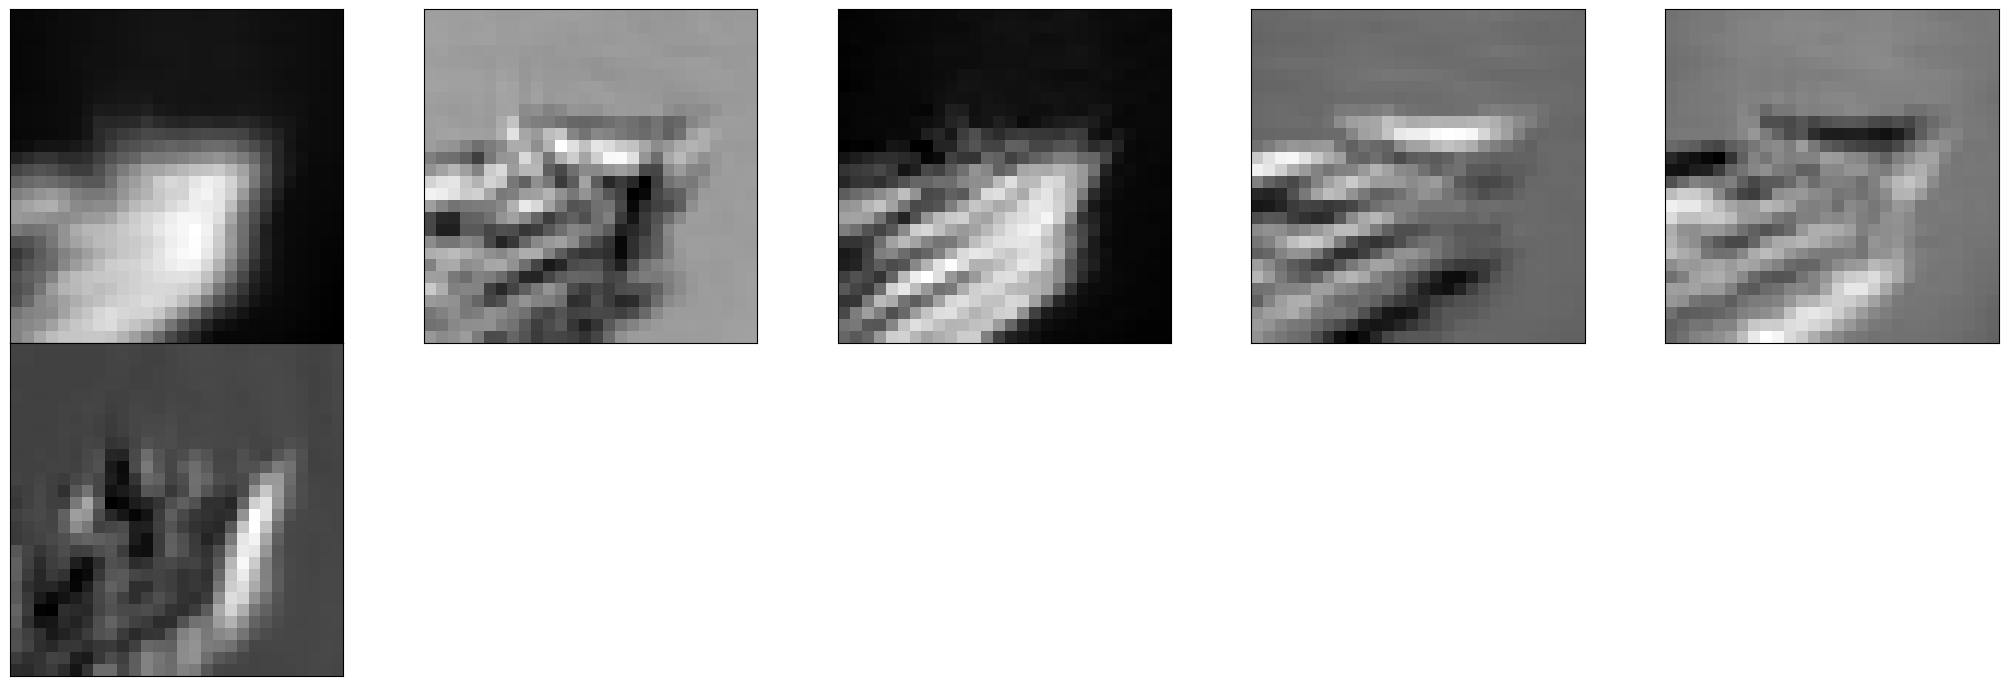

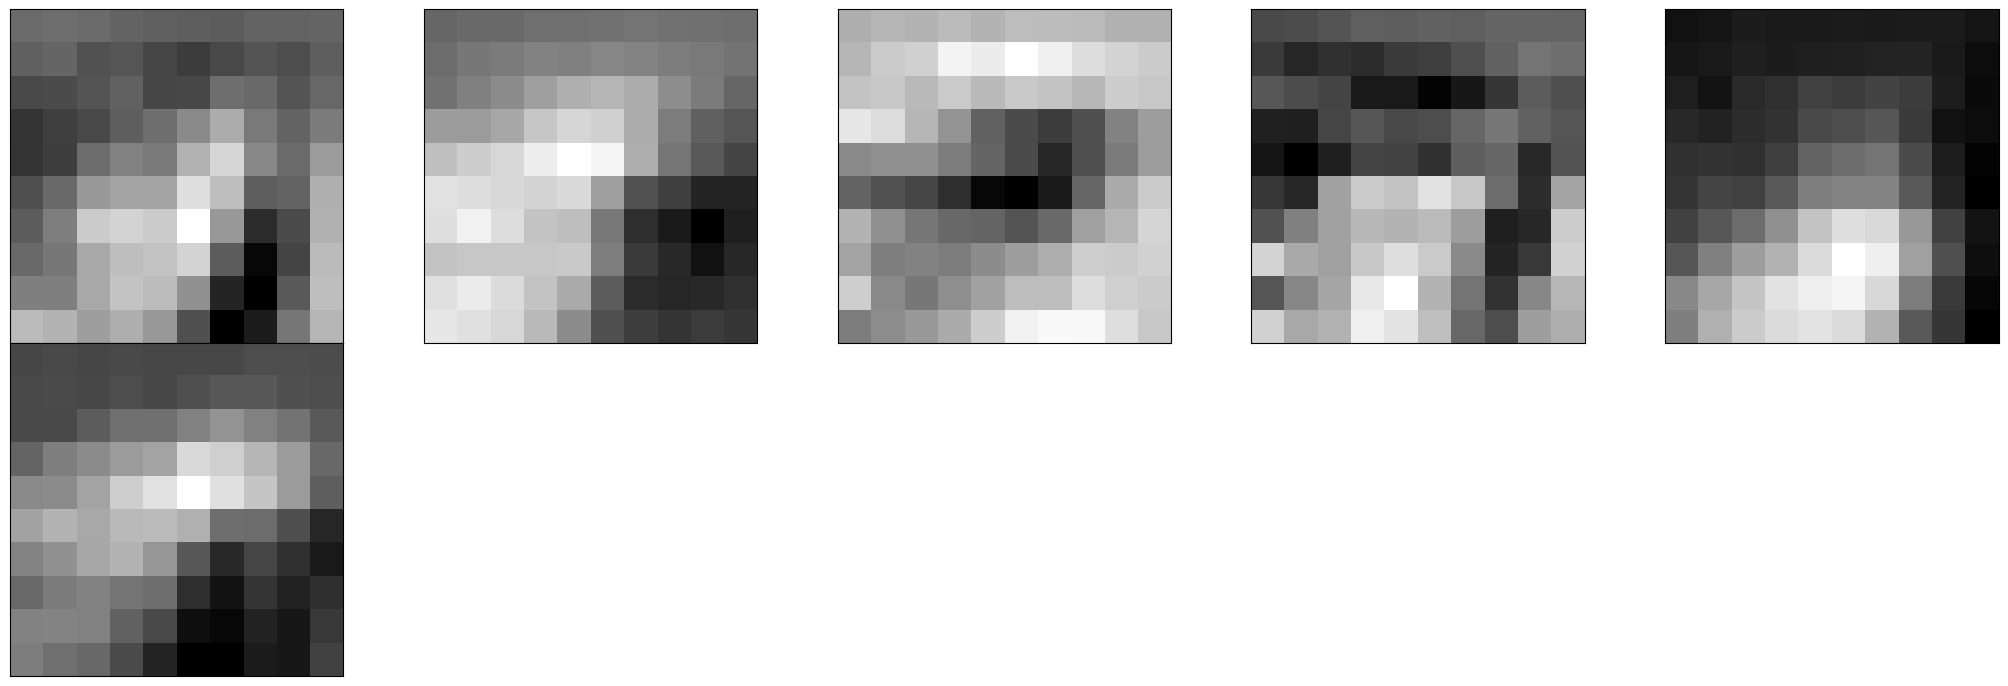

In [56]:
for images, targets in test_loader:
    act= getActivations(model_cnn, model_cnn.conv1, images.to(device))
    act2= getActivations(model_cnn, model_cnn.conv2, images.to(device))
    
    fig = plt.figure(figsize=(20,50))
    fig.subplots_adjust(left=0,right=1,bottom=0,top=0.8,hspace=0, wspace=0.2)
    for i in range(n_features):
        ax = fig.add_subplot(12,5,i+1,xticks=[],yticks=[])
        ax.imshow(act[0][i].cpu().detach().numpy(), cmap=plt.get_cmap('gray'))

    fig = plt.figure(figsize=(20,50))
    fig.subplots_adjust(left=0,right=1,bottom=0,top=0.8,hspace=0, wspace=0.2)
    for i in range(n_features):
        ax = fig.add_subplot(12,5,i+1,xticks=[],yticks=[])
        ax.imshow(act2[0][i].cpu().detach().numpy(), cmap=plt.get_cmap('gray'))

> **Ques 1**: Do you think that it is possible to add a third convolution layer to the current model? If not, what would be the ideal solution to be able to add another layer?

> **Ans 1**: with kernel size = 5, if we add a convolution layer to the model and we follow it by max pooling as in the previous cases, we will have size 0 images to work on. Without the max pooling, we will have images of 1 single pixel, which is not enough. Ideally, we could add a new layer if we reduce the size of the kernel.

> **Task 4**: Considering your previous answer, try to add a third convolution layer to the model and inspect the feature maps for this new layer. Do you think that this would be a useful addition to the network?

> **Ans**: setting K to 3, solution below. Even like this, the information is too compressed to be used in a meaningful way.

In [71]:
class CNN(nn.Module):
    def __init__(self, input_size, n_feature, output_size):
        super().__init__()
        #insert your code here
        K=3
        self.n_feature=n_feature
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=n_feature, kernel_size=K)
        self.conv2 = nn.Conv2d(n_feature, n_feature, kernel_size=K)
        self.conv3 = nn.Conv2d(n_feature, n_feature, kernel_size=K)
        self.fc1 = nn.Linear(n_feature*4, 50)
        self.fc2 = nn.Linear(50, 10)
        
        
    def forward(self, x, verbose=False):
        #initial dimensions for x will be [100, 3, 32, 32]
        #insert your code here
        x = self.conv1(x) #[100, 6, 30, 30]
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2) #[100, 6, 15, 15]
        x = self.conv2(x) #[100, 6, 13, 13]
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2) #[100, 6, 6, 6]
        x = self.conv3(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)
        x = x.view(-1, self.n_feature*4)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
    
        output = F.log_softmax(x, dim=1)
        
        return output

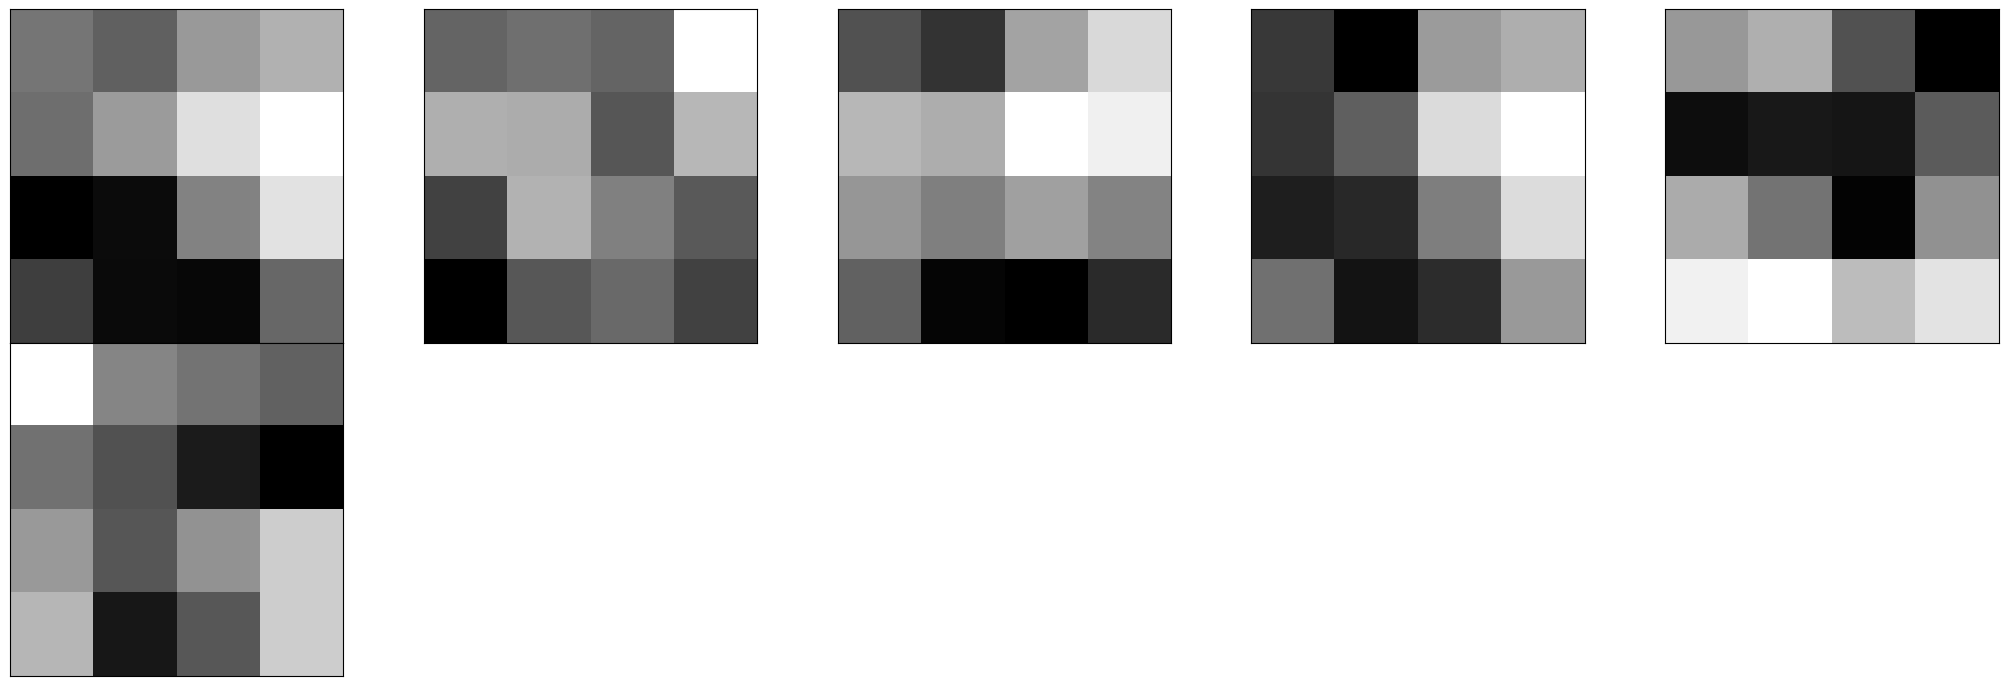

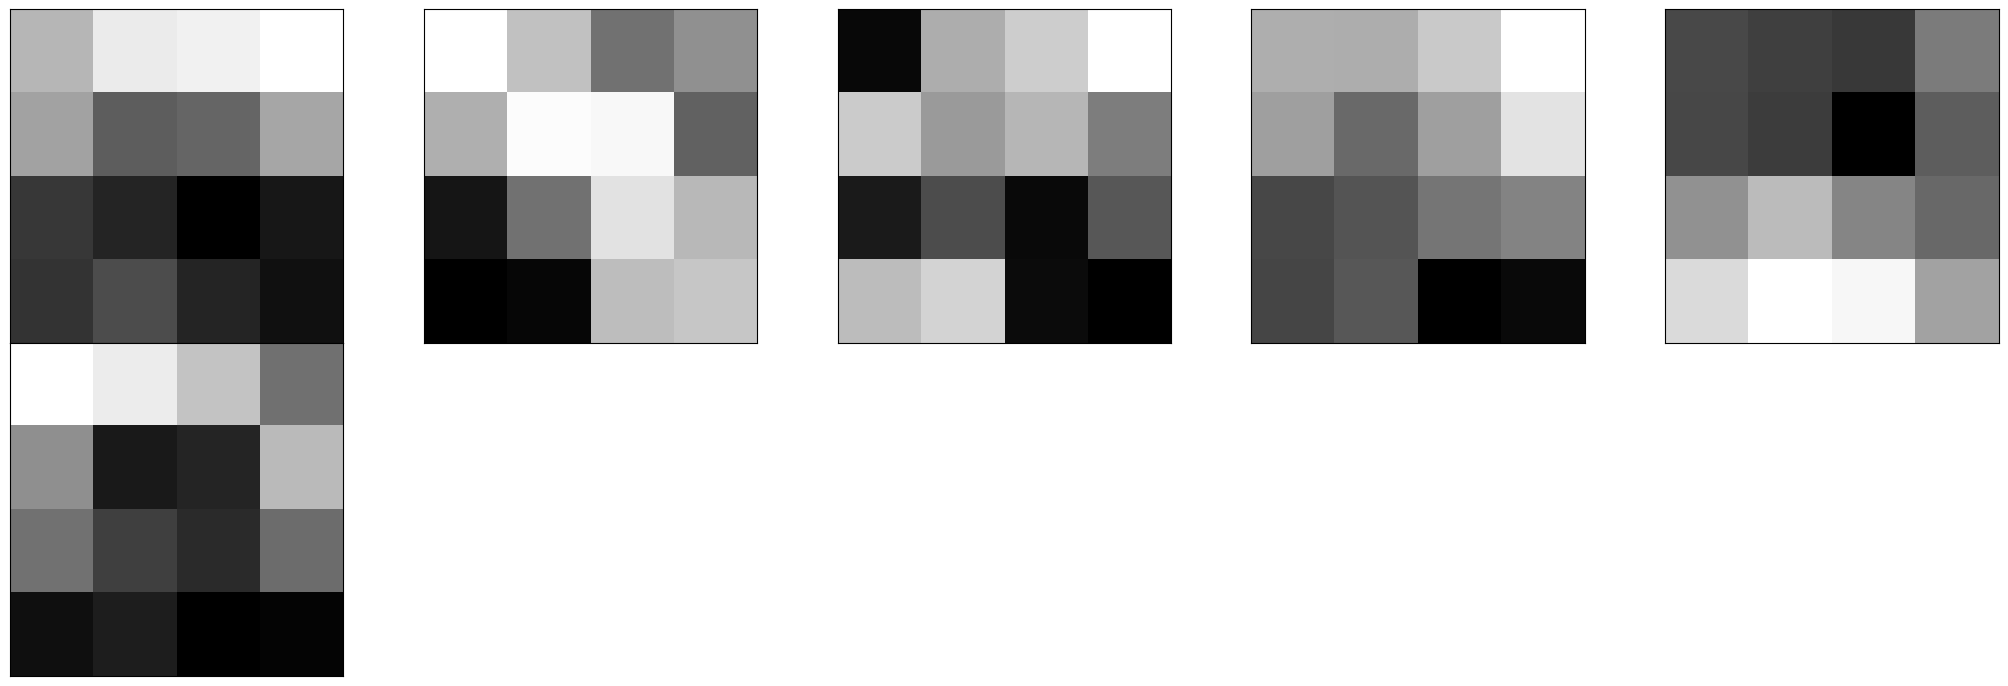

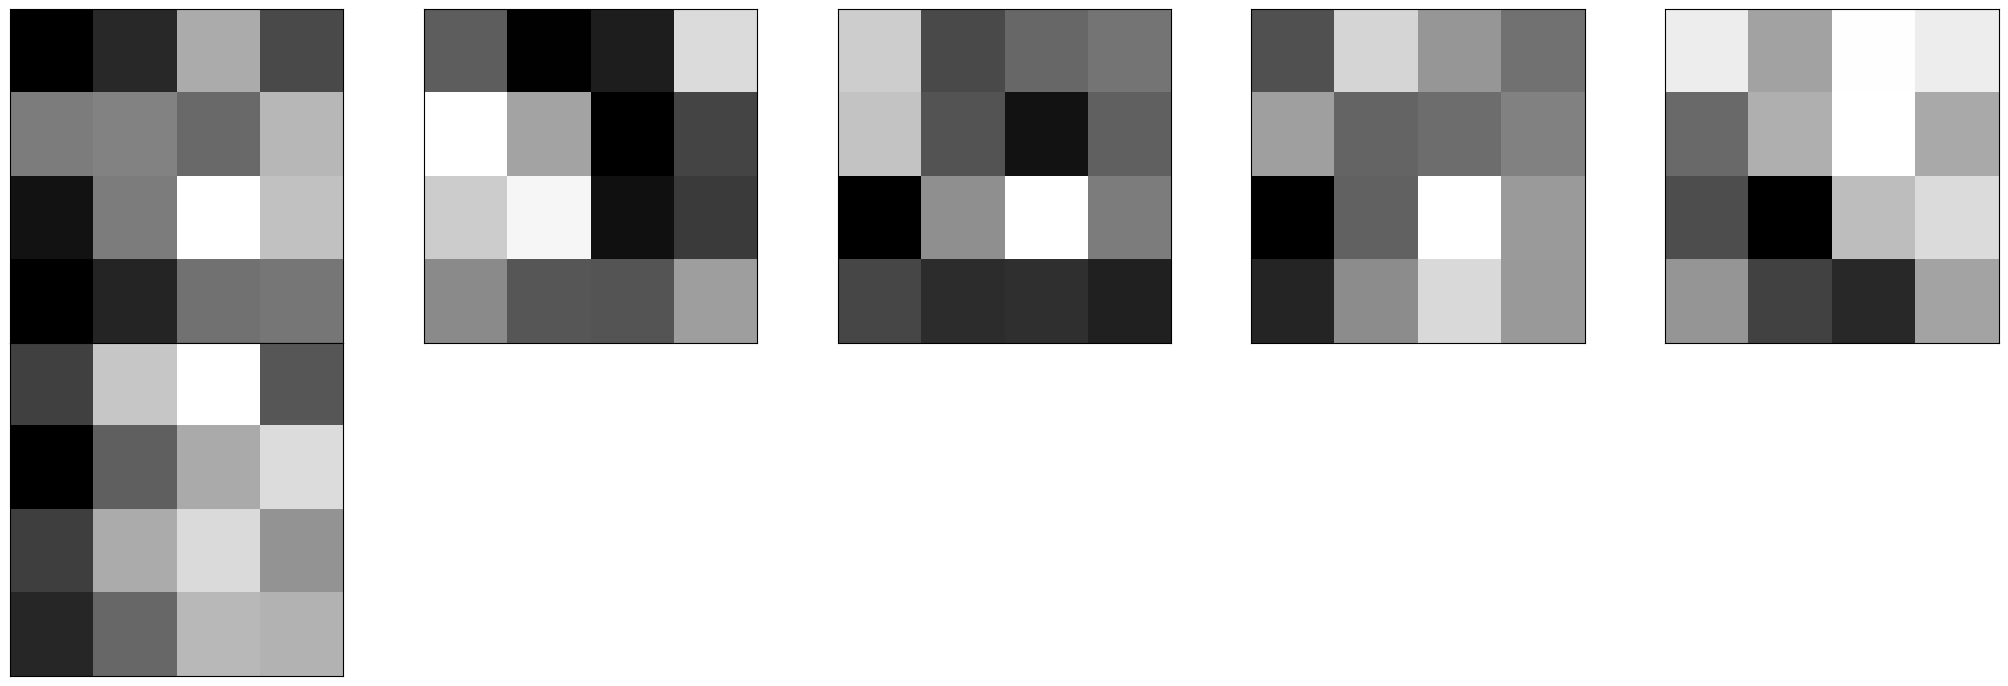

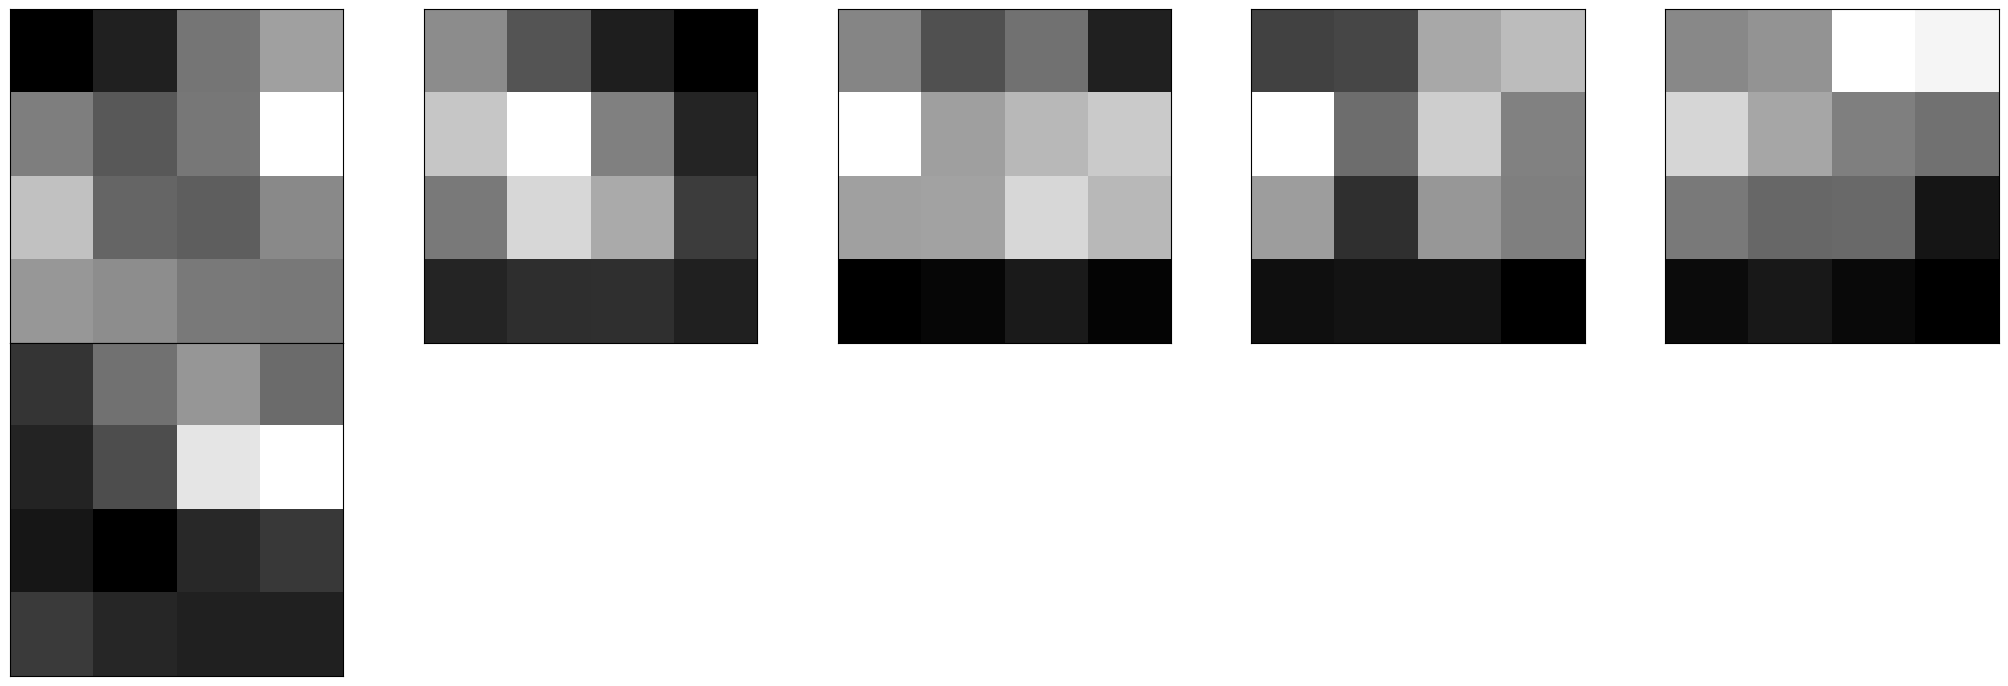

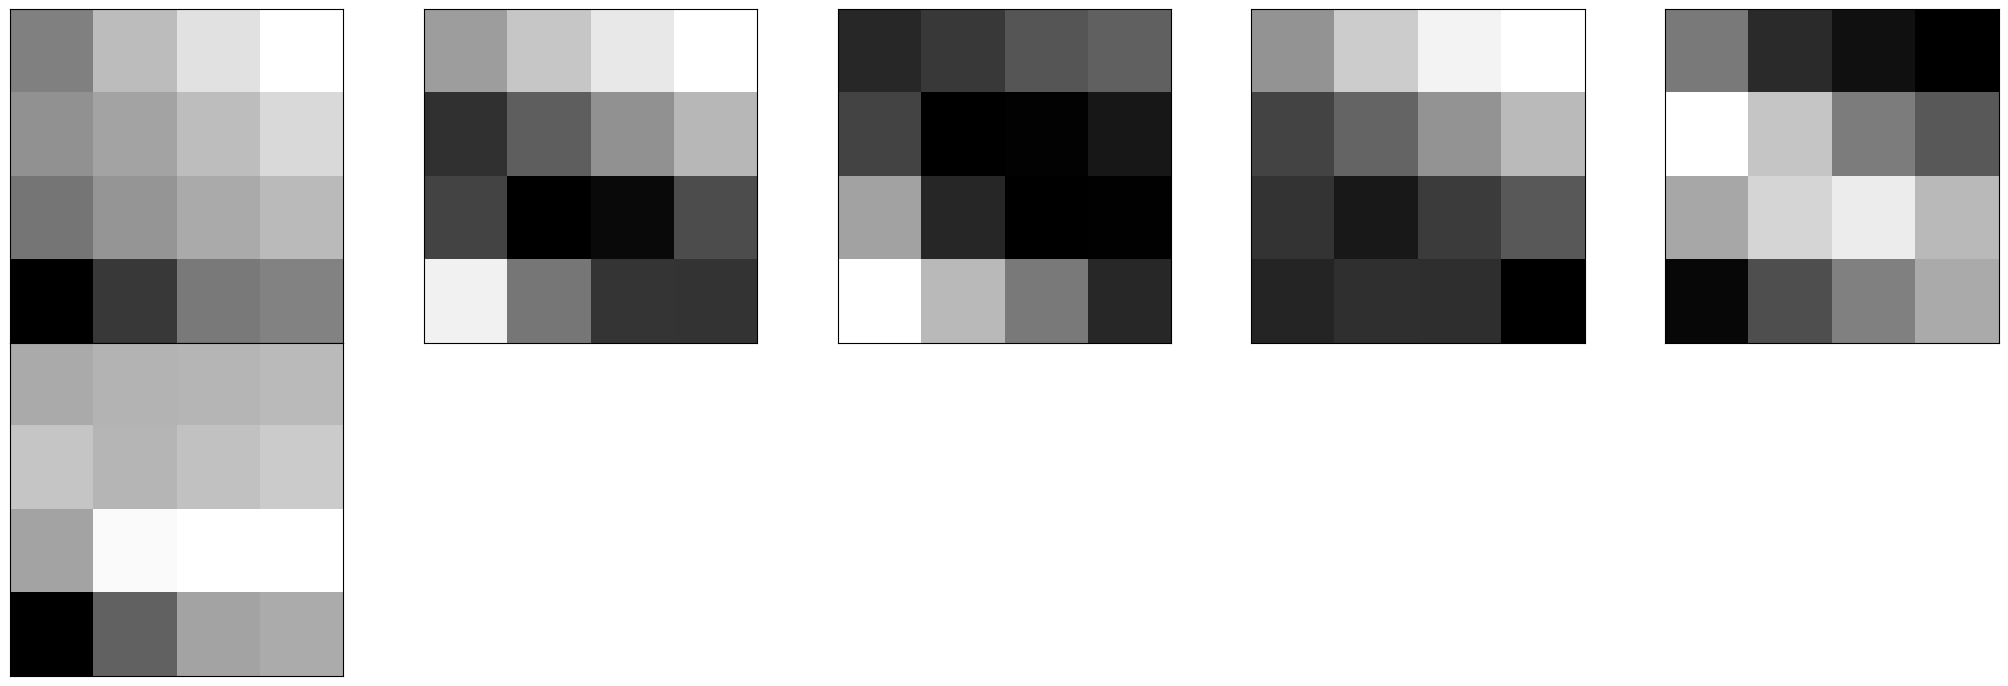

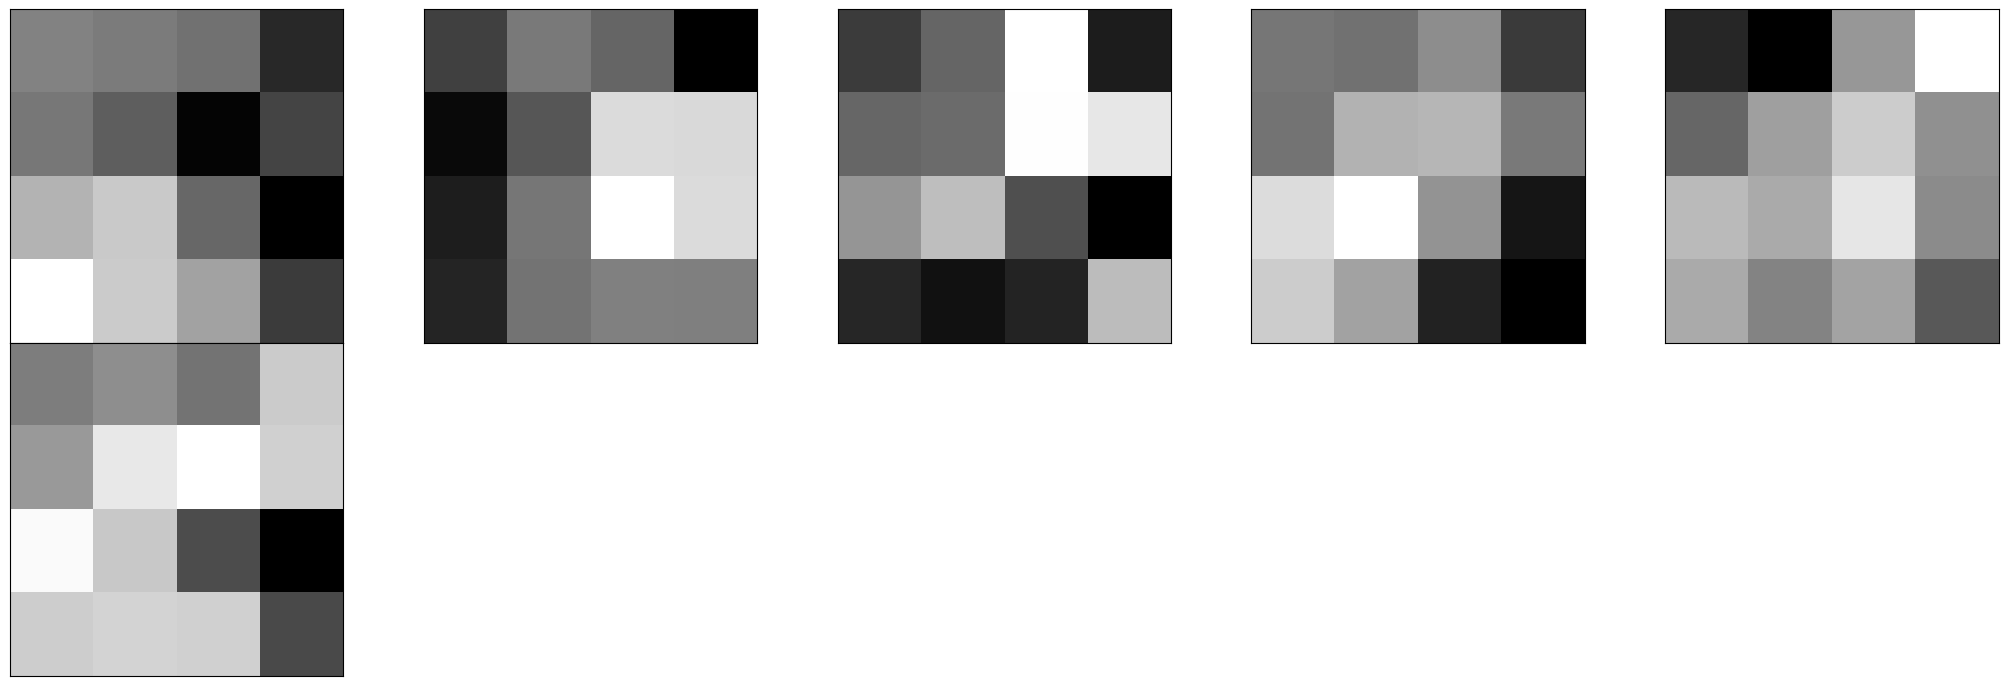

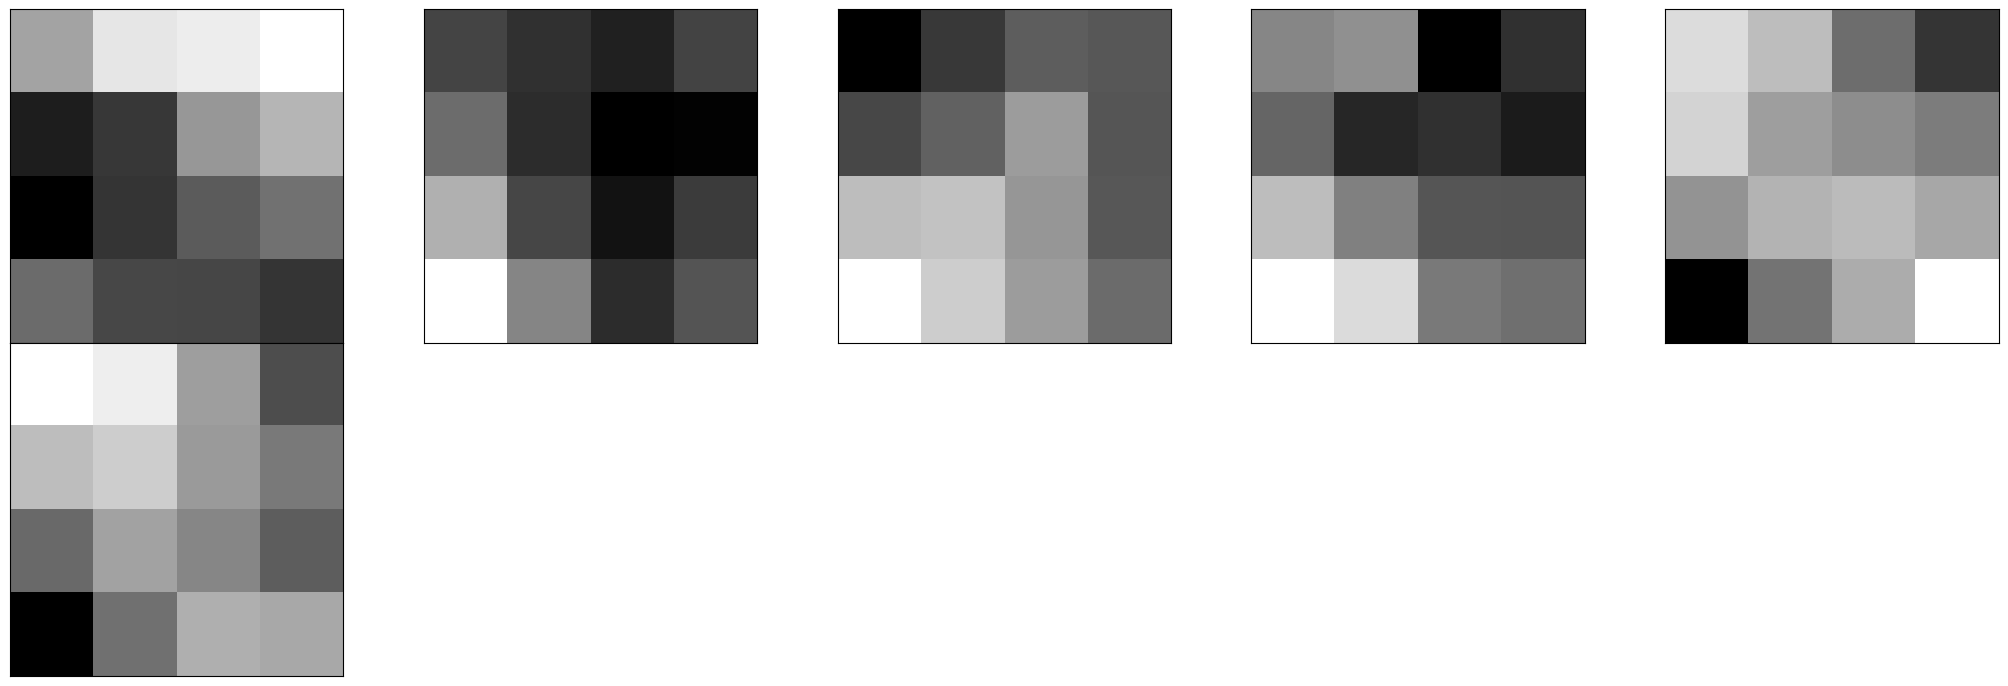

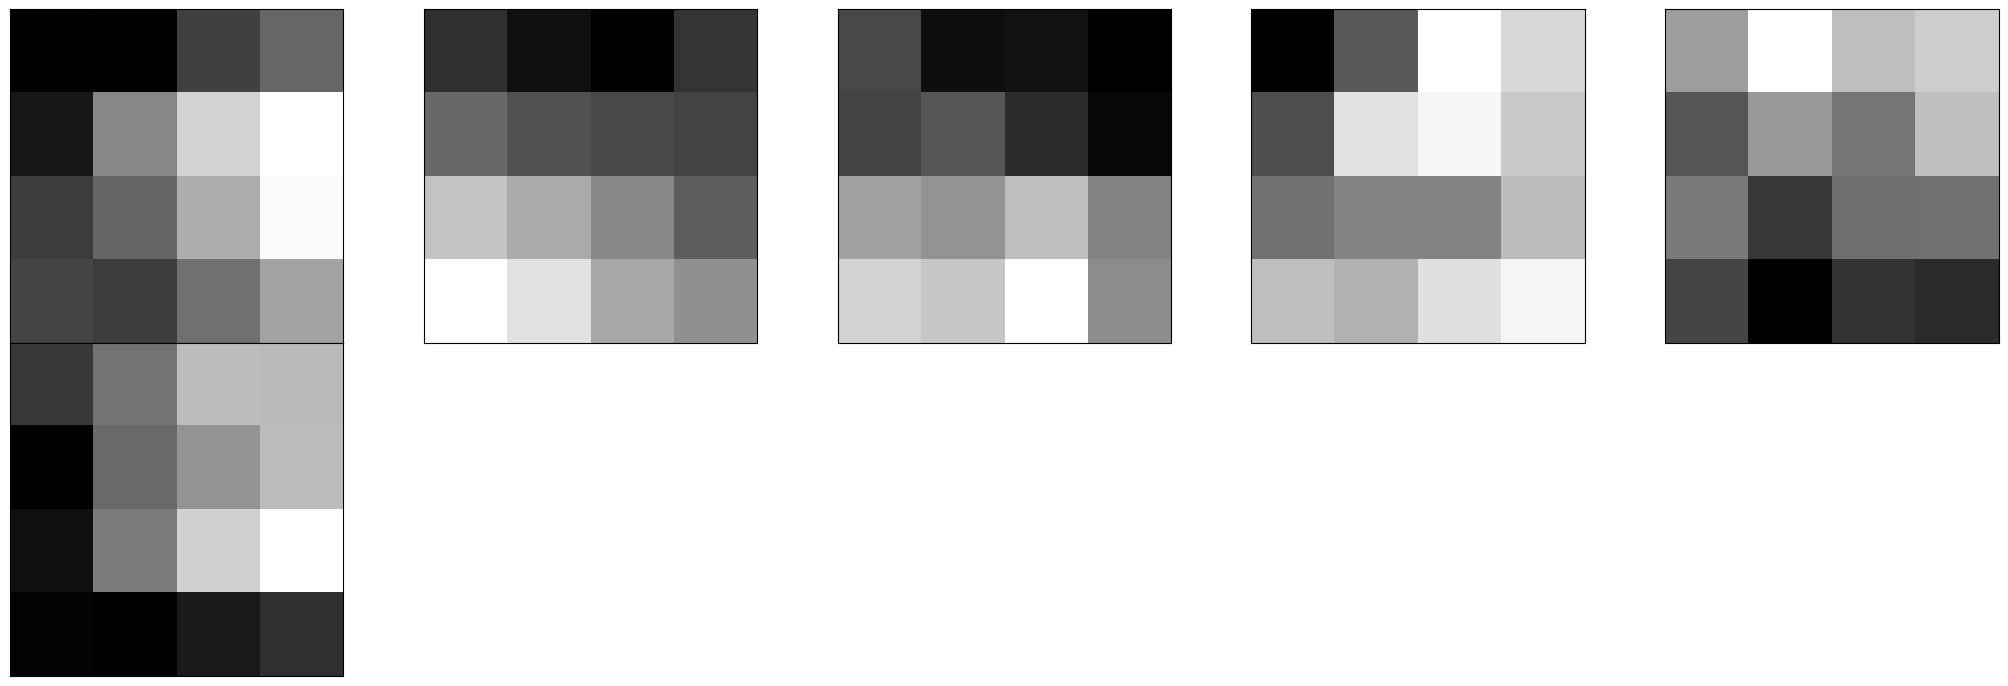

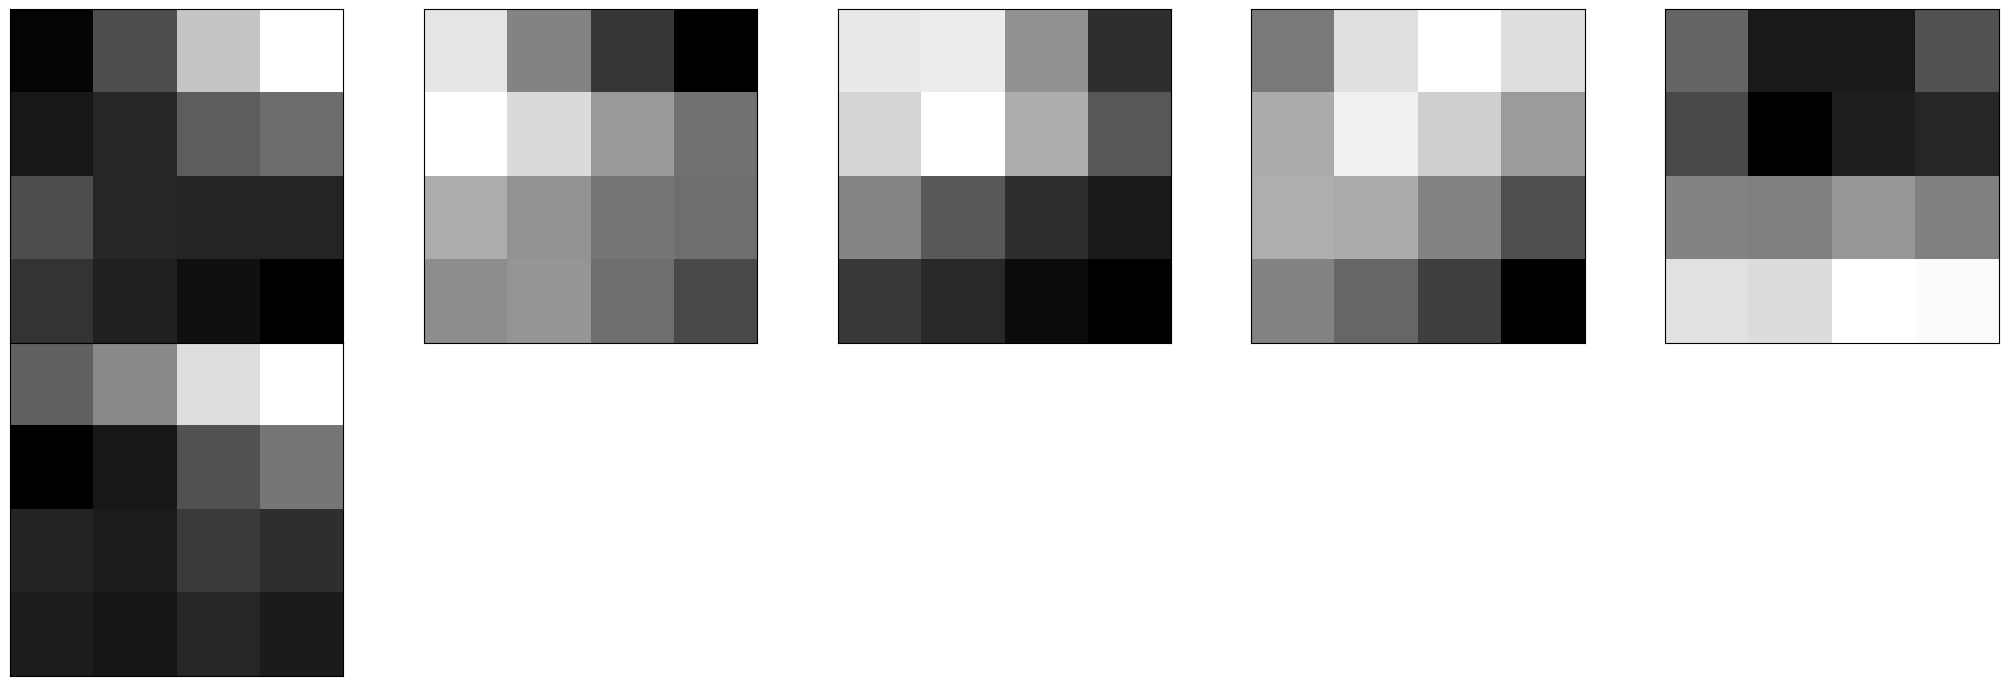

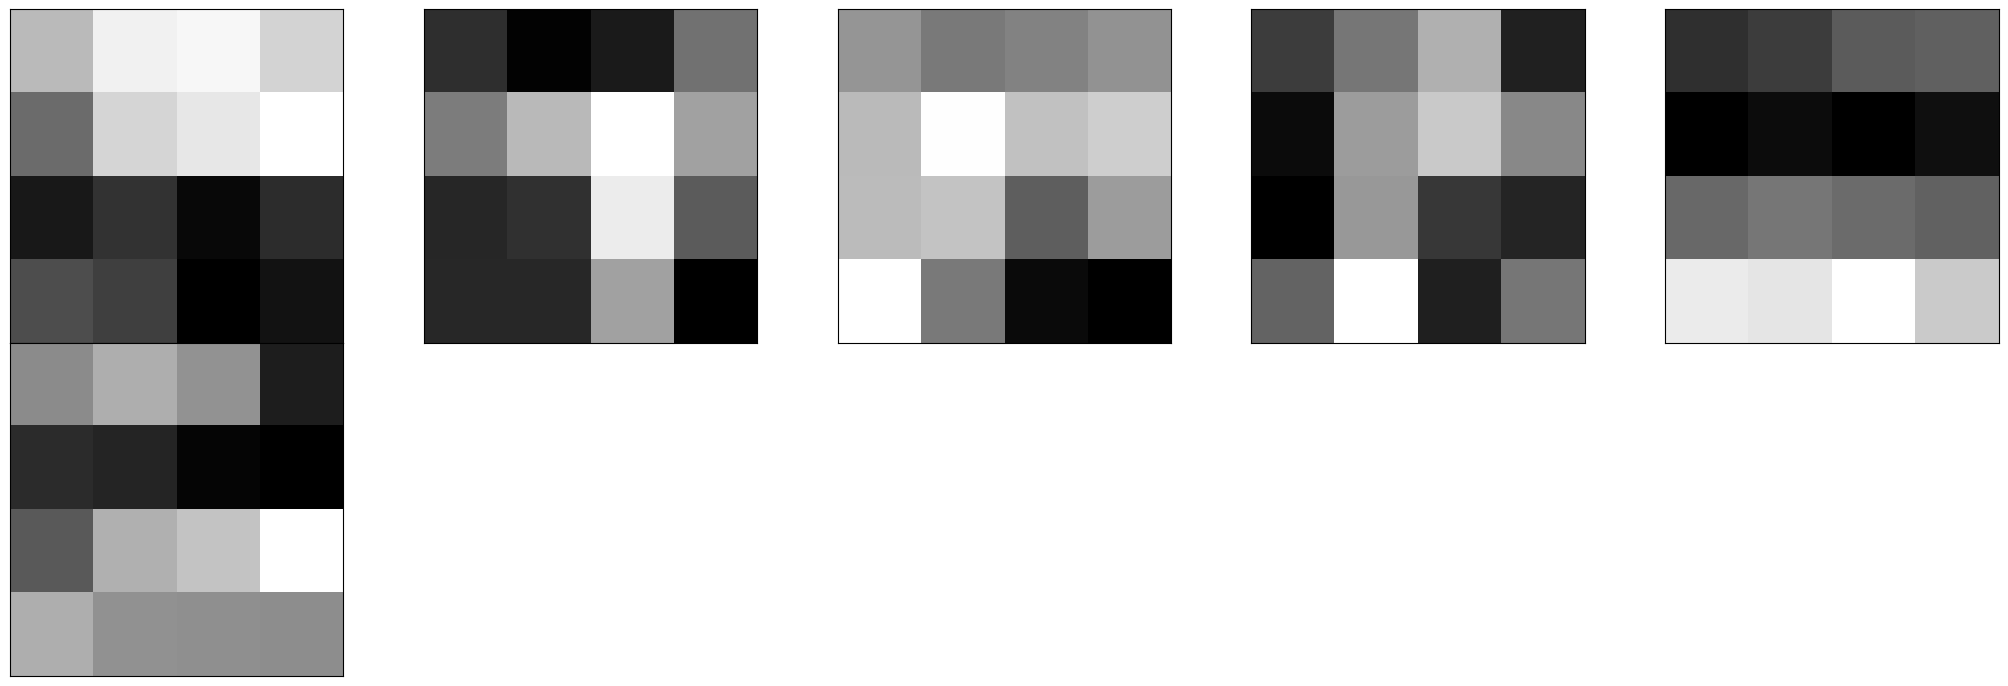

In [73]:
for images, targets in test_loader:
    act= getActivations(model_cnn, model_cnn.conv3, images.to(device))
    
    fig = plt.figure(figsize=(20,50))
    fig.subplots_adjust(left=0,right=1,bottom=0,top=0.8,hspace=0, wspace=0.2)
    for i in range(n_features):
        ax = fig.add_subplot(12,5,i+1,xticks=[],yticks=[])
        ax.imshow(act[0][i].cpu().detach().numpy(), cmap=plt.get_cmap('gray'))

>**Task 5:** Revert to the architecture with 2 layers and test the model with 10 and 20 feature maps. Verify the effect on the accuracy and inspect the feature maps activations.

In [ ]:
n_features = 6 # number of feature maps

model_cnn = CNN(input_size, n_features, output_size)
model_cnn.to(device)
optimizer = torch.optim.SGD(model_cnn.parameters(), lr=0.01, momentum=0.5)

for epoch in range(0, 2):
    train(model_cnn, device, train_loader, optimizer, epoch)
    test(model_cnn, device, test_loader)

>**Task 6:** Try to tune the model by varying the learning rate and the number of epochs